In [1]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# EDA

In [3]:
OUTPUT_DIR = Path('./eda_results')
FIGURES_DIR = OUTPUT_DIR / 'figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv('./data/2025-08-04_anon.csv')

In [4]:
df.shape

(877590, 38)

In [5]:
df.columns

Index(['flow_start_time', 'flow_end_time', 'session_id', 'source_ipv4',
       'source_ipv6', 'source_port', 'bgp_source_as_number',
       'destination_ipv4', 'destination_ipv6', 'destination_port',
       'bgp_destination_as_number', 'login', 'source_asnum',
       'destination_asnum', 'source_astitle', 'destination_astitle',
       'subscriber', 'host_ip', 'host', 'net_protocol',
       'app_protocol_group_id', 'app_protocol_group', 'app_protocol',
       'octet_delta_count', 'packet_delta_count', 'frgmt_delta_packs',
       'repeat_delta_pack', 'packet_deliver_time', 'flow_start_millisecond',
       'flow_end_millisecond', 'ip_class_of_service', 'input_snmp',
       'output_snmp', 'ip_version', 'post_nat_source_ipv4',
       'post_nat_source_port', 'bridge_vchannel', 'dpi_id'],
      dtype='str')

In [6]:
TRAFFIC_NUMERIC_COLUMNS = [
    'octet_delta_count',
    'packet_delta_count',
    'frgmt_delta_packs',
    'repeat_delta_pack',
    'packet_deliver_time',
]

In [7]:
CORRELATION_COLUMNS = TRAFFIC_NUMERIC_COLUMNS + ['duration_ms']

In [8]:
column_info = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null_count': df.notna().sum(),
    'missing_count': df.isna().sum(),
    'unique_count': df.nunique(dropna=False),
})
column_info.index.name = 'column'
display(column_info)
column_info.to_csv(OUTPUT_DIR / 'column_info.csv', encoding='utf-8-sig')

display(df.head(10))

,dtype,non_null_count,missing_count,unique_count
column,,,,
flow_start_time,str,877590,0,53981
flow_end_time,str,877590,0,55091
session_id,int64,877590,0,466753
source_ipv4,str,877590,0,23146
source_ipv6,str,877590,0,1
source_port,int64,877590,0,55916
bgp_source_as_number,int64,877590,0,3131
destination_ipv4,str,877590,0,29435
destination_ipv6,str,877590,0,1


,flow_start_time,flow_end_time,session_id,source_ipv4,source_ipv6,source_port,bgp_source_as_number,destination_ipv4,destination_ipv6,destination_port,...,flow_start_millisecond,flow_end_millisecond,ip_class_of_service,input_snmp,output_snmp,ip_version,post_nat_source_ipv4,post_nat_source_port,bridge_vchannel,dpi_id
0,2025-08-04 07:57:35,2025-08-04 08:02:35,4701330521067656546,org_ip,::,50544,12406,ip-12,::,9003,...,1754283455183,1754283755733,0,1,2,4,0,0,12_BN_ISP,110
1,2025-08-04 08:58:45,2025-08-04 08:58:55,3001330523967197970,org_ip,::,52244,12406,ip-1,::,443,...,1754287125314,1754287135308,0,1,2,4,0,0,12_BN_ISP,106
2,2025-08-04 08:58:45,2025-08-04 08:58:55,3001330523967197970,ip-1,::,443,13238,org_ip,::,52244,...,1754287125314,1754287135308,0,2,1,4,0,0,12_BN_ISP,106
3,2025-08-04 08:58:45,2025-08-04 08:58:47,3901330522821750024,org_ip,::,58140,12406,ip-2,::,443,...,1754287125326,1754287127169,0,1,2,4,0,0,12_BN_ISP,108
4,2025-08-04 08:58:45,2025-08-04 08:58:47,3901330522821750024,ip-2,::,443,29209,org_ip,::,58140,...,1754287125326,1754287127169,0,2,1,4,0,0,12_BN_ISP,108
5,2025-08-04 08:58:12,2025-08-04 08:58:35,3401330523777993702,org_ip,::,41775,12406,ip-1078,::,443,...,1754287092741,1754287115547,0,1,2,4,0,0,12_BN_ISP,104
6,2025-08-04 08:58:12,2025-08-04 08:58:24,3701330522903323734,org_ip,::,49143,12406,ip-3,::,443,...,1754287092758,1754287104080,0,1,2,4,0,0,12_BN_ISP,109
7,2025-08-04 08:58:12,2025-08-04 08:58:24,3701330522903323734,ip-3,::,443,44066,org_ip,::,49143,...,1754287092758,1754287104080,0,2,1,4,0,0,12_BN_ISP,109
8,2025-08-04 08:29:53,2025-08-04 08:29:58,4101330521085397383,org_ip,::,36401,12406,ip-384,::,443,...,1754285393302,1754285398912,0,1,2,4,0,0,12_BN_ISP,110
9,2025-08-04 08:59:17,2025-08-04 09:01:53,1301330527328729256,ip-4,::,443,208677,org_ip,::,50428,...,1754287157594,1754287313663,0,2,1,4,0,0,12_BN_ISP,107


In [9]:
time_rows = []
for column in ['flow_start_time', 'flow_end_time']:
    if column in df.columns:
        parsed = pd.to_datetime(df[column], errors='coerce')
        time_rows.append({
            'column': column,
            'min': parsed.min(),
            'max': parsed.max(),
            'unparseable_count': int(parsed.isna().sum()),
        })

time_info = pd.DataFrame(time_rows).set_index('column') if time_rows else pd.DataFrame()
display(time_info)
if not time_info.empty:
    time_info.to_csv(OUTPUT_DIR / 'time_range.csv', encoding='utf-8-sig')

,min,max,unparseable_count
column,,,
flow_start_time,2025-08-04 07:57:35,2025-08-04 23:59:59,0
flow_end_time,2025-08-04 08:01:38,2025-08-05 00:04:49,0


In [10]:
missing_count = df.isna().sum()
missing_info = pd.DataFrame({
    'missing_count': missing_count,
    'missing_percent': missing_count / len(df) * 100,
}).sort_values('missing_count', ascending=False)

missing_info.index.name = 'column'
display(missing_info[missing_info['missing_count'] > 0])
missing_info.to_csv(OUTPUT_DIR / 'missing_values_all_columns.csv', encoding='utf-8-sig')

print(f"Features with missings: {(missing_count > 0).sum()} из {df.shape[1]}")
print(f"Full missing features: {missing_count[missing_count == len(df)].index.tolist()}")

,missing_count,missing_percent
column,,
login,877590,100.000000
host,341748,38.941647
destination_astitle,5,0.000570


Features with missings: 3 из 38
Full missing features: ['login']


In [12]:
nunique_all = df.nunique(dropna=False)
constant_columns = nunique_all[nunique_all == 1].index.tolist()

constant_rows = []
for column in constant_columns:
    values = df[column].drop_duplicates()
    only_value = values.iloc[0] if len(values) else '<только пропуски>'
    constant_rows.append({
        'column': column,
        'unique_value': only_value,
        'is_entirely_missing': bool(df[column].isna().all()),
    })

constant_info = pd.DataFrame(constant_rows)
display(constant_info)
constant_info.to_csv(OUTPUT_DIR / 'constant_columns.csv', index=False, encoding='utf-8-sig')
print(f'Amount const/all missing features: {len(constant_columns)}')

,column,unique_value,is_entirely_missing
0,source_ipv6,::,False
1,destination_ipv6,::,False
2,login,NaN,True
3,source_asnum,12406,False
4,source_astitle,"BN-AS Business Network Ltd, BY",False
5,subscriber,org_ip,False
6,ip_version,4,False
7,post_nat_source_ipv4,0,False
8,post_nat_source_port,0,False
9,bridge_vchannel,12_BN_ISP,False


Amount const/all missing features: 10


In [13]:
exact_duplicates = int(df.duplicated().sum())
print(f'Full duplicated rows: {exact_duplicates:,}')

Full duplicated rows: 0


In [14]:
if 'net_protocol' in df.columns:
    protocol_info = (
        df['net_protocol'].fillna('miss')
        .value_counts(dropna=False)
        .rename_axis('net_protocol')
        .to_frame('count')
    )
    protocol_info['percent'] = protocol_info['count'] / len(df) * 100
    display(protocol_info)
    protocol_info.to_csv(OUTPUT_DIR / 'net_protocol_distribution.csv', encoding='utf-8-sig')
else:
    print('Столбец net_protocol отсутствует.')

,count,percent
net_protocol,,
TCP 6,731645,83.369797
UDP 17,138773,15.812965
ICMP 1,7170,0.817010
IPv6 41,1,0.000114
GRE 47,1,0.000114


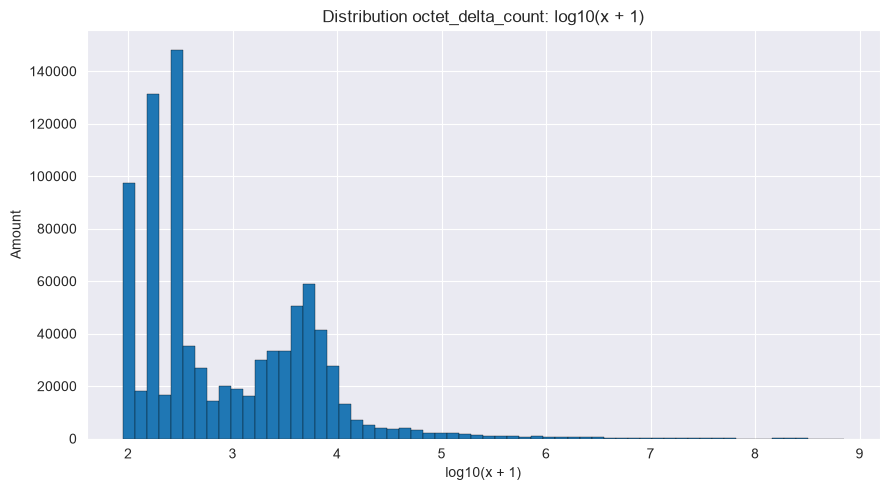

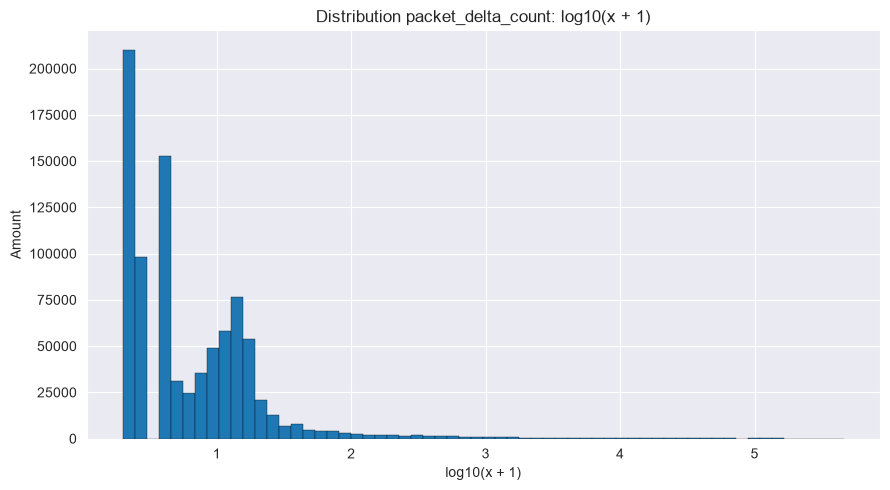

In [15]:
histogram_columns = ['octet_delta_count', 'packet_delta_count', 'duration_ms']

for column in histogram_columns:
    if column not in df.columns:
        continue

    values = pd.to_numeric(df[column], errors='coerce').dropna()
    values = values[values >= 0]
    if values.empty:
        print(f'{column}: no negative values.')
        continue

    transformed = np.log10(values + 1)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(transformed, bins=60, edgecolor='black', linewidth=0.25)
    ax.set_title(f'Distribution {column}: log10(x + 1)')
    ax.set_xlabel('log10(x + 1)')
    ax.set_ylabel('Amount')
    plt.tight_layout()
    fig.savefig(FIGURES_DIR / f'04_hist_{column}.png', dpi=160, bbox_inches='tight')
    plt.show()

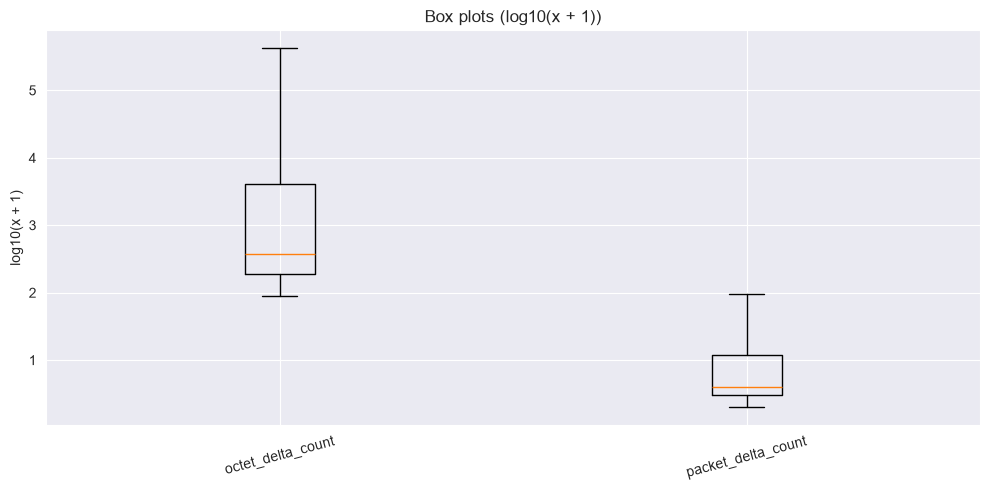

In [19]:
box_columns = [
    c for c in ['octet_delta_count', 'packet_delta_count', 'duration_ms']
    if c in df.columns
]

box_data = []
box_labels = []

for column in box_columns:
    values = pd.to_numeric(df[column], errors='coerce').dropna()
    values = values[values >= 0]

    if not values.empty:
        box_data.append(np.log10(values + 1).to_numpy())
        box_labels.append(column)

if box_data:
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.boxplot(
        box_data,
        tick_labels=box_labels,
        showfliers=False
    )

    ax.set_title('Box plots (log10(x + 1))')
    ax.set_ylabel('log10(x + 1)')
    ax.tick_params(axis='x', rotation=15)

    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / '05_boxplots_log_scale.png',
        dpi=160,
        bbox_inches='tight'
    )
    plt.show()
else:
    print('No info for boxplot.')

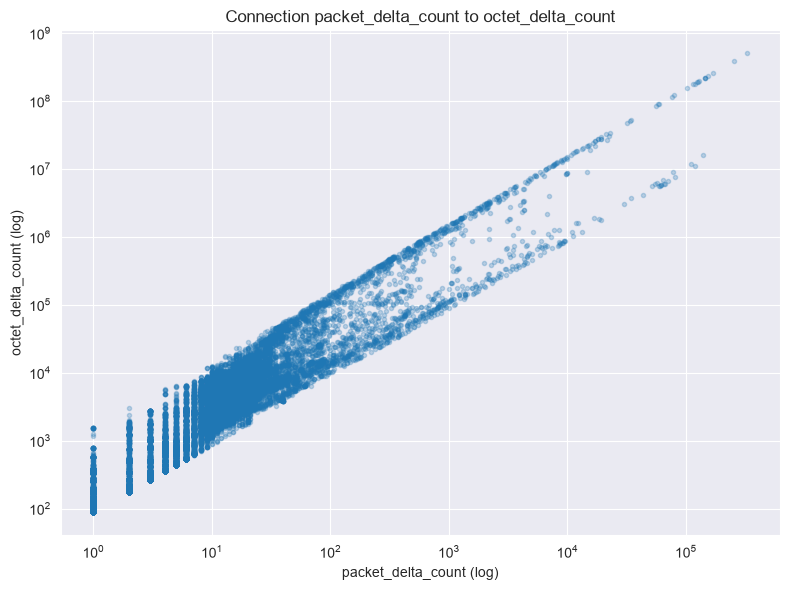

Amount samples: 50,000


In [20]:
if {'octet_delta_count', 'packet_delta_count'}.issubset(df.columns):
    scatter_data = pd.DataFrame({
        'packet_delta_count': pd.to_numeric(df['packet_delta_count'], errors='coerce'),
        'octet_delta_count': pd.to_numeric(df['octet_delta_count'], errors='coerce'),
    })
    scatter_data = scatter_data.dropna()
    scatter_data = scatter_data[
        (scatter_data['packet_delta_count'] > 0) &
        (scatter_data['octet_delta_count'] > 0)
    ]

    if len(scatter_data) > 50_000:
        scatter_data = scatter_data.sample(n=50_000, random_state=42)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(
        scatter_data['packet_delta_count'],
        scatter_data['octet_delta_count'],
        alpha=0.25,
        s=9,
    )
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('Connection packet_delta_count to octet_delta_count')
    ax.set_xlabel('packet_delta_count (log)')
    ax.set_ylabel('octet_delta_count (log)')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '06_bytes_vs_packets.png', dpi=160, bbox_inches='tight')
    plt.show()
    print(f'Amount samples: {len(scatter_data):,}')
else:
    print('No info.')

In [21]:
corr_columns = [c for c in CORRELATION_COLUMNS if c in df.columns]

if len(corr_columns) >= 2:
    corr_data = df[corr_columns].apply(pd.to_numeric, errors='coerce').clip(lower=0)
    corr_data = np.log1p(corr_data)
    correlation_matrix = corr_data.corr(method='pearson')
    display(correlation_matrix)
    correlation_matrix.to_csv(OUTPUT_DIR / 'correlation_matrix.csv', encoding='utf-8-sig')
else:
    correlation_matrix = pd.DataFrame()
    print('No info.')

,octet_delta_count,packet_delta_count,frgmt_delta_packs,repeat_delta_pack,packet_deliver_time
octet_delta_count,1.000000,0.939860,0.009359,0.420087,0.219229
packet_delta_count,0.939860,1.000000,0.005402,0.470469,0.181925
frgmt_delta_packs,0.009359,0.005402,1.000000,0.009356,-0.002449
repeat_delta_pack,0.420087,0.470469,0.009356,1.000000,0.030948
packet_deliver_time,0.219229,0.181925,-0.002449,0.030948,1.000000


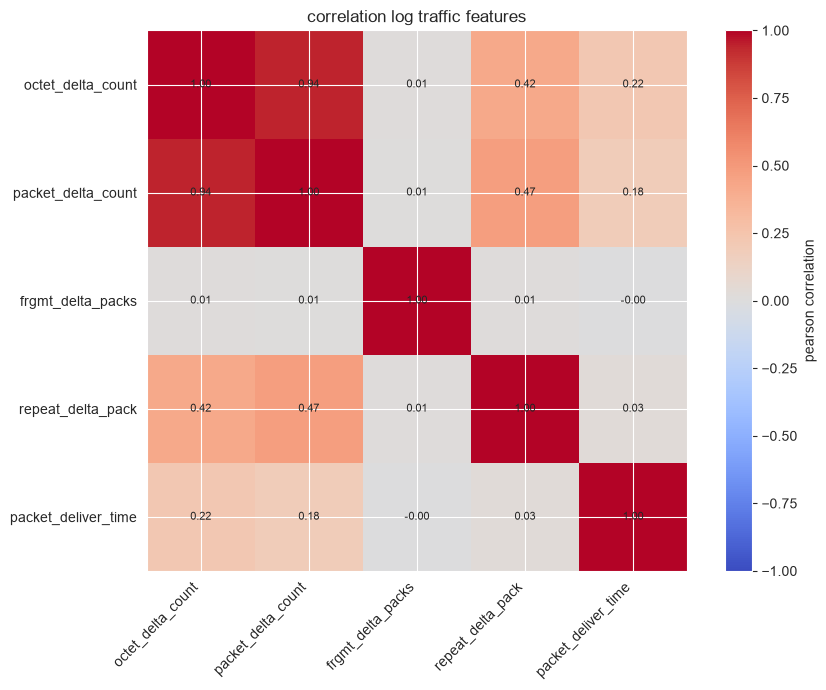

In [22]:
if not correlation_matrix.empty:
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(correlation_matrix, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(len(correlation_matrix.columns)))
    ax.set_yticks(range(len(correlation_matrix.index)))
    ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha='right')
    ax.set_yticklabels(correlation_matrix.index)

    for i in range(len(correlation_matrix.index)):
        for j in range(len(correlation_matrix.columns)):
            value = correlation_matrix.iloc[i, j]
            if pd.notna(value):
                ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8)

    ax.set_title('correlation log traffic features')
    fig.colorbar(image, ax=ax, label='pearson correlation')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / '07_correlation_matrix.png', dpi=160, bbox_inches='tight')
    plt.show()

## Feature Extraction

In [23]:
required_columns = [
    'flow_start_millisecond', 'flow_end_millisecond',
    'octet_delta_count', 'packet_delta_count',
    'frgmt_delta_packs', 'repeat_delta_pack', 'packet_deliver_time'
]
missing_required = [column for column in required_columns if column not in df.columns]
if missing_required:
    raise KeyError(f"Some features missing: {missing_required}")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

Dataset shape: 877,590 rows × 38 columns


In [25]:
all_missing_columns = [column for column in df.columns if df[column].isna().all()]

constant_columns_prep = [
    column for column in df.columns
    if df[column].nunique(dropna=False) <= 1
]

columns_to_exclude = sorted(set(all_missing_columns) | set(constant_columns_prep))

exclusion_reasons = []
for column in columns_to_exclude:
    reasons = []
    if column in all_missing_columns:
        reasons.append('fulll empty')
    if column in constant_columns_prep and column not in all_missing_columns:
        reasons.append('const')
    exclusion_reasons.append({'feature': column, 'reason': ', '.join(reasons)})

exclusion_table = pd.DataFrame(exclusion_reasons)
print(f"Full missing: {len(all_missing_columns)}")
print(f"Const columns (+ missing): {len(constant_columns_prep)}")
print(f"Total amount columns for drop: {len(columns_to_exclude)}")
display(exclusion_table)


Full missing: 1
Const columns (+ missing): 10
Total amount columns for drop: 10


,feature,reason
0,bridge_vchannel,const
1,destination_ipv6,const
2,ip_version,const
3,login,fulll empty
4,post_nat_source_ipv4,const
5,post_nat_source_port,const
6,source_asnum,const
7,source_astitle,const
8,source_ipv6,const
9,subscriber,const


In [26]:
missing_report = (
    df.isna().sum()
      .rename('miss_count')
      .to_frame()
      .assign(доля_пропусков=lambda x: (x['miss_count'] / len(df) * 100).round(3))
      .query('miss_count > 0')
      .sort_values('miss_count', ascending=False)
)
display(missing_report)


,miss_count,доля_пропусков
login,877590,100.000
host,341748,38.942
destination_astitle,5,0.001


In [27]:
start_ms = pd.to_numeric(df['flow_start_millisecond'], errors='coerce')
end_ms = pd.to_numeric(df['flow_end_millisecond'], errors='coerce')
duration_ms = end_ms - start_ms

duration_check = pd.Series({
    'flow missing count': int(duration_ms.isna().sum()),
    'negative duration': int((duration_ms < 0).sum()),
    'zero duration': int((duration_ms == 0).sum()),
    'min, ms': float(duration_ms.min()),
    'median, ms': float(duration_ms.median()),
    'max, ms': float(duration_ms.max()),
})
display(duration_check.to_frame('value'))

if duration_ms.isna().any() or (duration_ms < 0).any() or (duration_ms == 0).any():
    print("Some problems with durations.")
else:
    print("All okey.")


,value
flow missing count,0.0
negative duration,0.0
zero duration,0.0
"min, ms",1.0
"median, ms",3738.0
"max, ms",330918.0


All okey.


In [29]:
base_numeric_columns = [
    'octet_delta_count',
    'packet_delta_count',
    'frgmt_delta_packs',
    'repeat_delta_pack',
    'packet_deliver_time',
]

numeric_source = df[base_numeric_columns].apply(pd.to_numeric, errors='coerce')

In [30]:
quality_check = pd.DataFrame({
    'missing': numeric_source.isna().sum(),
    'negative values': (numeric_source < 0).sum(),
})
display(quality_check)

,missing,negative values
octet_delta_count,0,0
packet_delta_count,0,0
frgmt_delta_packs,0,0
repeat_delta_pack,0,0
packet_deliver_time,0,0


In [31]:
feature_raw = numeric_source.copy()
feature_raw['duration_ms'] = duration_ms
feature_raw['avg_packet_size_bytes'] = (
    numeric_source['octet_delta_count'] /
    numeric_source['packet_delta_count'].clip(lower=1)
)
feature_raw['packets_per_second'] = (
    numeric_source['packet_delta_count'] /
    (duration_ms / 1000).clip(lower=0.001)
)

print(f"Feature table shape: {feature_raw.shape[0]:,} rows × {feature_raw.shape[1]} columns")
display(feature_raw.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T)

Feature table shape: 877,590 rows × 8 columns


,count,mean,std,min,50%,90%,95%,99%,max
octet_delta_count,877590.0,110920.966174,4.191198e+06,88.00000,372.000000,7983.000000,14689.550000,331615.20000,708804849.0
packet_delta_count,877590.0,116.004271,3.116861e+03,1.00000,3.000000,19.000000,38.000000,623.00000,462228.0
frgmt_delta_packs,877590.0,0.000080,9.898959e-03,0.00000,0.000000,0.000000,0.000000,0.00000,2.0
repeat_delta_pack,877590.0,3.335178,1.459501e+02,0.00000,0.000000,1.000000,2.000000,11.00000,24906.0
packet_deliver_time,877590.0,108.957285,1.743134e+03,0.00000,0.000000,10.000000,19.000000,204.00000,109765.0
duration_ms,877590.0,17346.400637,3.959001e+04,1.00000,3738.000000,47397.200000,58726.000000,290787.22000,330918.0
avg_packet_size_bytes,877590.0,253.239226,2.380017e+02,88.00000,170.166667,548.000000,721.566014,1300.15339,1539.0
packets_per_second,877590.0,89.637447,5.753643e+02,0.00352,2.511121,142.857143,1000.000000,1000.00000,249000.0


In [32]:
sparsity_rows = []
for column in ['frgmt_delta_packs', 'repeat_delta_pack', 'packet_deliver_time']:
    values = pd.to_numeric(df[column], errors='coerce')
    sparsity_rows.append({
        'column': column,
        'zero values': int((values == 0).sum()),
        'unique values': int(values.nunique()),
        'max': float(values.max()),
    })

sparsity_table = pd.DataFrame(sparsity_rows).set_index('column')
display(sparsity_table)


,zero values,unique values,max
column,,,
frgmt_delta_packs,877528,3,2.0
repeat_delta_pack,758108,1100,24906.0
packet_deliver_time,573564,1782,109765.0


In [33]:
X_log = np.log1p(feature_raw)

if not np.isfinite(X_log.to_numpy()).all():
    raise ValueError("Some problems after transformation")

display(X_log.describe().T)


,count,mean,std,min,25%,50%,75%,max
octet_delta_count,877590.0,6.765300,1.886058,4.488636,5.241747,5.921578,8.322880,20.379091
packet_delta_count,877590.0,1.837483,1.179742,0.693147,1.098612,1.386294,2.484907,13.043816
frgmt_delta_packs,877590.0,0.000053,0.006369,0.000000,0.000000,0.000000,0.000000,1.098612
repeat_delta_pack,877590.0,0.166602,0.549963,0.000000,0.000000,0.000000,0.000000,10.122904
packet_deliver_time,877590.0,0.647021,1.271511,0.000000,0.000000,0.000000,0.693147,11.606106
duration_ms,877590.0,7.611054,2.923163,0.693147,6.165418,8.226573,9.902237,12.709629
avg_packet_size_bytes,877590.0,5.236376,0.727726,4.488636,4.553877,5.142638,5.818895,7.339538
packets_per_second,877590.0,1.826813,2.009631,0.003513,0.215920,1.255935,2.956264,12.425212


In [35]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X_scaled_array = scaler.fit_transform(X_log).astype('float32')
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X_log.columns,
    index=df.index
)

print(f"X_log: {X_log.shape[0]:,} × {X_log.shape[1]}")
print(f"X_scaled: {X_scaled.shape[0]:,} × {X_scaled.shape[1]}")
print(f"Missings: {X_scaled.isna().any().any()}")
print(f"All values are okey: {np.isfinite(X_scaled.to_numpy()).all()}")
display(X_scaled.head())


X_log: 877,590 × 8
X_scaled: 877,590 × 8
Missings: False
All values are okey: True


,octet_delta_count,packet_delta_count,frgmt_delta_packs,repeat_delta_pack,packet_deliver_time,duration_ms,avg_packet_size_bytes,packets_per_second
0,0.908764,1.522197,0.0,3.433987,0.000000,1.173939,0.093493,-0.421392
1,-0.443896,-0.500000,0.0,0.000000,1.000000,0.263129,-0.465417,-0.423513
2,-0.443896,-0.500000,0.0,0.000000,0.000000,0.263129,-0.465417,-0.423513
3,0.965113,1.123964,0.0,1.098612,3.700440,-0.189167,0.683418,0.408898
4,0.987080,1.084962,0.0,0.000000,3.584963,-0.189167,0.781886,0.390028


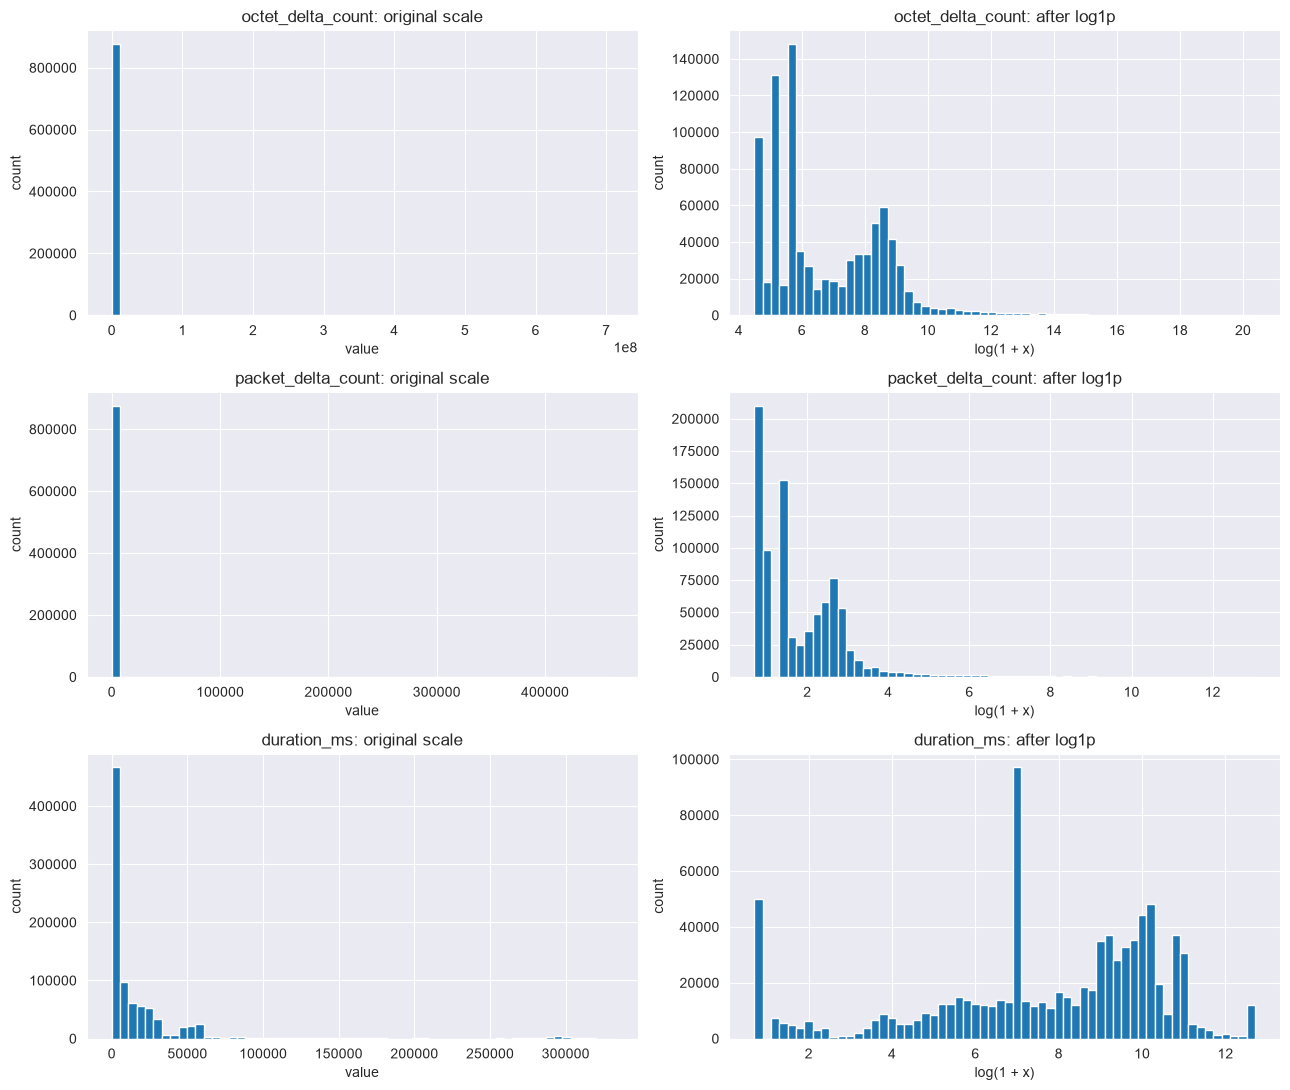

In [36]:
plot_columns = ['octet_delta_count', 'packet_delta_count', 'duration_ms']
fig, axes = plt.subplots(len(plot_columns), 2, figsize=(13, 11))

for row, column in enumerate(plot_columns):
    axes[row, 0].hist(feature_raw[column], bins=60)
    axes[row, 0].set_title(f'{column}: original scale')
    axes[row, 0].set_xlabel('value')
    axes[row, 0].set_ylabel('count')

    axes[row, 1].hist(X_log[column], bins=60)
    axes[row, 1].set_title(f'{column}: after log1p')
    axes[row, 1].set_xlabel('log(1 + x)')
    axes[row, 1].set_ylabel('count')

fig.tight_layout()
plt.show()


In [37]:
metadata_candidates = [
    'session_id', 'flow_start_time', 'flow_end_time',
    'source_ipv4', 'destination_ipv4', 'source_port', 'destination_port',
    'net_protocol', 'app_protocol_group', 'app_protocol',
    'host_ip', 'host', 'bgp_source_as_number', 'bgp_destination_as_number',
    'destination_asnum', 'dpi_id'
]
metadata_columns = [column for column in metadata_candidates if column in df.columns]
model_metadata = df[metadata_columns].copy()
model_metadata.insert(0, 'row_index', df.index)

categorical_context_columns = [
    column for column in ['net_protocol', 'app_protocol_group', 'app_protocol']
    if column in df.columns
]
categorical_context = pd.DataFrame({
    'columns': categorical_context_columns,
    'unique value': [df[column].nunique(dropna=True) for column in categorical_context_columns],
    'missing': [int(df[column].isna().sum()) for column in categorical_context_columns],
})

print("Metadata for preparation:")
display(model_metadata.head())
print("Categorical context:")
display(categorical_context)


Metadata for preparation:


,row_index,session_id,flow_start_time,flow_end_time,source_ipv4,destination_ipv4,source_port,destination_port,net_protocol,app_protocol_group,app_protocol,host_ip,host,bgp_source_as_number,bgp_destination_as_number,destination_asnum,dpi_id
0,0,4701330521067656546,2025-08-04 07:57:35,2025-08-04 08:02:35,org_ip,ip-12,50544,9003,TCP 6,VPN,tor 54327,ip-12,NaN,12406,42730,42730,110
1,1,3001330523967197970,2025-08-04 08:58:45,2025-08-04 08:58:55,org_ip,ip-1,52244,443,TCP 6,Maps,yandex_map 54323,ip-1,host-1,12406,13238,13238,106
2,2,3001330523967197970,2025-08-04 08:58:45,2025-08-04 08:58:55,ip-1,org_ip,443,52244,TCP 6,Maps,yandex_map 54323,ip-1,host-1,13238,12406,13238,106
3,3,3901330522821750024,2025-08-04 08:58:45,2025-08-04 08:58:47,org_ip,ip-2,58140,443,TCP 6,Web browsing,https 443,ip-2,host-2,12406,29209,29209,108
4,4,3901330522821750024,2025-08-04 08:58:45,2025-08-04 08:58:47,ip-2,org_ip,443,58140,TCP 6,Web browsing,https 443,ip-2,host-2,29209,12406,29209,108


Categorical context:


,columns,unique value,missing
0,net_protocol,5,0
1,app_protocol_group,29,0
2,app_protocol,1113,0


## Modeling

In [38]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import jaccard_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

RANDOM_STATE = 42
MODEL_SAMPLE_SIZE = 30_000
CONTAMINATION = 0.01
LOF_N_NEIGHBORS = 35
DBSCAN_MIN_SAMPLES = 10

if X_scaled.isna().any().any() or not np.isfinite(X_scaled.to_numpy()).all():
    raise ValueError("Some problems with X_scale")

print(f"Rows count: {len(X_scaled):,}")
print(f"Column count: {X_scaled.shape[1]}")
print(f"Shape exponential dataset: {min(MODEL_SAMPLE_SIZE, len(X_scaled)):,}")
print(f"Landmark contamination для IF и LOF: {CONTAMINATION:.1%}")

Rows count: 877,590
Column count: 8
Shape exponential dataset: 30,000
Landmark contamination для IF и LOF: 1.0%


In [40]:
actual_sample_size = min(MODEL_SAMPLE_SIZE, len(X_scaled))
rng = np.random.default_rng(RANDOM_STATE)
sample_positions = np.sort(
    rng.choice(len(X_scaled), size=actual_sample_size, replace=False)
)

X_sample = X_scaled.iloc[sample_positions].to_numpy(dtype=np.float32, copy=True)
features_sample = feature_raw.iloc[sample_positions].reset_index(drop=True).copy()
metadata_sample = model_metadata.iloc[sample_positions].reset_index(drop=True).copy()

print("X_sample shape:", X_sample.shape)
print("Metadata shape:", metadata_sample.shape)
print("No promlems with data:", bool(np.isfinite(X_sample).all()))
display(features_sample.describe().T)

X_sample shape: (30000, 8)
Metadata shape: (30000, 17)
No promlems with data: True


,count,mean,std,min,25%,50%,75%,max
octet_delta_count,30000.0,104519.939067,3.889167e+06,88.00000,188.000000,377.000000,4135.000000,277942389.0
packet_delta_count,30000.0,113.072600,2.952059e+03,1.00000,2.000000,3.000000,12.000000,181621.0
frgmt_delta_packs,30000.0,0.000033,5.773503e-03,0.00000,0.000000,0.000000,0.000000,1.0
repeat_delta_pack,30000.0,3.395467,1.562913e+02,0.00000,0.000000,0.000000,0.000000,17413.0
packet_deliver_time,30000.0,120.229067,1.872475e+03,0.00000,0.000000,0.000000,1.000000,64238.0
duration_ms,30000.0,17608.097967,4.028537e+04,1.00000,485.000000,3918.500000,19836.750000,324899.0
avg_packet_size_bytes,30000.0,254.487363,2.386910e+02,88.00000,94.000000,172.016667,336.673077,1534.0
packets_per_second,30000.0,88.575748,3.391887e+02,0.00352,0.240419,2.402841,17.751479,11000.0


In [42]:
if_model = IsolationForest(
    n_estimators=200,
    max_samples='auto',
    contamination=CONTAMINATION,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

start_time = time.time()
if_model.fit(X_sample)
if_fit_seconds = time.time() - start_time

if_labels_raw = if_model.predict(X_sample)
if_anomaly_score = -if_model.score_samples(X_sample)
if_anomaly = (if_labels_raw == -1)

print(f"Total time used: {if_fit_seconds:.1f} сек.")
print(f"Anomaly count: {int(if_anomaly.sum()):,} ({if_anomaly.mean():.2%})")

Total time used: 0.3 сек.
Anomaly values: 300 (1.00%)


In [43]:
lof_model = LocalOutlierFactor(
    n_neighbors=LOF_N_NEIGHBORS,
    contamination=CONTAMINATION,
    metric='minkowski',
    p=2,
    n_jobs=-1,
)

start_time = time.time()
lof_labels_raw = lof_model.fit_predict(X_sample)
lof_fit_seconds = time.time() - start_time

lof_anomaly_score = -lof_model.negative_outlier_factor_
lof_anomaly = (lof_labels_raw == -1)

print(f"Total time used: {lof_fit_seconds:.1f} сек.")
print(f"Anomaly count: {int(lof_anomaly.sum()):,} ({lof_anomaly.mean():.2%})")

Total time used: 0.2 сек.
Anomaly count: 282 (0.94%)


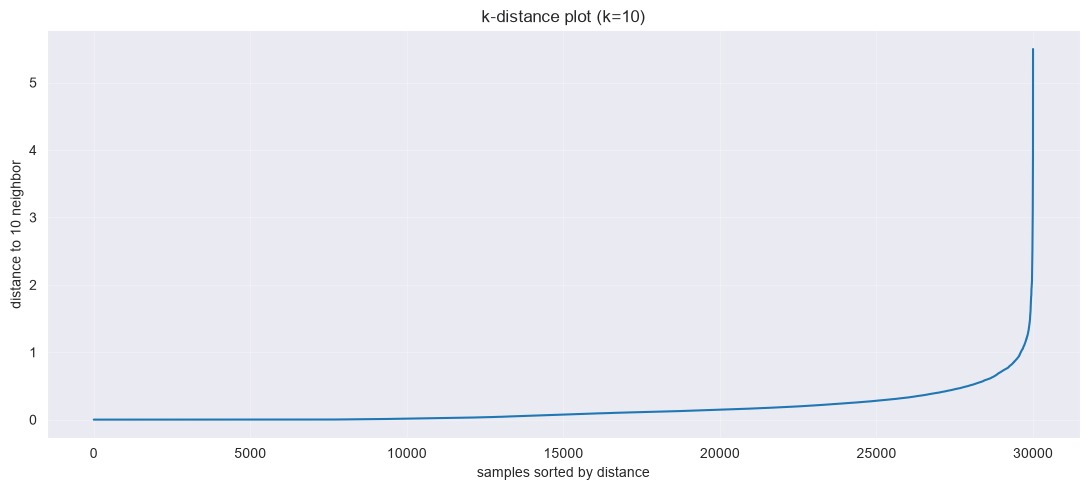

Квантили расстояния до k-го соседа:


,distance
0.50,0.075154
0.75,0.196460
0.90,0.401985
0.95,0.589986
0.99,1.085643


In [44]:
knn = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES, metric='euclidean', n_jobs=-1)
knn.fit(X_sample)
distances, _ = knn.kneighbors(X_sample)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(11, 5))
plt.plot(np.arange(1, len(k_distances) + 1), k_distances)
plt.title(f"k-distance plot (k={DBSCAN_MIN_SAMPLES})")
plt.xlabel("samples sorted by distance")
plt.ylabel(f"distance to {DBSCAN_MIN_SAMPLES} neighbor")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Квантили расстояния до k-го соседа:")
display(pd.Series(k_distances).quantile([0.50, 0.75, 0.90, 0.95, 0.99]).to_frame('distance'))

In [45]:
DBSCAN_EPS = 1.5

dbscan_model = DBSCAN(
    eps=DBSCAN_EPS,
    min_samples=DBSCAN_MIN_SAMPLES,
    metric='euclidean',
    algorithm='auto',
    n_jobs=-1,
)

start_time = time.time()
dbscan_labels = dbscan_model.fit_predict(X_sample)
dbscan_fit_seconds = time.time() - start_time

dbscan_anomaly = (dbscan_labels == -1)
dbscan_cluster_labels = set(dbscan_labels) - {-1}

print(f"Total time: {dbscan_fit_seconds:.1f} сек.")
print(f"Cluster number (without noise): {len(dbscan_cluster_labels):,}")
print(f"Noise values: {int(dbscan_anomaly.sum()):,} ({dbscan_anomaly.mean():.2%})")

Total time: 4.6 сек.
Cluster number (without noise): 2
Noise values: 43 (0.14%)


In [46]:
model_results = pd.DataFrame({
    'isolation_forest_anomaly': if_anomaly,
    'lof_anomaly': lof_anomaly,
    'dbscan_anomaly': dbscan_anomaly,
    'if_anomaly_score': if_anomaly_score,
    'lof_anomaly_score': lof_anomaly_score,
    'dbscan_cluster': dbscan_labels,
})

comparison_summary = pd.DataFrame([
    {
        'Algorithm': 'Isolation Forest',
        'Anomaly count': int(if_anomaly.sum()),
        'Anomaly percent': float(if_anomaly.mean() * 100),
        'Total time': if_fit_seconds,
        'Cluster number': np.nan,
    },
    {
        'Algorithm': 'Local Outlier Factor',
        'Anomaly count': int(lof_anomaly.sum()),
        'Anomaly percent': float(lof_anomaly.mean() * 100),
        'Total time': lof_fit_seconds,
        'Cluster number': np.nan,
    },
    {
        'Algorithm': 'DBSCAN',
        'Anomaly count': int(dbscan_anomaly.sum()),
        'Anomaly percent': float(dbscan_anomaly.mean() * 100),
        'Total time': dbscan_fit_seconds,
        'Cluster number': len(dbscan_cluster_labels),
    },
])

display(comparison_summary.round(3))

,Algorithm,Anomaly count,Anomaly percent,Total time,Cluster number
0,Isolation Forest,300,1.000,0.327,NaN
1,Local Outlier Factor,282,0.940,0.186,NaN
2,DBSCAN,43,0.143,4.642,2.0


,Isolation Forest,LOF,DBSCAN
Isolation Forest,1.00,0.0,0.11
LOF,0.00,1.0,0.00
DBSCAN,0.11,0.0,1.00


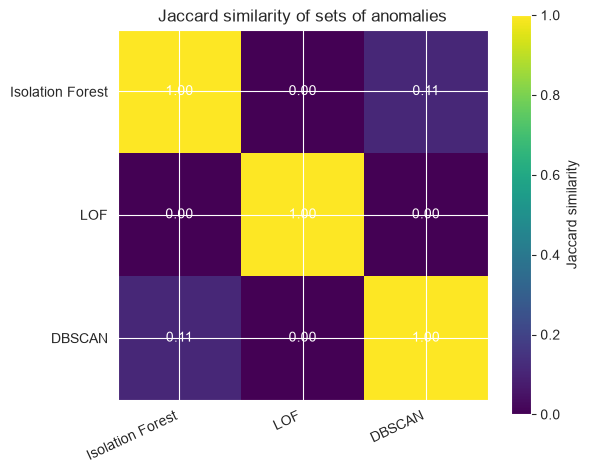

In [47]:
anomaly_masks = {
    'Isolation Forest': if_anomaly,
    'LOF': lof_anomaly,
    'DBSCAN': dbscan_anomaly,
}

agreement = pd.DataFrame(index=anomaly_masks.keys(), columns=anomaly_masks.keys(), dtype=float)
for name_a, mask_a in anomaly_masks.items():
    for name_b, mask_b in anomaly_masks.items():
        union = np.logical_or(mask_a, mask_b).sum()
        intersection = np.logical_and(mask_a, mask_b).sum()
        agreement.loc[name_a, name_b] = intersection / union if union else 1.0

display(agreement.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(agreement.to_numpy(), vmin=0, vmax=1, cmap='viridis')
ax.set_xticks(range(len(agreement.columns)), agreement.columns, rotation=25, ha='right')
ax.set_yticks(range(len(agreement.index)), agreement.index)
ax.set_title('Jaccard similarity of sets of anomalies')
for i in range(len(agreement.index)):
    for j in range(len(agreement.columns)):
        ax.text(j, i, f"{agreement.iloc[i, j]:.2f}", ha='center', va='center', color='white')
fig.colorbar(image, ax=ax, label='Jaccard similarity')
fig.tight_layout()
plt.show()

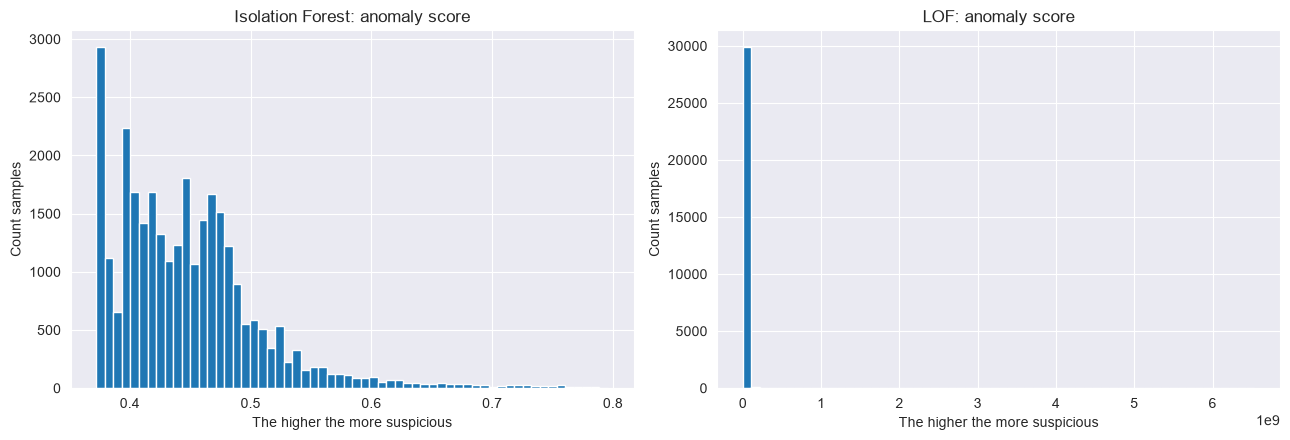

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(if_anomaly_score, bins=60)
axes[0].set_title('Isolation Forest: anomaly score')
axes[0].set_xlabel('The higher the more suspicious')
axes[0].set_ylabel('Count samples')

axes[1].hist(lof_anomaly_score, bins=60)
axes[1].set_title('LOF: anomaly score')
axes[1].set_xlabel('The higher the more suspicious')
axes[1].set_ylabel('Count samples')

fig.tight_layout()
plt.show()

In [50]:
model_results_with_metadata = pd.concat(
    [metadata_sample, features_sample, model_results],
    axis=1,
)

print("First anomalies found(Isolation Forest):")
display(
    model_results_with_metadata.loc[
        model_results_with_metadata['isolation_forest_anomaly']
    ].sort_values('if_anomaly_score', ascending=False).head(20)
)

print("First anomalies found(LOF):")
display(
    model_results_with_metadata.loc[
        model_results_with_metadata['lof_anomaly']
    ].sort_values('lof_anomaly_score', ascending=False).head(20)
)

print("The first records classified by DBSCAN as noise:")
display(
    model_results_with_metadata.loc[
        model_results_with_metadata['dbscan_anomaly']
    ].head(20)
)

First anomalies found(Isolation Forest):


,row_index,session_id,flow_start_time,flow_end_time,source_ipv4,destination_ipv4,source_port,destination_port,net_protocol,app_protocol_group,...,packet_deliver_time,duration_ms,avg_packet_size_bytes,packets_per_second,isolation_forest_anomaly,lof_anomaly,dbscan_anomaly,if_anomaly_score,lof_anomaly_score,dbscan_cluster
7280,212272,2801330524020608285,2025-08-04 11:51:40,2025-08-04 11:56:40,ip-7293,org_ip,1300,57050,TCP 6,Instant messengers,...,20,300242,1534.000000,476.252490,True,False,True,0.795847,1.884040,-1
17834,520027,1330529265511339,2025-08-04 14:17:41,2025-08-04 14:18:08,ip-152,org_ip,80,38880,TCP 6,Application servers,...,12,26598,1513.367661,3886.983984,True,False,True,0.794234,1.779319,-1
14446,421320,3901330523802008104,2025-08-04 13:46:04,2025-08-04 13:51:25,ip-7044,org_ip,443,57816,TCP 6,"Video, pictures",...,0,321284,1532.891460,532.460378,True,False,True,0.786746,1.815636,-1
18132,528983,1201330529847324099,2025-08-04 15:35:36,2025-08-04 15:40:36,ip-8923,org_ip,62538,56533,TCP 6,P2P,...,0,299941,1530.342796,605.522419,True,False,True,0.786746,1.468946,-1
18616,542784,3901330523813563970,2025-08-04 15:55:24,2025-08-04 16:00:19,ip-7044,org_ip,443,33634,TCP 6,"Video, pictures",...,0,294482,1532.762522,531.923853,True,False,True,0.786746,1.772818,-1
15311,446511,2301330524728100543,2025-08-04 14:32:13,2025-08-04 14:37:11,ip-8648,org_ip,1300,50216,TCP 6,Web browsing,...,0,298291,1522.065643,485.576166,True,False,True,0.784885,1.417900,-1
26277,767784,2301330524728100543,2025-08-04 18:17:16,2025-08-04 18:22:15,ip-8648,org_ip,1300,50216,TCP 6,Web browsing,...,0,298279,1509.483205,483.064513,True,False,True,0.783559,1.488641,-1
21449,626310,3901330523818830199,2025-08-04 16:55:18,2025-08-04 17:00:26,ip-7044,org_ip,443,51237,TCP 6,"Video, pictures",...,0,307511,1532.219074,229.546260,True,False,True,0.783029,1.600759,-1
9283,270562,3101330524936483792,2025-08-04 11:31:17,2025-08-04 11:31:20,org_ip,ip-7028,54892,443,TCP 6,E-Mail,...,1,3334,1532.654004,5471.805639,True,False,True,0.782234,1.282537,-1
14270,415682,3901330524164174647,2025-08-04 13:55:14,2025-08-04 13:56:51,ip-7044,org_ip,443,53943,TCP 6,"Video, pictures",...,1,97061,1532.515378,510.524309,True,False,True,0.781970,1.444933,-1


First anomalies found(LOF):


,row_index,session_id,flow_start_time,flow_end_time,source_ipv4,destination_ipv4,source_port,destination_port,net_protocol,app_protocol_group,...,packet_deliver_time,duration_ms,avg_packet_size_bytes,packets_per_second,isolation_forest_anomaly,lof_anomaly,dbscan_anomaly,if_anomaly_score,lof_anomaly_score,dbscan_cluster
9178,267402,1401330528996563544,2025-08-04 11:56:14,2025-08-04 11:56:14,org_ip,ip-5881,56021,443,TCP 6,VPN,...,0,1,88.000000,1000.0,False,True,False,0.582135,6.535389e+09,0
521,15143,2701330524089747959,2025-08-04 08:49:38,2025-08-04 08:49:38,org_ip,ip-2240,49821,80,TCP 6,Web browsing,...,0,1,88.000000,1000.0,False,True,False,0.582135,6.535389e+09,0
26319,768921,2901330523826542981,2025-08-04 18:00:59,2025-08-04 18:00:59,org_ip,ip-26,63782,443,TCP 6,Web browsing,...,0,1,88.000000,1000.0,False,True,False,0.582135,6.535389e+09,0
6738,196511,2001330524047226134,2025-08-04 10:36:39,2025-08-04 10:36:39,org_ip,ip-158,52850,443,TCP 6,Web browsing,...,1,1,94.000000,1000.0,False,True,False,0.546360,5.978809e+09,0
12195,356483,2901330523770774947,2025-08-04 12:04:15,2025-08-04 12:04:15,org_ip,ip-115,36427,443,TCP 6,Web browsing,...,1,1,94.000000,1000.0,False,True,False,0.546360,5.978809e+09,0
19759,575729,701330529443399699,2025-08-04 15:27:42,2025-08-04 15:27:42,org_ip,ip-1522,47008,443,TCP 6,VPN,...,1,1,88.000000,1000.0,False,True,False,0.557301,5.978809e+09,0
27455,804396,501330528575231790,2025-08-04 19:29:20,2025-08-04 19:29:20,org_ip,ip-628,54894,4244,TCP 6,Instant messengers,...,1,1,88.000000,1000.0,False,True,False,0.557301,5.978809e+09,0
9128,266051,2901330524095797323,2025-08-04 11:35:31,2025-08-04 11:35:31,org_ip,ip-115,34228,443,TCP 6,Web browsing,...,1,1,94.000000,1000.0,False,True,False,0.546360,5.978809e+09,0
29596,866614,601330525593265475,2025-08-04 23:20:50,2025-08-04 23:20:50,org_ip,ip-570,64171,443,TCP 6,Web browsing,...,1,1,88.000000,1000.0,False,True,False,0.599826,5.563236e+09,0
29390,861065,1301330529499947774,2025-08-04 23:15:56,2025-08-04 23:15:56,org_ip,ip-691,1182,443,TCP 6,Web browsing,...,1,1,88.000000,1000.0,False,True,False,0.599826,5.563236e+09,0


The first records classified by DBSCAN as noise:


,row_index,session_id,flow_start_time,flow_end_time,source_ipv4,destination_ipv4,source_port,destination_port,net_protocol,app_protocol_group,...,packet_deliver_time,duration_ms,avg_packet_size_bytes,packets_per_second,isolation_forest_anomaly,lof_anomaly,dbscan_anomaly,if_anomaly_score,lof_anomaly_score,dbscan_cluster
91,2870,1201330528939200112,2025-08-04 08:49:57,2025-08-04 08:49:58,ip-519,org_ip,443,38544,TCP 6,Web browsing,...,187,1013,1399.977778,355.380059,True,False,True,0.754537,1.925674,-1
512,14804,2401330524262606486,2025-08-04 08:30:19,2025-08-04 08:35:17,ip-274,org_ip,443,56220,TCP 6,Antivirus,...,0,297714,425.120220,11.595021,True,False,True,0.734169,1.478848,-1
536,15571,301330528948125174,2025-08-04 08:30:41,2025-08-04 08:31:44,ip-442,org_ip,1026,50637,TCP 6,VPN,...,1717,63745,97.909091,0.172563,True,False,True,0.686259,1.700180,-1
1174,33891,301330528949695873,2025-08-04 08:41:20,2025-08-04 08:42:23,ip-442,org_ip,1026,50893,TCP 6,VPN,...,1707,62613,137.777778,0.143740,True,False,True,0.685819,1.681517,-1
2054,60098,1701330523947103473,2025-08-04 09:28:37,2025-08-04 09:31:12,org_ip,ip-390,55103,443,TCP 6,Web browsing,...,62562,155256,814.833333,0.154583,True,False,True,0.724280,3.528845,-1
2060,60235,3401330523780845916,2025-08-04 09:44:13,2025-08-04 09:44:13,ip-1912,org_ip,443,41697,TCP 6,VPN,...,421,1,169.000000,4000.000000,False,False,True,0.634335,2.848811,-1
2227,65272,3801330523864594438,2025-08-04 09:52:45,2025-08-04 09:55:16,ip-3140,org_ip,15025,51994,TCP 6,VPN,...,45230,150577,132.846154,0.086335,True,False,True,0.706901,2.708151,-1
4610,134945,2301330524293661257,2025-08-04 10:06:13,2025-08-04 10:06:13,ip-501,org_ip,443,38072,TCP 6,Web browsing,...,412,1,194.500000,4000.000000,False,False,True,0.640153,2.833814,-1
5860,171075,2201330524338195569,2025-08-04 10:01:22,2025-08-04 10:03:08,ip-591,org_ip,443,35789,TCP 6,VPN,...,1515,105422,1078.429348,1.745366,True,False,True,0.753363,3.317125,-1
5999,174553,101330529181095446,2025-08-04 10:13:18,2025-08-04 10:13:18,ip-1086,org_ip,443,60695,TCP 6,Web browsing,...,45039,1,88.000000,1000.000000,False,False,True,0.666144,5.985095,-1


In [51]:
for algorithm_column, algorithm_name in [
    ('isolation_forest_anomaly', 'Isolation Forest'),
    ('lof_anomaly', 'LOF'),
    ('dbscan_anomaly', 'DBSCAN'),
]:
    print(f"\n{algorithm_name}: category distribution")
    if 'app_protocol_group' in model_results_with_metadata.columns:
        display(
            model_results_with_metadata.loc[
                model_results_with_metadata[algorithm_column], 'app_protocol_group'
            ].value_counts(dropna=False).head(15).to_frame('count')
        )
    if 'net_protocol' in model_results_with_metadata.columns:
        display(
            model_results_with_metadata.loc[
                model_results_with_metadata[algorithm_column], 'net_protocol'
            ].value_counts(dropna=False).to_frame('count')
        )


Isolation Forest: category distribution


,count
app_protocol_group,
Web browsing,93
"Video, pictures",65
Network services,41
VPN,29
Maps,19
E-Mail,18
Application servers,9
Instant messengers,7
Antivirus,5


,count
net_protocol,
TCP 6,298
UDP 17,2



LOF: category distribution


,count
app_protocol_group,
P2P,189
Network services,40
Unknown,28
Web browsing,15
Application servers,4
VPN,4
E-Mail,1
Instant messengers,1


,count
net_protocol,
UDP 17,214
ICMP 1,39
TCP 6,29



DBSCAN: category distribution


,count
app_protocol_group,
Web browsing,12
VPN,10
E-Mail,7
"Video, pictures",5
Application servers,4
P2P,2
Antivirus,1
Instant messengers,1
Social networks,1


,count
net_protocol,
TCP 6,43


In [52]:
comparison_features = [
    col for col in [
        'octet_delta_count', 'packet_delta_count', 'duration_ms',
        'avg_packet_size_bytes', 'packets_per_second',
        'frgmt_delta_packs', 'repeat_delta_pack', 'packet_deliver_time'
    ]
    if col in model_results_with_metadata.columns
]

for algorithm_column, algorithm_name in [
    ('isolation_forest_anomaly', 'Isolation Forest'),
    ('lof_anomaly', 'LOF'),
    ('dbscan_anomaly', 'DBSCAN'),
]:
    print(f"\n{algorithm_name}: median")
    tmp = model_results_with_metadata.copy()
    tmp['group'] = np.where(tmp[algorithm_column], 'anomaly', 'normal')
    display(tmp.groupby('group')[comparison_features].median().T)


Isolation Forest: median


group,anomaly,normal
octet_delta_count,1.109748e+06,369.000000
packet_delta_count,1.085500e+03,3.000000
duration_ms,2.289800e+04,3751.500000
avg_packet_size_bytes,1.388933e+03,170.000000
packets_per_second,6.944415e+01,2.296739
frgmt_delta_packs,0.000000e+00,0.000000
repeat_delta_pack,3.900000e+01,0.000000
packet_deliver_time,1.000000e+00,0.000000



LOF: median


group,anomaly,normal
octet_delta_count,171.0,405.000000
packet_delta_count,1.0,3.000000
duration_ms,1.0,4215.500000
avg_packet_size_bytes,168.0,172.633929
packets_per_second,1000.0,2.294913
frgmt_delta_packs,0.0,0.000000
repeat_delta_pack,0.0,0.000000
packet_deliver_time,0.0,0.000000



DBSCAN: median


group,anomaly,normal
octet_delta_count,1.190896e+06,376.000000
packet_delta_count,1.141000e+03,3.000000
duration_ms,4.449800e+04,3911.000000
avg_packet_size_bytes,1.457106e+03,171.444444
packets_per_second,4.830645e+02,2.392344
frgmt_delta_packs,0.000000e+00,0.000000
repeat_delta_pack,7.700000e+01,0.000000
packet_deliver_time,2.100000e+01,0.000000


## Profiling out ip

In [59]:
ORG = "org_ip"

required_columns = [
    "source_ipv4",
    "destination_ipv4",
    "source_port",
    "destination_port",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

source_ip = df["source_ipv4"].astype("string").str.strip()
destination_ip = df["destination_ipv4"].astype("string").str.strip()

source_is_org = source_ip.eq(ORG).fillna(False)
destination_is_org = destination_ip.eq(ORG).fillna(False)

outgoing_mask = source_is_org & ~destination_is_org
incoming_mask = destination_is_org & ~source_is_org
both_mask = source_is_org & destination_is_org
neither_mask = ~(source_is_org | destination_is_org)

direction_summary = pd.DataFrame({
    "Flow count": [
        int(outgoing_mask.sum()),
        int(incoming_mask.sum()),
        int(both_mask.sum()),
        int(neither_mask.sum()),
    ]
}, index=[
    "Outgoing traffic",
    "Incoming traffic",
    "Organization on both sides",
    "Organization not identified",
])

direction_summary["Percentage (%)"] = (
    direction_summary["Flow count"] / len(df) * 100
).round(3)

display(direction_summary)

print("\nValidation:")
print(f"Total number of records: {len(df):,}")
print(
    "Sum of classified records:",
    direction_summary["Flow count"].sum()
)

assert direction_summary["Flow count"].sum() == len(df), (
    "Traffic direction classification is incomplete."
)


,Flow count,Percentage (%)
Outgoing traffic,439035,50.027
Incoming traffic,438549,49.972
Organization on both sides,6,0.001
Organization not identified,0,0.000



Validation:
Total number of records: 877,590
Sum of classified records: 877590


In [58]:
as_columns = [
    col for col in [
        "source_astitle",
        "destination_astitle",
        "source_asnum",
        "destination_asnum",
    ]
    if col in df.columns
]

if not as_columns:
    raise KeyError("No autonomous system columns found in the dataset.")

as_rows = []

for direction, mask in [
    ("Outgoing traffic", outgoing_mask),
    ("Incoming traffic", incoming_mask),
]:
    subset = df.loc[mask]

    for column in as_columns:
        values = subset[column]

        as_rows.append({
            "Traffic direction": direction,
            "Feature": column,
            "Unique values": values.nunique(dropna=True),
            "Missing values": int(values.isna().sum()),
            "Most frequent values": (
                values.value_counts(dropna=False)
                .head(5)
                .to_dict()
            ),
        })

as_check = pd.DataFrame(as_rows)

display(as_check)

,Traffic direction,Feature,Unique values,Missing values,Most frequent values
0,Outgoing traffic,source_astitle,1,0,"{'BN-AS Business Network Ltd, BY': 439035}"
1,Outgoing traffic,destination_astitle,3868,3,"{'YANDEX YANDEX LLC, RU': 60483, 'GOOGLE, US':..."
2,Outgoing traffic,source_asnum,1,0,{12406: 439035}
3,Outgoing traffic,destination_asnum,3928,0,"{13238: 60483, 15169: 46122, 48282: 39491, 807..."
4,Incoming traffic,source_astitle,1,0,"{'BN-AS Business Network Ltd, BY': 438549}"
5,Incoming traffic,destination_astitle,3072,2,"{'YANDEX YANDEX LLC, RU': 61258, 'GOOGLE, US':..."
6,Incoming traffic,source_asnum,1,0,{12406: 438549}
7,Incoming traffic,destination_asnum,3130,0,"{13238: 61258, 15169: 48084, 8075: 39794, 4828..."


In [60]:
external_mask = outgoing_mask | incoming_mask

traffic_df = df.loc[external_mask].copy()

traffic_df["is_outgoing"] = source_is_org.loc[traffic_df.index].astype(bool)

traffic_df["traffic_direction"] = np.where(
    traffic_df["is_outgoing"],
    "outgoing",
    "incoming"
)

traffic_df["remote_ip"] = np.where(
    traffic_df["is_outgoing"],
    traffic_df["destination_ipv4"],
    traffic_df["source_ipv4"]
)

traffic_df["remote_port"] = np.where(
    traffic_df["is_outgoing"],
    traffic_df["destination_port"],
    traffic_df["source_port"]
)

traffic_df["local_port"] = np.where(
    traffic_df["is_outgoing"],
    traffic_df["source_port"],
    traffic_df["destination_port"]
)

traffic_df["remote_as_title"] = traffic_df["destination_astitle"]
traffic_df["remote_as_num"] = traffic_df["destination_asnum"]

print("=== Normalized traffic dataset ===")
print(f"Original number of flows: {len(df):,}")
print(f"External interaction flows: {len(traffic_df):,}")
print(f"Excluded internal flows: {int(both_mask.sum()):,}")

print("\n=== External IP statistics ===")
print(f"Unique external IP addresses: {traffic_df['remote_ip'].nunique():,}")
print(f"Missing external IP addresses: {traffic_df['remote_ip'].isna().sum():,}")

print("\n=== Traffic direction ===")
display(
    traffic_df["traffic_direction"]
    .value_counts()
    .to_frame("flow_count")
)

print("\n=== External AS information ===")
print(
    "Unique AS titles:",
    traffic_df["remote_as_title"].nunique(dropna=True)
)
print(
    "Missing AS titles:",
    traffic_df["remote_as_title"].isna().sum()
)

assert len(traffic_df) == int(external_mask.sum())
assert traffic_df["remote_ip"].notna().all()
assert not traffic_df["remote_ip"].eq(ORG).any()

print("\nTraffic normalization completed successfully.")

display(
    traffic_df[
        [
            "traffic_direction",
            "source_ipv4",
            "destination_ipv4",
            "remote_ip",
            "local_port",
            "remote_port",
            "remote_as_title",
            "remote_as_num",
        ]
    ].head(10)
)

=== Normalized traffic dataset ===
Original number of flows: 877,590
External interaction flows: 877,584
Excluded internal flows: 6

=== External IP statistics ===
Unique external IP addresses: 34,667
Missing external IP addresses: 0

=== Traffic direction ===


,flow_count
traffic_direction,
outgoing,439035
incoming,438549



=== External AS information ===
Unique AS titles: 4227
Missing AS titles: 5

Traffic normalization completed successfully.


,traffic_direction,source_ipv4,destination_ipv4,remote_ip,local_port,remote_port,remote_as_title,remote_as_num
0,outgoing,org_ip,ip-12,ip-12,50544,9003,"EVANZOAS EVANZO e-commerce GmbH, DE",42730
1,outgoing,org_ip,ip-1,ip-1,52244,443,"YANDEX YANDEX LLC, RU",13238
2,incoming,ip-1,org_ip,ip-1,52244,443,"YANDEX YANDEX LLC, RU",13238
3,outgoing,org_ip,ip-2,ip-2,58140,443,"SPBMTS-AS MTS PJSC, RU",29209
4,incoming,ip-2,org_ip,ip-2,58140,443,"SPBMTS-AS MTS PJSC, RU",29209
5,outgoing,org_ip,ip-1078,ip-1078,41775,443,"AMAZON-02, US",16509
6,outgoing,org_ip,ip-3,ip-3,49143,443,"DE-FIRSTCOLO firstcolo GmbH, DE",44066
7,incoming,ip-3,org_ip,ip-3,49143,443,"DE-FIRSTCOLO firstcolo GmbH, DE",44066
8,outgoing,org_ip,ip-384,ip-384,36401,443,"YANDEX YANDEX LLC, RU",13238
9,incoming,ip-4,org_ip,ip-4,50428,443,"CLOUDRU-AS ""Cloud Technologies"" LLC trading as...",208677


In [61]:
port_check = traffic_df[
    traffic_df["traffic_direction"].isin(["outgoing", "incoming"])
][
    [
        "traffic_direction",
        "source_ipv4",
        "destination_ipv4",
        "source_port",
        "destination_port",
        "local_port",
        "remote_port",
    ]
].head(10)

display(port_check)

outgoing_check = traffic_df["traffic_direction"].eq("outgoing")

outgoing_valid = (
    traffic_df.loc[outgoing_check, "local_port"].eq(
        traffic_df.loc[outgoing_check, "source_port"]
    )
    &
    traffic_df.loc[outgoing_check, "remote_port"].eq(
        traffic_df.loc[outgoing_check, "destination_port"]
    )
)

incoming_check = traffic_df["traffic_direction"].eq("incoming")

incoming_valid = (
    traffic_df.loc[incoming_check, "local_port"].eq(
        traffic_df.loc[incoming_check, "destination_port"]
    )
    &
    traffic_df.loc[incoming_check, "remote_port"].eq(
        traffic_df.loc[incoming_check, "source_port"]
    )
)

print("\n=== Port normalization validation ===")
print("Outgoing records:", outgoing_valid.mean() * 100, "% valid")
print("Incoming records:", incoming_valid.mean() * 100, "% valid")

print("\nUnique external IP addresses:",
      traffic_df["remote_ip"].nunique())

print("Missing external IP addresses:",
      traffic_df["remote_ip"].isna().sum())

,traffic_direction,source_ipv4,destination_ipv4,source_port,destination_port,local_port,remote_port
0,outgoing,org_ip,ip-12,50544,9003,50544,9003
1,outgoing,org_ip,ip-1,52244,443,52244,443
2,incoming,ip-1,org_ip,443,52244,52244,443
3,outgoing,org_ip,ip-2,58140,443,58140,443
4,incoming,ip-2,org_ip,443,58140,58140,443
5,outgoing,org_ip,ip-1078,41775,443,41775,443
6,outgoing,org_ip,ip-3,49143,443,49143,443
7,incoming,ip-3,org_ip,443,49143,49143,443
8,outgoing,org_ip,ip-384,36401,443,36401,443
9,incoming,ip-4,org_ip,443,50428,50428,443



=== Port normalization validation ===
Outgoing records: 100.0 % valid
Incoming records: 100.0 % valid

Unique external IP addresses: 34667
Missing external IP addresses: 0


In [67]:
# Prepare data for external IP profiling

profile_data = traffic_df.copy()

# Convert traffic counters to numeric values
numeric_columns = [
    "octet_delta_count",
    "packet_delta_count",
    "repeat_delta_pack",
    "flow_start_millisecond",
    "flow_end_millisecond",
]

for column in numeric_columns:
    profile_data[f"_{column}"] = pd.to_numeric(
        profile_data[column],
        errors="coerce"
    )

# Calculate flow duration
profile_data["_duration_ms"] = (
    profile_data["_flow_end_millisecond"]
    - profile_data["_flow_start_millisecond"]
)

# Parse timestamps
profile_data["_start_time"] = pd.to_datetime(
    profile_data["flow_start_time"],
    errors="coerce"
)

profile_data["_hour"] = profile_data["_start_time"].dt.hour

# Normalize application protocol information
profile_data["_app_protocol"] = (
    profile_data["app_protocol"]
    .fillna("")
    .astype("string")
    .str.lower()
    .str.strip()
)

profile_data["_app_group"] = (
    profile_data["app_protocol_group"]
    .fillna("")
    .astype("string")
    .str.lower()
    .str.strip()
)

profile_data["_net_protocol"] = (
    profile_data["net_protocol"]
    .fillna("")
    .astype("string")
    .str.upper()
    .str.strip()
)

# Identify traffic categories
profile_data["_is_anon"] = (
    profile_data["_app_group"].eq("vpn")
    | profile_data["_app_protocol"].str.contains(
        r"tor|shadowsocks|vpn|psiphon|proxy|lantern|warp",
        regex=True,
        na=False
    )
)

profile_data["_is_tor"] = (
    profile_data["_app_protocol"].str.startswith("tor", na=False)
)

profile_data["_is_p2p"] = (
    profile_data["_app_group"].eq("p2p")
)

profile_data["_is_bot"] = (
    profile_data["_app_group"].eq("botnet")
)

# Keep custom DPI protocols as a separate category
profile_data["_is_custom_protocol"] = (
    profile_data["_app_group"].eq("custom protocols")
)

profile_data["_is_icmp"] = (
    profile_data["_net_protocol"].str.startswith("ICMP", na=False)
)

# Convert ports to numeric values
profile_data["_remote_port_num"] = pd.to_numeric(
    profile_data["remote_port"],
    errors="coerce"
)

profile_data["_local_port_num"] = pd.to_numeric(
    profile_data["local_port"],
    errors="coerce"
)

print("=== Profile data preparation ===")
print(f"Total flows: {len(profile_data):,}")
print(f"Unique external IPs: {profile_data['remote_ip'].nunique():,}")

print("\n=== Data quality ===")

quality_summary = pd.DataFrame({
    "Missing values": profile_data[
        [
            "_octet_delta_count",
            "_packet_delta_count",
            "_start_time",
            "_hour",
            "_remote_port_num",
            "_local_port_num",
            "_remote_as_title" if "_remote_as_title" in profile_data.columns else "remote_as_title",
        ]
    ].isna().sum()
})

display(quality_summary)

print("\n=== Application protocol groups ===")
display(
    profile_data["app_protocol_group"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("flow_count")
)

print("\nPreparation completed.")

=== Profile data preparation ===
Total flows: 877,584
Unique external IPs: 34,667

=== Data quality ===


,Missing values
_octet_delta_count,0
_packet_delta_count,0
_start_time,0
_hour,0
_remote_port_num,0
_local_port_num,0
remote_as_title,5



=== Application protocol groups ===


,flow_count
app_protocol_group,
Web browsing,323759
Application servers,135581
P2P,129299
Network services,90368
VPN,73366
Unknown,34689
Instant messengers,21597
"Video, pictures",19949
Maps,17979



Preparation completed.


In [72]:
# Aggregate network flows into external IP profiles

def get_mode(series):
    values = series.dropna()
    modes = values.mode()

    return modes.iloc[0] if not modes.empty else pd.NA


def get_share(series, condition):
    values = series.dropna()

    if values.empty:
        return np.nan

    return condition(values).mean()


# Group flows by external IP address
grouped = profile_data.groupby("remote_ip", sort=False)

ip_profiles = pd.DataFrame(index=grouped.size().index)
ip_profiles.index.name = "remote_ip"

# Basic traffic information
ip_profiles["flows"] = grouped.size()

ip_profiles["sessions"] = (
    grouped["session_id"].nunique()
)

# External autonomous system information
ip_profiles["as_name"] = (
    grouped["remote_as_title"].agg(get_mode)
)

ip_profiles["as_num"] = (
    grouped["remote_as_num"].agg(get_mode)
)

ip_profiles["as_name_unique"] = (
    grouped["remote_as_title"].nunique()
)

ip_profiles["as_num_unique"] = (
    grouped["remote_as_num"].nunique()
)

ip_profiles["main_app"] = (
    grouped["app_protocol"].agg(get_mode)
)

ip_profiles["main_app_group"] = (
    grouped["app_protocol_group"].agg(get_mode)
)

ip_profiles["main_remote_port"] = (
    grouped["_remote_port_num"].agg(get_mode)
)

# Split outgoing and incoming traffic
outgoing_data = profile_data[
    profile_data["is_outgoing"]
]

incoming_data = profile_data[
    ~profile_data["is_outgoing"]
]

# Flow counts by direction
ip_profiles["flows_out"] = (
    outgoing_data.groupby("remote_ip")
    .size()
    .reindex(ip_profiles.index, fill_value=0)
)

ip_profiles["flows_in"] = (
    incoming_data.groupby("remote_ip")
    .size()
    .reindex(ip_profiles.index, fill_value=0)
)

# Traffic volume by direction
ip_profiles["bytes_out"] = (
    outgoing_data.groupby("remote_ip")["_octet_delta_count"]
    .sum(min_count=1)
    .reindex(ip_profiles.index, fill_value=0)
)

ip_profiles["bytes_in"] = (
    incoming_data.groupby("remote_ip")["_octet_delta_count"]
    .sum(min_count=1)
    .reindex(ip_profiles.index, fill_value=0)
)

ip_profiles["bytes_total"] = (
    ip_profiles[["bytes_out", "bytes_in"]]
    .sum(axis=1, min_count=1)
)

# Packet and retransmission statistics
ip_profiles["packets"] = (
    grouped["_packet_delta_count"].sum(min_count=1)
)

ip_profiles["retrans"] = (
    grouped["_repeat_delta_pack"].sum(min_count=1)
)

ip_profiles["share_1pkt"] = (
    grouped["_packet_delta_count"]
    .agg(lambda s: get_share(s, lambda x: x.le(1)))
)

# Port diversity
ip_profiles["n_rports"] = (
    grouped["_remote_port_num"].nunique()
)

ip_profiles["n_lports"] = (
    grouped["_local_port_num"].nunique()
)

# Temporal activity
ip_profiles["n_hours"] = (
    grouped["_hour"].nunique()
)

ip_profiles["share_night"] = (
    grouped["_hour"]
    .agg(
        lambda s: get_share(
            s,
            lambda x: x.lt(8) | x.ge(20)
        )
    )
)

ip_profiles["first_seen"] = (
    grouped["_start_time"].min()
)

ip_profiles["last_seen"] = (
    grouped["_start_time"].max()
)

# Traffic categories
ip_profiles["share_anon"] = grouped["_is_anon"].mean()
ip_profiles["share_tor"] = grouped["_is_tor"].mean()
ip_profiles["share_p2p"] = grouped["_is_p2p"].mean()

ip_profiles["bot_flows"] = (
    grouped["_is_bot"].sum()
)

ip_profiles["custom_protocol_flows"] = (
    grouped["_is_custom_protocol"].sum()
)

ip_profiles["icmp_flows"] = (
    grouped["_is_icmp"].sum()
)

# Flow duration
ip_profiles["median_duration_ms"] = (
    grouped["_duration_ms"].median()
)

ip_profiles["p95_duration_ms"] = (
    grouped["_duration_ms"].quantile(0.95)
)

# Derived traffic characteristics
ip_profiles["upload_ratio"] = (
    ip_profiles["bytes_out"]
    / ip_profiles["bytes_total"].replace(0, np.nan)
)

ip_profiles["bytes_per_session"] = (
    ip_profiles["bytes_total"]
    / ip_profiles["sessions"].replace(0, np.nan)
)

ip_profiles["pkt_size"] = (
    ip_profiles["bytes_total"]
    / ip_profiles["packets"].replace(0, np.nan)
)

ip_profiles["out_in_flow_ratio"] = (
    (ip_profiles["flows_out"] + 1)
    / (ip_profiles["flows_in"] + 1)
)

ip_profiles["retrans_rate"] = (
    ip_profiles["retrans"]
    / ip_profiles["packets"].replace(0, np.nan)
)

# Maximum hourly traffic volume
hourly_out = (
    outgoing_data.groupby(["remote_ip", "_hour"])["_octet_delta_count"]
    .sum(min_count=1)
    .groupby(level=0)
    .max()
)

hourly_in = (
    incoming_data.groupby(["remote_ip", "_hour"])["_octet_delta_count"]
    .sum(min_count=1)
    .groupby(level=0)
    .max()
)

ip_profiles["max_bytes_out_hour"] = (
    hourly_out.reindex(ip_profiles.index, fill_value=0)
)

ip_profiles["max_bytes_in_hour"] = (
    hourly_in.reindex(ip_profiles.index, fill_value=0)
)

print("IP profile aggregation completed.")
print(f"Number of profiles: {len(ip_profiles):,}")
print(f"Number of features: {ip_profiles.shape[1]}")

display(ip_profiles.head(10))

IP profile aggregation completed.
Number of profiles: 34,667
Number of features: 38


,flows,sessions,as_name,as_num,as_name_unique,as_num_unique,main_app,main_app_group,main_remote_port,flows_out,...,icmp_flows,median_duration_ms,p95_duration_ms,upload_ratio,bytes_per_session,pkt_size,out_in_flow_ratio,retrans_rate,max_bytes_out_hour,max_bytes_in_hour
remote_ip,,,,,,,,,,,,,,,,,,,,,
ip-12,69,49,"EVANZOAS EVANZO e-commerce GmbH, DE",42730,1,1,tor 54327,VPN,9003,35,...,0,63338.0,300301.60,0.652095,6701.857143,259.392575,1.028571,0.887046,56108,26716
ip-1,5590,888,"YANDEX YANDEX LLC, RU",13238,1,1,yandex_map 54323,Maps,443,2795,...,0,44845.0,58214.20,0.059093,755758.896396,844.078180,1.000000,0.037929,7313820,113607435
ip-2,20,13,"SPBMTS-AS MTS PJSC, RU",29209,1,1,https 443,Web browsing,443,10,...,0,1497.0,5121.35,0.373062,9035.615385,406.446367,1.000000,0.027682,15180,22211
ip-1078,58,3,"AMAZON-02, US",16509,1,1,viber_cl 54400,Instant messengers,443,29,...,0,52582.0,86965.90,0.756767,85636.666667,430.335008,1.000000,0.065327,136072,39881
ip-3,2119,1277,"DE-FIRSTCOLO firstcolo GmbH, DE",44066,1,1,https 443,Web browsing,443,1059,...,0,10784.0,60122.00,0.503172,5855.571652,362.478307,0.999057,0.034224,499316,454251
ip-384,687,293,"YANDEX YANDEX LLC, RU",13238,1,1,https 443,Web browsing,443,343,...,0,8787.0,52719.20,0.341577,9101.262799,448.783238,0.997101,0.030125,139035,309391
ip-4,916,634,"CLOUDRU-AS ""Cloud Technologies"" LLC trading as...",208677,1,1,https 443,Web browsing,443,470,...,0,114146.5,289813.50,0.657958,6095.853312,185.209709,1.053691,0.015431,369342,188490
ip-5,196,143,"MICROSOFT-CORP-MSN-AS-BLOCK, US",8075,1,1,windows_update 54419,Application servers,443,67,...,0,1280.5,14857.25,0.366285,8284.951049,459.560900,0.523077,0.007758,195312,308236
ip-6,8562,1579,"YANDEX YANDEX LLC, RU",13238,1,1,https 443,Web browsing,443,4256,...,0,15094.0,58326.55,0.398430,91389.996200,682.789379,0.988391,0.022182,9721406,13276539


In [75]:
# Correct anonymizer protocol identification

ANON_PROTOCOL_PATTERN = (
    r"(^tor\b|shadowsocks|vpn|psiphon|proxy|lantern|warp)"
)

profile_data["_is_anon"] = (
    profile_data["_app_group"].eq("vpn")
    |
    profile_data["_app_protocol"].str.contains(
        ANON_PROTOCOL_PATTERN,
        regex=True,
        na=False
    )
)

profile_data["_is_tor"] = (
    profile_data["_app_protocol"].str.startswith(
        "tor",
        na=False
    )
)

print("Anonymizer identification updated.")

# Inspect protocol classification
protocol_check = (
    profile_data.groupby(
        ["app_protocol_group", "_app_protocol"]
    )
    .agg(
        flow_count=("_is_anon", "size"),
        is_anonymizer=("_is_anon", "first"),
        is_p2p=("_is_p2p", "first"),
        is_tor=("_is_tor", "first"),
    )
    .sort_values("flow_count", ascending=False)
)

display(protocol_check.head(30))

print("\nBitTorrent classification:")

display(
    protocol_check[
        protocol_check.index.get_level_values(1).str.contains(
            "bittorrent",
            case=False,
            regex=False
        )
    ]
)

/var/folders/s8/vkdj2b7n1534cddf9ms3_bb80000gn/T/ipykernel_27743/2522074619.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  profile_data["_app_protocol"].str.contains(


Anonymizer identification updated.


flow_count  is_anonymizer  \
app_protocol_group   _app_protocol                                        
Web browsing         https 443                    318447          False   
P2P                  bittorrent 49165             129294          False   
Application servers  powerburst 485                78908          False   
                     windows_update 54419          45439          False   
Network services     google 54385                  42257          False   
VPN                  shadowsocks_vpn 49303         38604           True   
Network services     microsoft 54389               33841          False   
Unknown              tcp unknown 65030             25672          False   
Maps                 yandex_map 54323              17787          False   
Video, pictures      youtube 49227                 14704          False   
VPN                  multiproxy 54338              13360           True   
                     tor 54327                     13177           True   
Application servers  google_play 54313             10962          False   
Instant messengers   viber_cl 54400                 7693          False   
Network services     icmp 65025                     7164          False   
Unknown              udp unknown 65041              7065          False   
E-Mail               gmail 54314                    5744          False   
Web browsing         http 80                        5083          False   
Network services     hpvroom 5228                   4586          False   
Antivirus            kaspersky_antivir 54343        3592          False   
E-Mail               mail_ru 54317                  3583          False   
Instant messengers   telegram_cl 54401              3573          False   
                     google_mtalk 54340             3335          False   
Social networks      vk 54304                       3284          False   
Instant messengers   telegram 49224                 3218          False   
E-Mail               yandex_mail 54316              3115          False   
VPN                  psiphon3 49257                 2849           True   
Video, pictures      smotrim_vgtrk_tv 54285         2683          False   
Gaming               steam 49196                    2425          False   
CDN & Cloud services google_cloud 54321             2038          False   

                                              is_p2p  is_tor  
app_protocol_group   _app_protocol                            
Web browsing         https 443                 False   False  
P2P                  bittorrent 49165           True   False  
Application servers  powerburst 485            False   False  
                     windows_update 54419      False   False  
Network services     google 54385              False   False  
VPN                  shadowsocks_vpn 49303     False   False  
Network services     microsoft 54389           False   False  
Unknown              tcp unknown 65030         False   False  
Maps                 yandex_map 54323          False   False  
Video, pictures      youtube 49227             False   False  
VPN                  multiproxy 54338          False   False  
                     tor 54327                 False    True  
Application servers  google_play 54313         False   False  
Instant messengers   viber_cl 54400            False   False  
Network services     icmp 65025                False   False  
Unknown              udp unknown 65041         False   False  
E-Mail               gmail 54314               False   False  
Web browsing         http 80                   False   False  
Network services     hpvroom 5228              False   False  
Antivirus            kaspersky_antivir 54343   False   False  
E-Mail               mail_ru 54317             False   False  
Instant messengers   telegram_cl 54401         False   False  
                     google_mtalk 54340        False   False  
Social networks      vk 54304                  False   False  
Instant


BitTorrent classification:


,,flow_count,is_anonymizer,is_p2p,is_tor
app_protocol_group,_app_protocol,,,,
P2P,bittorrent 49165,129294,False,True,False


In [76]:
# Validate aggregated IP profiles

print("=== IP profile validation ===")

print(f"Number of profiles: {len(ip_profiles):,}")
print(f"Total aggregated flows: {ip_profiles['flows'].sum():,}")

print(
    "Unique external IP addresses:",
    ip_profiles.index.nunique()
)

print("\n=== Missing values ===")

missing_profiles = (
    ip_profiles.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

missing_profiles["missing_percent"] = (
    missing_profiles["missing_count"]
    / len(ip_profiles) * 100
).round(2)

display(
    missing_profiles[
        missing_profiles["missing_count"] > 0
    ]
)

print("\n=== Numerical feature statistics ===")

display(
    ip_profiles.select_dtypes(include="number")
    .describe()
    .T
)

=== IP profile validation ===
Number of profiles: 34,667
Total aggregated flows: 877,584
Unique external IP addresses: 34667

=== Missing values ===


,missing_count,missing_percent
as_name,4,0.01



=== Numerical feature statistics ===


,count,mean,std,min,25%,50%,75%,max
flows,34667.0,25.31468,486.553562,1.0,1.0,2.0,4.0,78908.0
sessions,34667.0,13.463813,337.613461,1.0,1.0,1.0,3.0,58729.0
as_num,34667.0,48639.847117,79454.260659,49.0,8151.0,16509.0,45916.0,401696.0
as_name_unique,34667.0,1.000692,0.030375,0.0,1.0,1.0,1.0,2.0
as_num_unique,34667.0,1.000808,0.028409,1.0,1.0,1.0,1.0,2.0
main_remote_port,34667.0,22827.109499,21142.628306,0.0,1607.5,16150.0,42512.5,65535.0
flows_out,34667.0,12.664349,249.04883,0.0,1.0,1.0,2.0,39455.0
flows_in,34667.0,12.65033,243.496706,0.0,0.0,1.0,2.0,39453.0
bytes_out,34667.0,271623.530101,18524619.75053,0.0,173.0,173.0,444.0,3234089436.0
bytes_in,34667.0,2536324.359535,143968820.652657,0.0,0.0,201.0,704.0,20160587660.0


In [77]:
# Correct anonymizer protocol identification

ANON_PROTOCOL_PATTERN = (
    r"(^tor\b|shadowsocks|vpn|psiphon|proxy|lantern|warp)"
)

profile_data["_is_anon"] = (
    profile_data["_app_group"].eq("vpn")
    |
    profile_data["_app_protocol"].str.contains(
        ANON_PROTOCOL_PATTERN,
        regex=True,
        na=False
    )
)

profile_data["_is_tor"] = (
    profile_data["_app_protocol"].str.startswith(
        "tor",
        na=False
    )
)

print("Anonymizer identification updated.")

# Inspect protocol classification
protocol_check = (
    profile_data.groupby(
        ["app_protocol_group", "_app_protocol"]
    )
    .agg(
        flow_count=("_is_anon", "size"),
        is_anonymizer=("_is_anon", "first"),
        is_p2p=("_is_p2p", "first"),
        is_tor=("_is_tor", "first"),
    )
    .sort_values("flow_count", ascending=False)
)

display(protocol_check.head(30))

print("\nBitTorrent classification:")

display(
    protocol_check[
        protocol_check.index.get_level_values(1).str.contains(
            "bittorrent",
            case=False,
            regex=False
        )
    ]
)

/var/folders/s8/vkdj2b7n1534cddf9ms3_bb80000gn/T/ipykernel_27743/2522074619.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  profile_data["_app_protocol"].str.contains(


Anonymizer identification updated.


flow_count  is_anonymizer  \
app_protocol_group   _app_protocol                                        
Web browsing         https 443                    318447          False   
P2P                  bittorrent 49165             129294          False   
Application servers  powerburst 485                78908          False   
                     windows_update 54419          45439          False   
Network services     google 54385                  42257          False   
VPN                  shadowsocks_vpn 49303         38604           True   
Network services     microsoft 54389               33841          False   
Unknown              tcp unknown 65030             25672          False   
Maps                 yandex_map 54323              17787          False   
Video, pictures      youtube 49227                 14704          False   
VPN                  multiproxy 54338              13360           True   
                     tor 54327                     13177           True   
Application servers  google_play 54313             10962          False   
Instant messengers   viber_cl 54400                 7693          False   
Network services     icmp 65025                     7164          False   
Unknown              udp unknown 65041              7065          False   
E-Mail               gmail 54314                    5744          False   
Web browsing         http 80                        5083          False   
Network services     hpvroom 5228                   4586          False   
Antivirus            kaspersky_antivir 54343        3592          False   
E-Mail               mail_ru 54317                  3583          False   
Instant messengers   telegram_cl 54401              3573          False   
                     google_mtalk 54340             3335          False   
Social networks      vk 54304                       3284          False   
Instant messengers   telegram 49224                 3218          False   
E-Mail               yandex_mail 54316              3115          False   
VPN                  psiphon3 49257                 2849           True   
Video, pictures      smotrim_vgtrk_tv 54285         2683          False   
Gaming               steam 49196                    2425          False   
CDN & Cloud services google_cloud 54321             2038          False   

                                              is_p2p  is_tor  
app_protocol_group   _app_protocol                            
Web browsing         https 443                 False   False  
P2P                  bittorrent 49165           True   False  
Application servers  powerburst 485            False   False  
                     windows_update 54419      False   False  
Network services     google 54385              False   False  
VPN                  shadowsocks_vpn 49303     False   False  
Network services     microsoft 54389           False   False  
Unknown              tcp unknown 65030         False   False  
Maps                 yandex_map 54323          False   False  
Video, pictures      youtube 49227             False   False  
VPN                  multiproxy 54338          False   False  
                     tor 54327                 False    True  
Application servers  google_play 54313         False   False  
Instant messengers   viber_cl 54400            False   False  
Network services     icmp 65025                False   False  
Unknown              udp unknown 65041         False   False  
E-Mail               gmail 54314               False   False  
Web browsing         http 80                   False   False  
Network services     hpvroom 5228              False   False  
Antivirus            kaspersky_antivir 54343   False   False  
E-Mail               mail_ru 54317             False   False  
Instant messengers   telegram_cl 54401         False   False  
                     google_mtalk 54340        False   False  
Social networks      vk 54304                  False   False  
Instant


BitTorrent classification:


,,flow_count,is_anonymizer,is_p2p,is_tor
app_protocol_group,_app_protocol,,,,
P2P,bittorrent 49165,129294,False,True,False


In [78]:
# Analyze external IP profile activity

flow_thresholds = [1, 2, 5, 10, 20, 100, 1000]

activity_rows = []

for threshold in flow_thresholds:
    count = int((ip_profiles["flows"] >= threshold).sum())

    activity_rows.append({
        "Minimum number of flows": threshold,
        "IP count": count,
        "Percentage (%)": round(
            count / len(ip_profiles) * 100,
            2
        ),
    })

activity_summary = pd.DataFrame(activity_rows)

display(activity_summary)

,Minimum number of flows,IP count,Percentage (%)
0,1,34667,100.00
1,2,20889,60.26
2,5,7186,20.73
3,10,4848,13.98
4,20,3103,8.95
5,100,1022,2.95
6,1000,129,0.37


In [79]:
# External IP profile diagnostics

# 1. Flow count distribution
print("=== Flow count distribution ===")

display(
    ip_profiles["flows"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("value")
)

# 2. Most active external IP addresses
print("\n=== Top 20 IP addresses by flow count ===")

top_by_flows = ip_profiles.sort_values(
    "flows",
    ascending=False
).head(20)

display(
    top_by_flows[
        [
            "flows",
            "sessions",
            "bytes_total",
            "flows_out",
            "flows_in",
            "n_rports",
            "n_lports",
            "as_name",
            "main_app_group",
        ]
    ]
)

# 3. Most active IP addresses by traffic volume
print("\n=== Top 20 IP addresses by traffic volume ===")

top_by_bytes = ip_profiles.sort_values(
    "bytes_total",
    ascending=False
).head(20)

display(
    top_by_bytes[
        [
            "flows",
            "bytes_out",
            "bytes_in",
            "bytes_total",
            "packets",
            "upload_ratio",
            "as_name",
            "main_app_group",
        ]
    ]
)

# 4. Autonomous system consistency
print("\n=== Autonomous system consistency ===")

as_consistency = pd.Series({
    "Missing AS names": int(ip_profiles["as_name"].isna().sum()),
    "Missing AS numbers": int(ip_profiles["as_num"].isna().sum()),
    "IPs with multiple AS names": int(
        (ip_profiles["as_name_unique"] > 1).sum()
    ),
    "IPs with multiple AS numbers": int(
        (ip_profiles["as_num_unique"] > 1).sum()
    ),
})

display(as_consistency.to_frame("count"))

# Inspect IP addresses associated with multiple AS values
as_conflicts = ip_profiles[
    (ip_profiles["as_name_unique"] > 1)
    | (ip_profiles["as_num_unique"] > 1)
]

display(
    as_conflicts[
        [
            "flows",
            "as_name",
            "as_num",
            "as_name_unique",
            "as_num_unique",
        ]
    ].head(20)
)

# 5. Derived feature validation
print("\n=== Derived feature validation ===")

derived_columns = [
    "upload_ratio",
    "out_in_flow_ratio",
    "retrans_rate",
    "pkt_size",
    "bytes_per_session",
]

derived_summary = ip_profiles[derived_columns].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).T

display(derived_summary)

print("\nValues outside expected ranges:")

print(
    "Upload ratio above 1:",
    int((ip_profiles["upload_ratio"] > 1).sum())
)

print(
    "Negative upload ratio:",
    int((ip_profiles["upload_ratio"] < 0).sum())
)

print(
    "Retransmission rate above 1:",
    int((ip_profiles["retrans_rate"] > 1).sum())
)

# 6. Anonymizer and P2P statistics after correction
print("\n=== Updated traffic category statistics ===")

display(
    ip_profiles[
        ["share_anon", "share_tor", "share_p2p"]
    ].describe().T
)

=== Flow count distribution ===


,value
count,34667.000000
mean,25.314680
std,486.553562
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
90%,16.000000
95%,51.000000
99%,346.340000



=== Top 20 IP addresses by flow count ===


,flows,sessions,bytes_total,flows_out,flows_in,n_rports,n_lports,as_name,main_app_group
remote_ip,,,,,,,,,
ip-3076,78908,58729,21594558,39455,39453,1,16313,"VDSINA-AS Hosting technology LTD, RU",Application servers
ip-115,12211,1537,151478688,6075,6136,1,1018,"YANDEX YANDEX LLC, RU",Web browsing
ip-41,11510,1594,137122887,5741,5769,1,1031,"YANDEX YANDEX LLC, RU",Web browsing
ip-92,10418,2272,283280857,5191,5227,1,1471,"YANDEX YANDEX LLC, RU",Web browsing
ip-101,9612,6366,1335400,3246,6366,1,6366,"Mevspace MEVSPACE sp. z o.o., PL",Unknown
ip-60,9607,2246,189552327,4777,4830,1,1454,"YANDEX YANDEX LLC, RU",Web browsing
ip-971,9457,9365,4090375,9282,175,1,7898,"SELECTEL JSC Selectel, RU",Web browsing
ip-661,9437,9351,4073338,9261,176,1,7930,"SELECTEL JSC Selectel, RU",Web browsing
ip-83,8731,62,1497552,4369,4362,1,40,"MICROSOFT-CORP-MSN-AS-BLOCK, US",Web browsing



=== Top 20 IP addresses by traffic volume ===


,flows,bytes_out,bytes_in,bytes_total,packets,upload_ratio,as_name,main_app_group
remote_ip,,,,,,,,
ip-8648,186,510685213,20160587660,20671272873,18649042,0.024705,"HETZNER-AS Hetzner Online GmbH, DE",Web browsing
ip-7044,197,548242357,11502042009,12050284366,12480826,0.045496,"CDNetworks GLOBAL CLOUD NETWORK LLC, RU","Video, pictures"
ip-8923,119,356336491,10680338916,11036675407,10814017,0.032287,"ASLANUA-NETWORK LocalNet Ltd., UA",P2P
ip-5330,179,162080511,4910632719,5072713230,5004568,0.031951,"AVIEL-AS JSC ""AVIEL"", RU",P2P
ip-7028,1094,3234089436,103639596,3337729032,3214641,0.968949,"VK-AS LLC VK, RU",E-Mail
ip-13567,48,146212899,2893983879,3040196778,3184740,0.048093,"NTEC Republican Unitary Enterprise ""National T...","Video, pictures"
ip-3121,1042,70722187,2507380233,2578102420,2401949,0.027432,"INETCOM INETCOM CARRIER LLC, RU",Web browsing
ip-152,758,117488792,2350904868,2468393660,2604502,0.047597,"GOOGLE-CLOUD-PLATFORM, US",Application servers
ip-13,608,53746185,1753454176,1807200361,1715925,0.029740,"INETCOM INETCOM CARRIER LLC, RU",Web browsing


... (3 outputs left out)


=== Derived feature validation ===


,count,mean,std,min,50%,90%,95%,99%,max
upload_ratio,34667.0,0.521533,3.739427e-01,0.000000,0.430693,1.000000,1.000000,1.000000,1.000000e+00
out_in_flow_ratio,34667.0,1.513085,8.848545e+00,0.001488,1.000000,2.000000,2.000000,6.000000,1.128000e+03
retrans_rate,34667.0,0.005030,2.707559e-02,0.000000,0.000000,0.007974,0.032162,0.095238,1.031250e+00
pkt_size,34667.0,240.170116,1.532852e+02,88.000000,176.000000,376.118291,511.762631,957.282568,1.536000e+03
bytes_per_session,34667.0,774695.665421,1.115514e+08,88.000000,187.000000,7179.160000,15532.272917,378490.568333,2.067127e+10



Values outside expected ranges:
Upload ratio above 1: 0
Negative upload ratio: 0
Retransmission rate above 1: 1

=== Updated traffic category statistics ===


,count,mean,std,min,25%,50%,75%,max
share_anon,34667.0,0.034582,0.162922,0.0,0.0,0.0,0.0,1.0
share_tor,34667.0,0.003505,0.054963,0.0,0.0,0.0,0.0,1.0
share_p2p,34667.0,0.708798,0.430913,0.0,0.125,1.0,1.0,1.0


In [80]:
# Audit aggregated IP profiles

# 1. Compare unweighted and flow-weighted traffic category shares

category_shares = []

for column in ["share_anon", "share_tor", "share_p2p"]:
    category_shares.append({
        "Feature": column,
        "Mean across IP profiles": ip_profiles[column].mean(),
        "Flow-weighted share": np.average(
            ip_profiles[column].fillna(0),
            weights=ip_profiles["flows"]
        ),
    })

category_share_summary = pd.DataFrame(category_shares)

print("=== Traffic category shares ===")
display(category_share_summary.round(5))


# 2. Find IPs associated with multiple AS names or numbers

as_name_counts = (
    profile_data.groupby("remote_ip")["remote_as_title"]
    .nunique(dropna=True)
)

as_num_counts = (
    profile_data.groupby("remote_ip")["remote_as_num"]
    .nunique(dropna=True)
)

as_inconsistency = pd.DataFrame({
    "as_name_count": as_name_counts,
    "as_num_count": as_num_counts,
})

as_inconsistency = as_inconsistency[
    (as_inconsistency["as_name_count"] > 1)
    | (as_inconsistency["as_num_count"] > 1)
]

print("\n=== IPs with inconsistent AS information ===")
print("Number of affected IPs:", len(as_inconsistency))

display(as_inconsistency.head(30))


# 3. Inspect profiles with retransmission rate above 1

retrans_outliers = ip_profiles[
    ip_profiles["retrans_rate"] > 1
].copy()

print("\n=== Retransmission rate above 1 ===")
display(
    retrans_outliers[
        [
            "flows",
            "packets",
            "retrans",
            "retrans_rate",
            "as_name",
            "main_app_group",
        ]
    ]
)


# 4. Check missing AS names

missing_as_names = ip_profiles[
    ip_profiles["as_name"].isna()
]

print("\n=== Missing AS names ===")
print("Number of IPs:", len(missing_as_names))

display(
    missing_as_names[
        [
            "flows",
            "as_num",
            "as_name_unique",
            "as_num_unique",
            "main_app_group",
        ]
    ]
)


# 5. Preserve both complete and active IP datasets

ip_profiles_all = ip_profiles.copy()

ip_profiles_active = ip_profiles[
    ip_profiles["flows"] >= 20
].copy()

print("\n=== Dataset sizes ===")
print("All IP profiles:", len(ip_profiles_all))
print("Active IP profiles:", len(ip_profiles_active))
print(
    "Retained percentage:",
    round(len(ip_profiles_active) / len(ip_profiles_all) * 100, 2),
    "%"
)

=== Traffic category shares ===


,Feature,Mean across IP profiles,Flow-weighted share
0,share_anon,0.03458,0.08361
1,share_tor,0.00350,0.01602
2,share_p2p,0.70880,0.14734



=== IPs with inconsistent AS information ===
Number of affected IPs: 28


,as_name_count,as_num_count
remote_ip,,
ip-10201,2,2
ip-10599,2,2
ip-11344,2,2
ip-12364,2,2
ip-12438,2,2
ip-12565,2,2
ip-12609,2,2
ip-1268,2,2
ip-12729,2,2



=== Retransmission rate above 1 ===


,flows,packets,retrans,retrans_rate,as_name,main_app_group
remote_ip,,,,,,
ip-7598,2,32,33,1.03125,"RETN-UA-AS RETN Limited, GB",VPN



=== Missing AS names ===
Number of IPs: 4


,flows,as_num,as_name_unique,as_num_unique,main_app_group
remote_ip,,,,,
ip-29290,1,372885,0,1,P2P
ip-16013,2,372885,0,1,P2P
ip-30688,1,372885,0,1,P2P
ip-32216,1,139303,0,1,P2P



=== Dataset sizes ===
All IP profiles: 34667
Active IP profiles: 3103
Retained percentage: 8.95 %


In [81]:
# Inspect the most active external IP addresses

activity_columns = [
    "flows",
    "sessions",
    "bytes_out",
    "bytes_in",
    "bytes_total",
    "packets",
    "n_rports",
    "n_lports",
    "share_anon",
    "share_tor",
    "share_p2p",
    "upload_ratio",
    "retrans_rate",
    "as_name",
    "main_app_group",
]

top_active_ips = (
    ip_profiles_all[activity_columns]
    .sort_values("flows", ascending=False)
    .head(20)
)

display(top_active_ips)

,flows,sessions,bytes_out,bytes_in,bytes_total,packets,n_rports,n_lports,share_anon,share_tor,share_p2p,upload_ratio,retrans_rate,as_name,main_app_group
remote_ip,,,,,,,,,,,,,,,
ip-3076,78908,58729,11076358,10518200,21594558,239054,1,16313,0.0,0.0,0.0,0.512924,0.000000,"VDSINA-AS Hosting technology LTD, RU",Application servers
ip-115,12211,1537,68897003,82581685,151478688,230770,1,1018,0.155843,0.0,0.0,0.454830,0.034368,"YANDEX YANDEX LLC, RU",Web browsing
ip-41,11510,1594,60603725,76519162,137122887,211221,1,1031,0.194526,0.0,0.0,0.441967,0.033003,"YANDEX YANDEX LLC, RU",Web browsing
ip-92,10418,2272,237675722,45605135,283280857,449147,1,1471,0.179881,0.0,0.0,0.839011,0.016033,"YANDEX YANDEX LLC, RU",Web browsing
ip-101,9612,6366,285648,1049752,1335400,15175,1,6366,0.0,0.0,0.0,0.213904,0.000000,"Mevspace MEVSPACE sp. z o.o., PL",Unknown
ip-60,9607,2246,150868949,38683378,189552327,361205,1,1454,0.20839,0.0,0.0,0.795922,0.014781,"YANDEX YANDEX LLC, RU",Web browsing
ip-971,9457,9365,3450986,639389,4090375,31070,1,7898,0.006345,0.0,0.0,0.843685,0.002736,"SELECTEL JSC Selectel, RU",Web browsing
ip-661,9437,9351,3465364,607974,4073338,31020,1,7930,0.007524,0.0,0.0,0.850743,0.003353,"SELECTEL JSC Selectel, RU",Web browsing
ip-83,8731,62,744903,752649,1497552,10871,1,40,0.0,0.0,0.0,0.497414,0.254990,"MICROSOFT-CORP-MSN-AS-BLOCK, US",Web browsing


In [82]:
# Inspect flow-level composition of selected IP profiles

target_ips = [
    "ip-3076",
    "ip-83",
    "ip-85",
    "ip-61",
    "ip-1",
    "ip-101",
    "ip-158",
    "ip-971",
    "ip-661",
]

selected_flows = profile_data[
    profile_data["remote_ip"].isin(target_ips)
].copy()

selected_flows["_bytes"] = pd.to_numeric(
    selected_flows["octet_delta_count"],
    errors="coerce"
)

selected_flows["_packets"] = pd.to_numeric(
    selected_flows["packet_delta_count"],
    errors="coerce"
)

selected_flows["_retrans"] = pd.to_numeric(
    selected_flows["repeat_delta_pack"],
    errors="coerce"
)

group_columns = [
    "remote_ip",
    "_app_group",
    "_app_protocol",
    "_remote_port_num",
    "is_outgoing",
]

group_columns = [
    column for column in group_columns
    if column in selected_flows.columns
]

flow_breakdown = (
    selected_flows
    .groupby(group_columns, dropna=False)
    .agg(
        flows=("remote_ip", "size"),
        sessions=("session_id", "nunique"),
        bytes_total=("_bytes", "sum"),
        packets=("_packets", "sum"),
        retrans=("_retrans", "sum"),
    )
    .reset_index()
    .sort_values(
        ["remote_ip", "flows"],
        ascending=[True, False]
    )
)

print("=== Flow-level composition of selected IP profiles ===")
display(flow_breakdown)

=== Flow-level composition of selected IP profiles ===


,remote_ip,_app_group,_app_protocol,_remote_port_num,is_outgoing,flows,sessions,bytes_total,packets,retrans
0,ip-1,maps,yandex_map 54323,443,False,2725,517,631093203,507608,27077
1,ip-1,maps,yandex_map 54323,443,True,2725,517,39596024,286590,3070
4,ip-1,web browsing,https 443,443,False,65,65,13688,140,0
5,ip-1,web browsing,https 443,443,True,65,65,18850,195,0
2,ip-1,vpn,shadowsocks_vpn 49303,443,False,5,5,348599,334,0
3,ip-1,vpn,shadowsocks_vpn 49303,443,True,5,5,43536,218,10
6,ip-101,unknown,tcp unknown 65030,55891,False,6366,6366,1049752,11929,0
7,ip-101,unknown,tcp unknown 65030,55891,True,3246,3246,285648,3246,0
11,ip-158,web browsing,https 443,443,True,2622,250,9286267,15906,3235
10,ip-158,web browsing,https 443,443,False,2621,250,2066891,13588,141


In [83]:
# Investigate retransmission patterns for selected IP addresses

target_ips = ["ip-83", "ip-85"]

retrans_data = profile_data[
    profile_data["remote_ip"].isin(target_ips)
].copy()

numeric_columns = [
    "repeat_delta_pack",
    "packet_delta_count",
    "octet_delta_count",
]

for column in numeric_columns:
    retrans_data[column] = pd.to_numeric(
        retrans_data[column],
        errors="coerce"
    )

# 1. Aggregate statistics by IP and traffic direction

direction_summary = (
    retrans_data
    .groupby(["remote_ip", "is_outgoing"])
    .agg(
        flows=("session_id", "size"),
        sessions=("session_id", "nunique"),
        packets=("packet_delta_count", "sum"),
        bytes=("octet_delta_count", "sum"),
        repeat_sum=("repeat_delta_pack", "sum"),
        flows_with_repeat=(
            "repeat_delta_pack",
            lambda x: (x > 0).sum()
        ),
        mean_repeat=("repeat_delta_pack", "mean"),
        median_repeat=("repeat_delta_pack", "median"),
        p95_repeat=(
            "repeat_delta_pack",
            lambda x: x.quantile(0.95)
        ),
        max_repeat=("repeat_delta_pack", "max"),
    )
    .reset_index()
)

direction_summary["repeat_flow_share"] = (
    direction_summary["flows_with_repeat"]
    / direction_summary["flows"]
)

direction_summary["repeat_per_packet"] = (
    direction_summary["repeat_sum"]
    / direction_summary["packets"].replace(0, np.nan)
)

print("=== Retransmission statistics by direction ===")
display(direction_summary.round(5))


# 2. Inspect the distribution of repeat_delta_pack

repeat_distribution = (
    retrans_data
    .groupby(["remote_ip", "is_outgoing"])["repeat_delta_pack"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .reset_index()
)

print("=== Repeat count distribution ===")
display(repeat_distribution.round(4))


# 3. Aggregate retransmissions at session level

session_retrans = (
    retrans_data
    .groupby(
        ["remote_ip", "is_outgoing", "session_id"],
        dropna=False
    )
    .agg(
        flows=("repeat_delta_pack", "size"),
        repeat_sum=("repeat_delta_pack", "sum"),
        packets=("packet_delta_count", "sum"),
    )
    .reset_index()
)

session_summary = (
    session_retrans
    .groupby(["remote_ip", "is_outgoing"])
    .agg(
        sessions=("session_id", "size"),
        sessions_with_repeat=(
            "repeat_sum",
            lambda x: (x > 0).sum()
        ),
        total_repeat=("repeat_sum", "sum"),
        max_repeat_session=("repeat_sum", "max"),
        p95_repeat_session=(
            "repeat_sum",
            lambda x: x.quantile(0.95)
        ),
    )
    .reset_index()
)

session_summary["share_sessions_with_repeat"] = (
    session_summary["sessions_with_repeat"]
    / session_summary["sessions"]
)

print("=== Retransmission concentration by session ===")
display(session_summary.round(5))


# 4. Inspect sessions with the highest repeat counts

top_sessions = (
    session_retrans
    .sort_values("repeat_sum", ascending=False)
    .groupby(["remote_ip", "is_outgoing"])
    .head(10)
)

print("=== Top sessions by repeat count ===")
display(top_sessions)

=== Retransmission statistics by direction ===


,remote_ip,is_outgoing,flows,sessions,packets,bytes,repeat_sum,flows_with_repeat,mean_repeat,median_repeat,p95_repeat,max_repeat,repeat_flow_share,repeat_per_packet
0,ip-83,False,4362,40,4591,752649,14,14,0.00321,0.0,0.0,1,0.00321,0.00305
1,ip-83,True,4369,40,6280,744903,2758,2741,0.63127,1.0,1.0,2,0.62737,0.43917
2,ip-85,False,3114,35,3467,550650,11,5,0.00353,0.0,0.0,6,0.00161,0.00317
3,ip-85,True,3119,34,4229,504630,2496,2437,0.80026,1.0,1.0,10,0.78134,0.59021


=== Repeat count distribution ===


,remote_ip,is_outgoing,count,mean,std,min,50%,90%,95%,99%,max
0,ip-83,False,4362.0,0.0032,0.0566,0.0,0.0,0.0,0.0,0.0,1.0
1,ip-83,True,4369.0,0.6313,0.4905,0.0,1.0,1.0,1.0,1.0,2.0
2,ip-85,False,3114.0,0.0035,0.1175,0.0,0.0,0.0,0.0,0.0,6.0
3,ip-85,True,3119.0,0.8003,0.5332,0.0,1.0,1.0,1.0,1.0,10.0


=== Retransmission concentration by session ===


,remote_ip,is_outgoing,sessions,sessions_with_repeat,total_repeat,max_repeat_session,p95_repeat_session,share_sessions_with_repeat
0,ip-83,False,40,11,14,4,1.0,0.27500
1,ip-83,True,40,29,2758,134,124.4,0.72500
2,ip-85,False,35,5,11,6,1.3,0.14286
3,ip-85,True,34,30,2496,139,131.4,0.88235


=== Top sessions by repeat count ===


,remote_ip,is_outgoing,session_id,flows,repeat_sum,packets
138,ip-85,True,1601330523833500018,163,139,204
52,ip-83,True,1401330527116364788,154,134,184
140,ip-85,True,1601330523833623287,158,134,198
55,ip-83,True,1401330527119657810,156,132,195
132,ip-85,True,1601330523833108934,151,130,176
135,ip-85,True,1601330523833180205,151,130,178
121,ip-85,True,1601330523718331683,145,126,184
124,ip-85,True,1601330523718855951,148,126,187
76,ip-83,True,1401330529101306704,145,124,181
123,ip-85,True,1601330523718805107,144,123,185


In [84]:
# Compare outgoing retransmission metrics across external IP profiles

# 1. Aggregate retransmission metrics by IP and traffic direction

direction_retrans = (
    profile_data
    .groupby(["remote_ip", "is_outgoing"], sort=False)
    .agg(
        flows=("remote_ip", "size"),
        sessions=("session_id", "nunique"),
        packets=("_packet_delta_count", "sum"),
        retrans=("_repeat_delta_pack", "sum"),
        flows_with_retrans=(
            "_repeat_delta_pack",
            lambda x: (x > 0).sum()
        ),
    )
    .reset_index()
)

direction_retrans["retrans_per_packet"] = (
    direction_retrans["retrans"]
    / direction_retrans["packets"].replace(0, np.nan)
)

direction_retrans["repeat_flow_share"] = (
    direction_retrans["flows_with_retrans"]
    / direction_retrans["flows"]
)


# 2. Add IP-level metadata

profile_metadata = (
    ip_profiles[["as_name", "main_app_group"]]
    .reset_index()
)

direction_retrans = direction_retrans.merge(
    profile_metadata,
    on="remote_ip",
    how="left"
)

direction_retrans["as_name_norm"] = (
    direction_retrans["as_name"]
    .fillna("")
    .astype(str)
    .str.upper()
)

direction_retrans["app_group_norm"] = (
    direction_retrans["main_app_group"]
    .fillna("")
    .astype(str)
    .str.lower()
)


# 3. Select outgoing profiles with sufficient activity

outgoing = direction_retrans[
    (direction_retrans["is_outgoing"])
    & (direction_retrans["flows"] >= 100)
    & (direction_retrans["packets"] > 0)
].copy()

microsoft_profiles = outgoing[
    outgoing["as_name_norm"].str.contains("MICROSOFT", na=False)
].copy()

microsoft_web = microsoft_profiles[
    microsoft_profiles["app_group_norm"].eq("web browsing")
].copy()


# 4. Compare retransmission distributions

def summarize_retransmission(data):
    values = data["retrans_per_packet"].dropna()

    return pd.Series({
        "IP profiles": len(values),
        "Median": values.median(),
        "P90": values.quantile(0.90),
        "P95": values.quantile(0.95),
        "P99": values.quantile(0.99),
        "Maximum": values.max(),
        "Zero share": (values == 0).mean(),
    })


comparison = pd.concat(
    {
        "All external IPs": summarize_retransmission(outgoing),
        "Microsoft": summarize_retransmission(microsoft_profiles),
        "Microsoft Web browsing": summarize_retransmission(microsoft_web),
    },
    axis=1
)

print("=== Outgoing retransmission comparison ===")
display(comparison.round(5))


# 5. Inspect the two target IPs

target_comparison = outgoing[
    outgoing["remote_ip"].isin(["ip-83", "ip-85"])
][
    [
        "remote_ip",
        "flows",
        "sessions",
        "packets",
        "retrans",
        "retrans_per_packet",
        "repeat_flow_share",
        "as_name",
        "main_app_group",
    ]
]

print("\n=== Target IP profiles ===")
display(target_comparison)


# 6. Inspect Microsoft Web browsing IPs with the highest retransmission ratios

microsoft_top = (
    microsoft_web
    .sort_values("retrans_per_packet", ascending=False)
    [
        [
            "remote_ip",
            "flows",
            "sessions",
            "packets",
            "retrans",
            "retrans_per_packet",
            "repeat_flow_share",
            "as_name",
        ]
    ]
    .head(20)
)

print("\n=== Microsoft Web browsing: top retransmission profiles ===")
display(microsoft_top)

=== Outgoing retransmission comparison ===


,All external IPs,Microsoft,Microsoft Web browsing
IP profiles,548.00000,58.00000,11.00000
Median,0.01772,0.01023,0.43917
P90,0.06310,0.32668,0.62993
P95,0.15938,0.59156,0.66252
P99,0.84536,0.65795,0.68858
Maximum,1.14616,0.69510,0.69510
Zero share,0.13869,0.01724,0.00000



=== Target IP profiles ===


,remote_ip,flows,sessions,packets,retrans,retrans_per_packet,repeat_flow_share,as_name,main_app_group
165,ip-85,3119,34,4229,2496,0.590210,0.781340,"MICROSOFT-CORP-MSN-AS-BLOCK, US",Web browsing
243,ip-83,4369,40,6280,2758,0.439172,0.627375,"MICROSOFT-CORP-MSN-AS-BLOCK, US",Web browsing



=== Microsoft Web browsing: top retransmission profiles ===


,remote_ip,flows,sessions,packets,retrans,retrans_per_packet,repeat_flow_share,as_name
2014,ip-869,439,5,551,383,0.695100,0.847380,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
6603,ip-3078,649,8,862,543,0.629930,0.832049,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
406,ip-209,1896,21,2480,1486,0.599194,0.774262,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
165,ip-85,3119,34,4229,2496,0.590210,0.781340,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
1251,ip-372,1243,19,1657,962,0.580567,0.771521,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
243,ip-83,4369,40,6280,2758,0.439172,0.627375,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
163,ip-287,486,5,808,225,0.278465,0.460905,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
867,ip-286,150,119,1963,34,0.017320,0.140000,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
6282,ip-144,105,105,1227,3,0.002445,0.028571,"MICROSOFT-CORP-MSN-AS-BLOCK, US"
92,ip-374,220,208,2609,6,0.002300,0.027273,"MICROSOFT-CORP-MSN-AS-BLOCK, US"


In [85]:
analysis_profiles = outgoing.merge(
    ip_profiles[["main_remote_port"]].reset_index(),
    on="remote_ip",
    how="left"
)

# 1. Calculate retransmission statistics by application group

group_summary = (
    analysis_profiles
    .groupby("app_group_norm")
    .agg(
        ip_profiles=("remote_ip", "nunique"),
        total_flows=("flows", "sum"),
        total_packets=("packets", "sum"),
        total_retrans=("retrans", "sum"),
        median_ratio=("retrans_per_packet", "median"),
        p90_ratio=(
            "retrans_per_packet",
            lambda x: x.quantile(0.90)
        ),
        p95_ratio=(
            "retrans_per_packet",
            lambda x: x.quantile(0.95)
        ),
        max_ratio=("retrans_per_packet", "max"),
        zero_share=(
            "retrans_per_packet",
            lambda x: (x == 0).mean()
        ),
    )
    .reset_index()
)

group_summary["flow_weighted_ratio"] = (
    group_summary["total_retrans"]
    / group_summary["total_packets"].replace(0, np.nan)
)

group_summary = group_summary[
    group_summary["ip_profiles"] >= 10
].sort_values("median_ratio", ascending=False)

print("=== Retransmission statistics by application group ===")
display(group_summary.round(5))


# 2. Compare Web browsing profiles using remote port 443

analysis_profiles["main_remote_port"] = pd.to_numeric(
    analysis_profiles["main_remote_port"],
    errors="coerce"
)

web_profiles = analysis_profiles[
    (analysis_profiles["app_group_norm"] == "web browsing")
    & (analysis_profiles["main_remote_port"] == 443)
].copy()

def summarize_profiles(data):
    values = data["retrans_per_packet"].dropna()

    return pd.Series({
        "IP profiles": len(data),
        "Median": values.median(),
        "P90": values.quantile(0.90),
        "P95": values.quantile(0.95),
        "Maximum": values.max(),
        "Zero share": (values == 0).mean(),
    })

web_comparison = pd.concat(
    {
        "All Web browsing on port 443": summarize_profiles(web_profiles),
        "Microsoft Web browsing on port 443": summarize_profiles(
            web_profiles[
                web_profiles["as_name_norm"].str.contains(
                    "MICROSOFT",
                    na=False
                )
            ]
        ),
        "Other providers on port 443": summarize_profiles(
            web_profiles[
                ~web_profiles["as_name_norm"].str.contains(
                    "MICROSOFT",
                    na=False
                )
            ]
        ),
    },
    axis=1
)

print("\n=== Web browsing comparison ===")
display(web_comparison.round(5))


# 3. Inspect the highest retransmission profiles by application group

top_by_group = (
    analysis_profiles
    .sort_values("retrans_per_packet", ascending=False)
    .groupby("app_group_norm", group_keys=False)
    .head(5)
    [
        [
            "remote_ip",
            "as_name",
            "app_group_norm",
            "main_remote_port",
            "flows",
            "packets",
            "retrans",
            "retrans_per_packet",
        ]
    ]
)

print("\n=== Top retransmission profiles by application group ===")
display(top_by_group)

=== Retransmission statistics by application group ===


,app_group_norm,ip_profiles,total_flows,total_packets,total_retrans,median_ratio,p90_ratio,p95_ratio,max_ratio,zero_share,flow_weighted_ratio
14,web browsing,241,157059,4859765,78738,0.02500,0.09483,0.27847,0.69510,0.01660,0.01620
6,instant messengers,18,6339,264759,3050,0.01859,0.08142,0.14344,0.46251,0.00000,0.01152
3,e-mail,15,7434,2282359,73406,0.01795,0.02575,0.02832,0.03383,0.00000,0.03216
8,network services,69,29020,995863,9901,0.01771,0.03125,0.05080,0.13033,0.04348,0.00994
13,vpn,44,14227,117598,31791,0.01706,0.98698,1.00138,1.14616,0.45455,0.27034
12,"video, pictures",21,5713,824608,2248,0.00877,0.02822,0.03623,0.04610,0.04762,0.00273
1,application servers,61,57775,1536469,2415,0.00754,0.02936,0.03480,0.04334,0.13115,0.00157
9,p2p,39,17521,651171,67020,0.00000,0.02078,0.04026,0.18071,0.64103,0.10292
11,unknown,15,9942,20562,12,0.00000,0.00074,0.00239,0.00509,0.86667,0.00058



=== Web browsing comparison ===


,All Web browsing on port 443,Microsoft Web browsing on port 443,Other providers on port 443
IP profiles,235.00000,11.00000,224.00000
Median,0.02609,0.43917,0.02538
P90,0.08763,0.62993,0.06902
P95,0.29644,0.66252,0.10087
Maximum,0.69510,0.69510,0.52196
Zero share,0.00426,0.00000,0.00446



=== Top retransmission profiles by application group ===


,remote_ip,as_name,app_group_norm,main_remote_port,flows,packets,retrans,retrans_per_packet
395,ip-1559,"Switch SWITCH, CH",vpn,25262,272,4714,5403,1.146160
429,ip-3082,"SUNRISE Sunrise GmbH, CH",vpn,9001,251,4332,4823,1.113343
455,ip-3140,"FONIRA Fonira Telekom GmbH, AT",vpn,15025,477,3113,3122,1.002891
218,ip-1774,"CLDIN-NL Your Hosting B.V., NL",vpn,4444,496,3332,3308,0.992797
15,ip-16,"MASSIVEGRID MASSIVEGRID LTD, GB",vpn,443,422,2649,2624,0.990562
...,...,...,...,...,...,...,...,...
527,ip-8950,"WorldStream WorldStream B.V., NL",unknown,23457,696,4886,6,0.001228
61,ip-101,"Mevspace MEVSPACE sp. z o.o., PL",unknown,55891,3246,3246,0,0.000000
507,ip-6569,"ROSTELECOM-AS PJSC Rostelecom, RU",unknown,61790,117,432,0,0.000000
546,ip-18282,"CDNEXT Datacamp Limited, GB",custom protocols,46045,274,274,0,0.000000


In [87]:
# Investigate VPN profiles with high retransmission ratios

# Add dominant remote port to outgoing profiles
outgoing_with_metadata = outgoing.merge(
    ip_profiles[["main_remote_port"]].reset_index(),
    on="remote_ip",
    how="left"
)

vpn_profiles = outgoing_with_metadata[
    outgoing_with_metadata["app_group_norm"].eq("vpn")
].copy()

vpn_top = (
    vpn_profiles
    .sort_values("retrans_per_packet", ascending=False)
    [
        [
            "remote_ip",
            "as_name",
            "main_remote_port",
            "flows",
            "sessions",
            "packets",
            "retrans",
            "retrans_per_packet",
            "repeat_flow_share",
        ]
    ]
    .head(15)
)

print("=== Top VPN profiles by retransmission ratio ===")
display(vpn_top.round(5))


# Inspect individual flows belonging to the most extreme VPN profiles

target_vpn_ips = vpn_top["remote_ip"].head(5).tolist()

vpn_flow_data = profile_data[
    (profile_data["remote_ip"].isin(target_vpn_ips))
    & (profile_data["is_outgoing"])
].copy()

vpn_flow_breakdown = (
    vpn_flow_data
    .groupby(
        [
            "remote_ip",
            "_app_group",
            "_app_protocol",
            "_remote_port_num",
        ],
        dropna=False
    )
    .agg(
        flows=("remote_ip", "size"),
        sessions=("session_id", "nunique"),
        packets=("_packet_delta_count", "sum"),
        retrans=("_repeat_delta_pack", "sum"),
        bytes=("_octet_delta_count", "sum"),
    )
    .reset_index()
)

vpn_flow_breakdown["retrans_per_packet"] = (
    vpn_flow_breakdown["retrans"]
    / vpn_flow_breakdown["packets"].replace(0, np.nan)
)

print("\n=== Flow composition of top VPN profiles ===")
display(
    vpn_flow_breakdown.sort_values(
        ["remote_ip", "retrans_per_packet"],
        ascending=[True, False]
    ).round(5)
)


# Find individual flows where retransmission count exceeds packet count

vpn_flow_data["_repeat_exceeds_packets"] = (
    vpn_flow_data["_repeat_delta_pack"]
    > vpn_flow_data["_packet_delta_count"]
)

print("\n=== Individual flows with repeat count above packet count ===")
print(
    "Number of affected flows:",
    int(vpn_flow_data["_repeat_exceeds_packets"].sum())
)

display(
    vpn_flow_data.loc[
        vpn_flow_data["_repeat_exceeds_packets"],
        [
            "remote_ip",
            "session_id",
            "_app_protocol",
            "_remote_port_num",
            "_packet_delta_count",
            "_repeat_delta_pack",
            "_octet_delta_count",
        ]
    ].head(30)
)

=== Top VPN profiles by retransmission ratio ===


,remote_ip,as_name,main_remote_port,flows,sessions,packets,retrans,retrans_per_packet,repeat_flow_share
395,ip-1559,"Switch SWITCH, CH",25262,272,258,4714,5403,1.14616,0.97426
429,ip-3082,"SUNRISE Sunrise GmbH, CH",9001,251,239,4332,4823,1.11334,0.95219
455,ip-3140,"FONIRA Fonira Telekom GmbH, AT",15025,477,475,3113,3122,1.00289,1.00000
218,ip-1774,"CLDIN-NL Your Hosting B.V., NL",4444,496,488,3332,3308,0.99280,0.98589
15,ip-16,"MASSIVEGRID MASSIVEGRID LTD, GB",443,422,418,2649,2624,0.99056,0.99289
509,ip-6692,"YANDEX YANDEX LLC, RU",443,298,1,608,595,0.97862,1.00000
440,ip-3125,"PONYNET, US",7133,116,70,6814,2873,0.42163,1.00000
252,ip-2279,"TORSERVERS-NET Stiftung Erneuerbare Freiheit, DE",12199,108,4,19733,7030,0.35626,0.94444
391,ip-1938,"StormNetworks Storm Networks LLC, RU",443,167,38,2015,216,0.10720,0.83832
113,ip-213,"NO-OPERA Opera Norway AS, NO",443,193,105,1925,166,0.08623,0.59585



=== Flow composition of top VPN profiles ===


,remote_ip,_app_group,_app_protocol,_remote_port_num,flows,sessions,packets,retrans,bytes,retrans_per_packet
0,ip-1559,vpn,tor 54327,25262,272,258,4714,5403,1528132,1.14616
1,ip-16,vpn,tor 54327,443,422,418,2649,2624,331643,0.99056
2,ip-1774,vpn,tor 54327,4444,496,488,3332,3308,503076,0.99280
3,ip-3082,vpn,tor 54327,9001,251,239,4332,4823,1369807,1.11334
4,ip-3140,vpn,tor 54327,15025,477,475,3113,3122,340336,1.00289



=== Individual flows with repeat count above packet count ===
Number of affected flows: 1439


,remote_ip,session_id,_app_protocol,_remote_port_num,_packet_delta_count,_repeat_delta_pack,_octet_delta_count
39,ip-16,701330525511733377,tor 54327,443,5,6,446
41,ip-16,701330525510577482,tor 54327,443,5,7,446
2660,ip-1774,901330529675612981,tor 54327,4444,16,19,5181
2707,ip-16,701330525509983644,tor 54327,443,5,7,446
12311,ip-16,701330525510644219,tor 54327,443,4,6,358
18111,ip-16,701330525510266553,tor 54327,443,5,6,446
21802,ip-1559,2801330524111908535,tor 54327,25262,37,40,10746
28005,ip-16,701330525512137916,tor 54327,443,5,6,446
32312,ip-16,701330525511356829,tor 54327,443,5,7,446
34187,ip-16,701330525509990272,tor 54327,443,41,46,12605


In [88]:
# Analyze all top 15 VPN profiles

target_vpn_ips = vpn_top["remote_ip"].tolist()

vpn_flow_data_all = profile_data[
    (profile_data["remote_ip"].isin(target_vpn_ips))
    & (profile_data["is_outgoing"])
].copy()


# 1. Analyze application protocol composition

vpn_protocol_breakdown = (
    vpn_flow_data_all
    .groupby(
        [
            "remote_ip",
            "_app_protocol",
            "_remote_port_num",
        ],
        dropna=False
    )
    .agg(
        flows=("remote_ip", "size"),
        sessions=("session_id", "nunique"),
        packets=("_packet_delta_count", "sum"),
        retrans=("_repeat_delta_pack", "sum"),
        bytes=("_octet_delta_count", "sum"),
        flows_with_retrans=(
            "_repeat_delta_pack",
            lambda x: (x > 0).sum()
        ),
    )
    .reset_index()
)

vpn_protocol_breakdown["retrans_per_packet"] = (
    vpn_protocol_breakdown["retrans"]
    / vpn_protocol_breakdown["packets"].replace(0, np.nan)
)

vpn_protocol_breakdown["repeat_flow_share"] = (
    vpn_protocol_breakdown["flows_with_retrans"]
    / vpn_protocol_breakdown["flows"]
)

print("=== VPN protocol breakdown ===")
display(
    vpn_protocol_breakdown.sort_values(
        ["remote_ip", "flows"],
        ascending=[True, False]
    ).round(5)
)


# 2. Analyze session concentration

vpn_sessions = (
    vpn_flow_data_all
    .groupby(
        ["remote_ip", "session_id"],
        dropna=False
    )
    .agg(
        flow_records=("remote_ip", "size"),
        packets=("_packet_delta_count", "sum"),
        retrans=("_repeat_delta_pack", "sum"),
        bytes=("_octet_delta_count", "sum"),
        first_timestamp=("_flow_start_millisecond", "min"),
        last_timestamp=("_flow_end_millisecond", "max"),
    )
    .reset_index()
)

session_concentration = (
    vpn_sessions
    .groupby("remote_ip")
    .agg(
        unique_sessions=("session_id", "nunique"),
        total_flow_records=("flow_records", "sum"),
        max_records_per_session=("flow_records", "max"),
        median_records_per_session=("flow_records", "median"),
        p95_records_per_session=(
            "flow_records",
            lambda x: x.quantile(0.95)
        ),
    )
    .reset_index()
)

print("\n=== Session concentration ===")
display(
    session_concentration.sort_values(
        "max_records_per_session",
        ascending=False
    )
)


# 3. Inspect flows where retransmissions exceed packet count

vpn_flow_data_all["_repeat_exceeds_packets"] = (
    vpn_flow_data_all["_repeat_delta_pack"]
    > vpn_flow_data_all["_packet_delta_count"]
)

excess_summary = (
    vpn_flow_data_all
    .groupby("remote_ip")
    .agg(
        total_flows=("remote_ip", "size"),
        flows_with_excess=(
            "_repeat_exceeds_packets",
            "sum"
        ),
    )
    .reset_index()
)

excess_summary["excess_flow_share"] = (
    excess_summary["flows_with_excess"]
    / excess_summary["total_flows"]
)

print("\n=== Flows where retransmissions exceed packet count ===")
display(
    excess_summary.sort_values(
        "flows_with_excess",
        ascending=False
    )
)


# 4. Inspect IP-6692 separately

print("\n=== Detailed session information for ip-6692 ===")

display(
    vpn_sessions[
        vpn_sessions["remote_ip"] == "ip-6692"
    ].sort_values(
        "flow_records",
        ascending=False
    ).head(20)
)

=== VPN protocol breakdown ===


,remote_ip,_app_protocol,_remote_port_num,flows,sessions,packets,retrans,bytes,flows_with_retrans,retrans_per_packet,repeat_flow_share
0,ip-1520,psiphon3 49257,443,194,105,3667,169,690749,91,0.04609,0.46907
1,ip-1559,tor 54327,25262,272,258,4714,5403,1528132,265,1.14616,0.97426
2,ip-16,tor 54327,443,422,418,2649,2624,331643,419,0.99056,0.99289
3,ip-1774,tor 54327,4444,496,488,3332,3308,503076,489,0.99280,0.98589
5,ip-1938,shadowsocks_vpn 49303,443,87,8,697,110,169939,84,0.15782,0.96552
4,ip-1938,https 443,443,80,30,1318,106,340840,56,0.08042,0.70000
7,ip-213,multiproxy 54338,443,170,91,1764,151,808859,106,0.08560,0.62353
6,ip-213,https 443,443,23,14,161,15,48595,9,0.09317,0.39130
9,ip-2241,psiphon3 49257,443,116,18,2653,121,1480767,9,0.04561,0.07759
8,ip-2241,https 443,443,33,23,334,19,109965,10,0.05689,0.30303



=== Session concentration ===


,remote_ip,unique_sessions,total_flow_records,max_records_per_session,median_records_per_session,p95_records_per_session
13,ip-6692,1,298,298,298.0,298.00
7,ip-2279,4,108,76,12.5,66.70
4,ip-1938,38,167,62,1.0,12.35
8,ip-2352,64,263,56,1.0,25.65
6,ip-2241,41,149,28,1.0,22.00
10,ip-3125,70,116,9,1.0,3.10
0,ip-1520,105,194,8,1.0,4.00
5,ip-213,105,193,6,2.0,3.00
1,ip-1559,258,272,4,1.0,1.00
9,ip-3082,239,251,4,1.0,1.00



=== Flows where retransmissions exceed packet count ===


,remote_ip,total_flows,flows_with_excess,excess_flow_share
11,ip-3140,477,394,0.825996
3,ip-1774,496,376,0.758065
2,ip-16,422,333,0.789100
1,ip-1559,272,182,0.669118
9,ip-3082,251,154,0.613546
10,ip-3125,116,10,0.086207
7,ip-2279,108,1,0.009259
0,ip-1520,194,0,0.000000
4,ip-1938,167,0,0.000000
5,ip-213,193,0,0.000000



=== Detailed session information for ip-6692 ===


,remote_ip,session_id,flow_records,packets,retrans,bytes,first_timestamp,last_timestamp
2973,ip-6692,1401330529135351394,298,608,595,58256,1754294397421,1754321107372


In [89]:
# Compare flow-level retransmission behavior of Tor and Shadowsocks profiles

target_ips = [
    "ip-1559",
    "ip-3082",
    "ip-3140",
    "ip-1774",
    "ip-16",
    "ip-3125",
    "ip-2279",
    "ip-6692",
]

selected_vpn_flows = profile_data[
    (profile_data["remote_ip"].isin(target_ips))
    & (profile_data["is_outgoing"])
].copy()

# Ensure numeric data types
numeric_columns = [
    "_packet_delta_count",
    "_repeat_delta_pack",
    "_octet_delta_count",
    "_flow_start_millisecond",
    "_flow_end_millisecond",
]

for column in numeric_columns:
    selected_vpn_flows[column] = pd.to_numeric(
        selected_vpn_flows[column],
        errors="coerce"
    )

# Calculate flow-level retransmission ratios
selected_vpn_flows["_flow_retrans_ratio"] = (
    selected_vpn_flows["_repeat_delta_pack"]
    / selected_vpn_flows["_packet_delta_count"].replace(0, np.nan)
)

selected_vpn_flows["_repeat_exceeds_packets"] = (
    selected_vpn_flows["_repeat_delta_pack"]
    > selected_vpn_flows["_packet_delta_count"]
)


# 1. Flow-level distribution by IP

flow_retrans_summary = (
    selected_vpn_flows
    .groupby("remote_ip")
    .agg(
        flows=("remote_ip", "size"),
        sessions=("session_id", "nunique"),
        median_repeat=("_repeat_delta_pack", "median"),
        p95_repeat=(
            "_repeat_delta_pack",
            lambda x: x.quantile(0.95)
        ),
        max_repeat=("_repeat_delta_pack", "max"),
        median_ratio=("_flow_retrans_ratio", "median"),
        p95_ratio=(
            "_flow_retrans_ratio",
            lambda x: x.quantile(0.95)
        ),
        max_ratio=("_flow_retrans_ratio", "max"),
        flows_with_repeat=(
            "_repeat_delta_pack",
            lambda x: (x > 0).sum()
        ),
        flows_with_excess=(
            "_repeat_exceeds_packets",
            "sum"
        ),
    )
    .reset_index()
)

flow_retrans_summary["excess_share"] = (
    flow_retrans_summary["flows_with_excess"]
    / flow_retrans_summary["flows"]
)

print("=== Flow-level retransmission summary ===")
display(flow_retrans_summary.round(5))


# 2. Inspect the most extreme individual flows

top_individual_flows = (
    selected_vpn_flows
    .sort_values(
        "_flow_retrans_ratio",
        ascending=False
    )
    [
        [
            "remote_ip",
            "session_id",
            "_app_protocol",
            "_packet_delta_count",
            "_repeat_delta_pack",
            "_flow_retrans_ratio",
            "_octet_delta_count",
        ]
    ]
    .groupby("remote_ip", group_keys=False)
    .head(5)
)

print("\n=== Top individual flows by retransmission ratio ===")
display(top_individual_flows.round(5))


# 3. Inspect the temporal structure of ip-6692

ip_6692_flows = (
    selected_vpn_flows[
        selected_vpn_flows["remote_ip"] == "ip-6692"
    ]
    .sort_values("_flow_start_millisecond")
    .copy()
)

ip_6692_flows["_start_gap_seconds"] = (
    ip_6692_flows["_flow_start_millisecond"].diff() / 1000
)

ip_6692_flows["_record_duration_seconds"] = (
    ip_6692_flows["_flow_end_millisecond"]
    - ip_6692_flows["_flow_start_millisecond"]
) / 1000

print("\n=== IP-6692 temporal statistics ===")

display(
    ip_6692_flows[
        [
            "session_id",
            "_flow_start_millisecond",
            "_flow_end_millisecond",
            "_start_gap_seconds",
            "_record_duration_seconds",
            "_packet_delta_count",
            "_repeat_delta_pack",
        ]
    ].head(15)
)

print("\n=== IP-6692 timing summary ===")

display(
    ip_6692_flows[
        [
            "_start_gap_seconds",
            "_record_duration_seconds",
        ]
    ].describe().round(3)
)


# 4. Compare the total retransmission counts with individual flow distributions

print("\n=== Individual flow ratio distribution by IP ===")

for ip, group in selected_vpn_flows.groupby("remote_ip"):
    values = group["_flow_retrans_ratio"].dropna()

    print(
        f"{ip}: "
        f"median={values.median():.4f}, "
        f"p90={values.quantile(0.90):.4f}, "
        f"p99={values.quantile(0.99):.4f}, "
        f"max={values.max():.4f}"
    )

=== Flow-level retransmission summary ===


,remote_ip,flows,sessions,median_repeat,p95_repeat,max_repeat,median_ratio,p95_ratio,max_ratio,flows_with_repeat,flows_with_excess,excess_share
0,ip-1559,272,258,19.0,40.45,53,1.15385,1.43601,1.63158,265,182,0.66912
1,ip-16,422,418,6.0,7.00,46,1.20000,1.40000,1.50000,419,333,0.78910
2,ip-1774,496,488,6.0,16.75,57,1.20000,1.33333,1.75000,489,376,0.75806
3,ip-2279,108,4,28.0,346.95,503,0.18545,0.71067,1.20930,102,1,0.00926
4,ip-3082,251,239,19.0,37.00,59,1.13333,1.40909,1.63158,239,154,0.61355
5,ip-3125,116,70,25.5,46.00,50,0.39784,1.10290,1.46154,116,10,0.08621
6,ip-3140,477,475,6.0,8.00,21,1.20000,1.40000,1.50000,477,394,0.82600
7,ip-6692,298,1,2.0,2.00,2,1.00000,1.00000,1.00000,298,0,0.00000



=== Top individual flows by retransmission ratio ===


,remote_ip,session_id,_app_protocol,_packet_delta_count,_repeat_delta_pack,_flow_retrans_ratio,_octet_delta_count
479270,ip-1774,901330529732790304,tor 54327,4,7,1.75000,358
507202,ip-3082,2001330523955772786,tor 54327,19,31,1.63158,8428
752404,ip-1559,2801330524599403612,tor 54327,19,31,1.63158,8428
357937,ip-3082,2001330524241818390,tor 54327,19,31,1.63158,8428
570390,ip-1774,901330529748753704,tor 54327,5,8,1.60000,446
82901,ip-1559,2801330524117040119,tor 54327,24,37,1.54167,10244
262508,ip-3082,2001330523941204873,tor 54327,23,35,1.52174,9640
291718,ip-1559,2801330524567985697,tor 54327,23,35,1.52174,9579
436343,ip-1559,2801330524141880517,tor 54327,23,35,1.52174,9657
592253,ip-1559,2801330524151452685,tor 54327,23,35,1.52174,9600



=== IP-6692 temporal statistics ===


,session_id,_flow_start_millisecond,_flow_end_millisecond,_start_gap_seconds,_record_duration_seconds,_packet_delta_count,_repeat_delta_pack
203241,1401330529135351394,1754294397421,1754294397544,NaN,0.123,12,2
211870,1401330529135351394,1754294440220,1754294487557,42.799,47.337,2,2
225288,1401330529135351394,1754294530208,1754294577609,89.988,47.401,2,2
258253,1401330529135351394,1754294620270,1754294667687,90.062,47.417,2,2
243200,1401330529135351394,1754294710298,1754294757739,90.028,47.441,2,2
226709,1401330529135351394,1754294800310,1754294847766,90.012,47.456,2,2
283019,1401330529135351394,1754294890348,1754294937810,90.038,47.462,2,2
280478,1401330529135351394,1754294980361,1754295027852,90.013,47.491,2,2
236706,1401330529135351394,1754295070389,1754295117901,90.028,47.512,2,2
221972,1401330529135351394,1754295160391,1754295207933,90.002,47.542,2,2



=== IP-6692 timing summary ===


,_start_gap_seconds,_record_duration_seconds
count,297.000,298.000
mean,89.864,50.510
std,2.740,3.923
min,42.799,0.123
25%,90.012,49.151
50%,90.022,50.725
75%,90.029,52.430
max,90.088,54.160



=== Individual flow ratio distribution by IP ===
ip-1559: median=1.1538, p90=1.4091, p99=1.5217, max=1.6316
ip-16: median=1.2000, p90=1.2000, p99=1.4000, max=1.5000
ip-1774: median=1.2000, p90=1.2000, p99=1.4050, max=1.7500
ip-2279: median=0.1854, p90=0.6297, p99=0.9000, max=1.2093
ip-3082: median=1.1333, p90=1.3810, p99=1.5217, max=1.6316
ip-3125: median=0.3978, p90=1.0000, p99=1.3889, max=1.4615
ip-3140: median=1.2000, p90=1.2000, p99=1.4000, max=1.5000
ip-6692: median=1.0000, p90=1.0000, p99=1.0000, max=1.0000


In [90]:
# Analyze retransmission behavior by packet count

target_ips = [
    "ip-1559",
    "ip-16",
    "ip-1774",
    "ip-3082",
    "ip-3140",
    "ip-3125",
    "ip-2279",
    "ip-6692",
]

selected_vpn_flows = profile_data[
    (profile_data["remote_ip"].isin(target_ips))
    & (profile_data["is_outgoing"])
].copy()

selected_vpn_flows = selected_vpn_flows[
    selected_vpn_flows["_packet_delta_count"] > 0
].copy()

selected_vpn_flows["_flow_retrans_ratio"] = (
    selected_vpn_flows["_repeat_delta_pack"]
    / selected_vpn_flows["_packet_delta_count"]
)

# Define packet count intervals
packet_bins = [0, 4, 9, 19, 49, 99, np.inf]

packet_labels = [
    "1-4",
    "5-9",
    "10-19",
    "20-49",
    "50-99",
    "100+",
]

selected_vpn_flows["_packet_bucket"] = pd.cut(
    selected_vpn_flows["_packet_delta_count"],
    bins=packet_bins,
    labels=packet_labels,
)

# 1. Compare packet count intervals

packet_bucket_summary = (
    selected_vpn_flows
    .groupby(
        ["remote_ip", "_packet_bucket"],
        observed=True
    )
    .agg(
        flows=("remote_ip", "size"),
        median_packets=("_packet_delta_count", "median"),
        median_retrans=("_repeat_delta_pack", "median"),
        median_ratio=("_flow_retrans_ratio", "median"),
        p90_ratio=(
            "_flow_retrans_ratio",
            lambda x: x.quantile(0.90)
        ),
        flows_with_excess=(
            "_repeat_delta_pack",
            lambda x: (
                x.values
                > selected_vpn_flows.loc[
                    x.index,
                    "_packet_delta_count"
                ].values
            ).sum()
        ),
    )
    .reset_index()
)

packet_bucket_summary["excess_share"] = (
    packet_bucket_summary["flows_with_excess"]
    / packet_bucket_summary["flows"]
)

print("=== Retransmission behavior by packet count ===")
display(packet_bucket_summary.round(5))


# 2. Compare session concentration across profiles

session_distribution = (
    selected_vpn_flows
    .groupby(["remote_ip", "session_id"])
    .size()
    .reset_index(name="flow_records")
)

session_profile_summary = (
    session_distribution
    .groupby("remote_ip")
    .agg(
        sessions=("session_id", "nunique"),
        median_records_per_session=("flow_records", "median"),
        p95_records_per_session=(
            "flow_records",
            lambda x: x.quantile(0.95)
        ),
        max_records_per_session=("flow_records", "max"),
    )
    .reset_index()
)

print("\n=== Session structure ===")
display(
    session_profile_summary.sort_values(
        "max_records_per_session",
        ascending=False
    )
)

=== Retransmission behavior by packet count ===


,remote_ip,_packet_bucket,flows,median_packets,median_retrans,median_ratio,p90_ratio,flows_with_excess,excess_share
0,ip-1559,1-4,14,2.5,0.5,0.12500,0.33333,0,0.00000
1,ip-1559,5-9,9,9.0,3.0,0.33333,0.48889,0,0.00000
2,ip-1559,10-19,166,14.0,15.5,1.09722,1.33333,107,0.64458
3,ip-1559,20-49,83,23.0,31.0,1.34211,1.45667,75,0.90361
4,ip-16,1-4,9,4.0,5.0,1.33333,1.50000,6,0.66667
5,ip-16,5-9,394,5.0,6.0,1.20000,1.20000,324,0.82234
6,ip-16,10-19,10,14.0,12.0,0.88736,1.05848,2,0.20000
7,ip-16,20-49,9,28.0,21.0,0.80769,0.95166,1,0.11111
8,ip-1774,1-4,12,2.0,0.0,0.00000,1.50000,4,0.33333
9,ip-1774,5-9,445,5.0,6.0,1.20000,1.20000,350,0.78652



=== Session structure ===


,remote_ip,sessions,median_records_per_session,p95_records_per_session,max_records_per_session
7,ip-6692,1,298.0,298.0,298
3,ip-2279,4,12.5,66.7,76
5,ip-3125,70,1.0,3.1,9
0,ip-1559,258,1.0,1.0,4
4,ip-3082,239,1.0,1.0,4
1,ip-16,418,1.0,1.0,2
2,ip-1774,488,1.0,1.0,2
6,ip-3140,475,1.0,1.0,2


In [91]:
# Build additional retransmission features for all external IP profiles

retrans_data = profile_data.copy()

retrans_data["_flow_retrans_ratio"] = (
    retrans_data["_repeat_delta_pack"]
    / retrans_data["_packet_delta_count"].replace(0, np.nan)
)

retrans_data["_has_retrans"] = (
    retrans_data["_repeat_delta_pack"] > 0
)

retrans_data["_repeat_exceeds_packets"] = (
    retrans_data["_repeat_delta_pack"]
    > retrans_data["_packet_delta_count"]
)

retrans_data["_valid_retrans_ratio"] = (
    retrans_data["_flow_retrans_ratio"].notna()
    & np.isfinite(retrans_data["_flow_retrans_ratio"])
)

# Aggregate flow-level retransmission characteristics

retrans_features = (
    retrans_data
    .groupby("remote_ip")
    .agg(
        retrans_flows=("_has_retrans", "sum"),

        repeat_gt_packets_flows=(
            "_repeat_exceeds_packets",
            "sum"
        ),

        valid_ratio_flows=(
            "_valid_retrans_ratio",
            "sum"
        ),

        median_flow_retrans_ratio=(
            "_flow_retrans_ratio",
            "median"
        ),

        p95_flow_retrans_ratio=(
            "_flow_retrans_ratio",
            lambda x: x.quantile(0.95)
        ),

        max_flow_retrans_ratio=(
            "_flow_retrans_ratio",
            "max"
        ),
    )
)

retrans_features["repeat_flow_share"] = (
    retrans_features["retrans_flows"]
    / ip_profiles["flows"]
)

retrans_features["repeat_gt_packets_share"] = (
    retrans_features["repeat_gt_packets_flows"]
    / ip_profiles["flows"]
)

retrans_features["valid_ratio_share"] = (
    retrans_features["valid_ratio_flows"]
    / ip_profiles["flows"]
)

# Add aggregated retransmission rate

retrans_features["retrans_rate"] = ip_profiles["retrans_rate"]

print("=== Retransmission feature summary ===")

display(
    retrans_features.describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ).T.round(5)
)


# Inspect the profiles with the highest excess retransmission share

top_excess_profiles = (
    retrans_features
    .join(ip_profiles[["flows", "as_name", "main_app_group"]])
    .sort_values(
        "repeat_gt_packets_share",
        ascending=False
    )
    .head(20)
)

print("\n=== Top profiles by excess retransmission share ===")
display(top_excess_profiles.round(5))


# Inspect the profiles with the highest median flow-level ratio

top_median_profiles = (
    retrans_features
    .join(ip_profiles[["flows", "as_name", "main_app_group"]])
    .sort_values(
        "median_flow_retrans_ratio",
        ascending=False
    )
    .head(20)
)

print("\n=== Top profiles by median flow-level ratio ===")
display(top_median_profiles.round(5))

=== Retransmission feature summary ===


,count,mean,std,min,50%,90%,95%,99%,max
retrans_flows,34667.0,3.44656,50.31420,0.0,0.0,1.00000,5.00000,51.00000,3007.00000
repeat_gt_packets_flows,34667.0,0.05120,3.95623,0.0,0.0,0.00000,0.00000,0.00000,415.00000
valid_ratio_flows,34667.0,25.31468,486.55356,1.0,2.0,16.00000,51.00000,346.34000,78908.00000
median_flow_retrans_ratio,34667.0,0.00143,0.02190,0.0,0.0,0.00000,0.00000,0.03846,1.10000
p95_flow_retrans_ratio,34667.0,0.02462,0.12130,0.0,0.0,0.02225,0.12583,1.00000,2.09000
max_flow_retrans_ratio,34667.0,0.03832,0.16271,0.0,0.0,0.06313,0.20000,1.00000,4.39394
repeat_flow_share,34667.0,0.02948,0.10493,0.0,0.0,0.07143,0.25000,0.50000,1.00000
repeat_gt_packets_share,34667.0,0.00016,0.00768,0.0,0.0,0.00000,0.00000,0.00000,0.50000
valid_ratio_share,34667.0,1.00000,0.00000,1.0,1.0,1.00000,1.00000,1.00000,1.00000
retrans_rate,34667.0,0.00503,0.02708,0.0,0.0,0.00797,0.03216,0.09524,1.03125



=== Top profiles by excess retransmission share ===


,retrans_flows,repeat_gt_packets_flows,valid_ratio_flows,median_flow_retrans_ratio,p95_flow_retrans_ratio,max_flow_retrans_ratio,repeat_flow_share,repeat_gt_packets_share,valid_ratio_share,retrans_rate,flows,as_name,main_app_group
remote_ip,,,,,,,,,,,,,
ip-7598,1,1,2,1.10000,2.09000,2.20000,0.50000,0.50000,1.0,1.03125,2,"RETN-UA-AS RETN Limited, GB",VPN
ip-8318,2,1,2,0.99608,1.83961,1.93333,1.00000,0.50000,1.0,0.93750,2,"RETN-UA-AS RETN Limited, GB",VPN
ip-12,66,30,69,0.81818,1.56894,1.60870,0.95652,0.43478,1.0,0.88705,69,"EVANZOAS EVANZO e-commerce GmbH, DE",VPN
ip-442,147,66,157,1.00000,1.70000,2.33333,0.93631,0.42038,1.0,0.93454,157,"OVH OVH SAS, FR",VPN
ip-3289,41,18,43,0.81818,1.33333,1.50000,0.95349,0.41860,1.0,0.85203,43,"SCHAEFERS Tilman Schaefers, DE",VPN
ip-16,488,376,909,0.33333,1.20000,1.50000,0.53685,0.41364,1.0,0.69661,909,"MASSIVEGRID MASSIVEGRID LTD, GB",VPN
ip-3140,550,394,960,0.64286,1.20000,1.50000,0.57292,0.41042,1.0,0.70379,960,"FONIRA Fonira Telekom GmbH, AT",VPN
ip-1774,599,415,1031,0.42308,1.20000,1.75000,0.58099,0.40252,1.0,0.71900,1031,"CLDIN-NL Your Hosting B.V., NL",VPN
ip-1559,517,193,579,0.72727,1.40909,1.63158,0.89292,0.33333,1.0,0.83233,579,"Switch SWITCH, CH",VPN



=== Top profiles by median flow-level ratio ===


,retrans_flows,repeat_gt_packets_flows,valid_ratio_flows,median_flow_retrans_ratio,p95_flow_retrans_ratio,max_flow_retrans_ratio,repeat_flow_share,repeat_gt_packets_share,valid_ratio_share,retrans_rate,flows,as_name,main_app_group
remote_ip,,,,,,,,,,,,,
ip-7598,1,1,2,1.10000,2.09000,2.20000,0.50000,0.50000,1.0,1.03125,2,"RETN-UA-AS RETN Limited, GB",VPN
ip-10723,9,0,11,1.00000,1.00000,1.00000,0.81818,0.00000,1.0,0.36735,11,"AMAZON-02, US",Web browsing
ip-27683,7,0,7,1.00000,1.00000,1.00000,1.00000,0.00000,1.0,0.59091,7,"AKAMAI-ASN1 Akamai International B.V., NL",Web browsing
ip-12428,13,0,16,1.00000,1.00000,1.00000,0.81250,0.00000,1.0,0.33803,16,"AS-OUTBRAIN, US",VPN
ip-442,147,66,157,1.00000,1.70000,2.33333,0.93631,0.42038,1.0,0.93454,157,"OVH OVH SAS, FR",VPN
ip-2240,56,0,74,1.00000,1.00000,1.00000,0.75676,0.00000,1.0,0.45161,74,"TWELVE99 Arelion Sweden AB, SE",Web browsing
ip-1931,62,0,78,1.00000,1.00000,1.00000,0.79487,0.00000,1.0,0.59615,78,"TWELVE99 Arelion Sweden AB, SE",Web browsing
ip-8318,2,1,2,0.99608,1.83961,1.93333,1.00000,0.50000,1.0,0.93750,2,"RETN-UA-AS RETN Limited, GB",VPN
ip-3289,41,18,43,0.81818,1.33333,1.50000,0.95349,0.41860,1.0,0.85203,43,"SCHAEFERS Tilman Schaefers, DE",VPN


In [92]:
# Evaluate retransmission features on profiles with different activity levels

retrans_analysis = (
    retrans_features
    .join(
        ip_profiles[
            [
                "flows",
                "as_name",
                "main_app_group",
            ]
        ]
    )
    .copy()
)

# Define activity groups
retrans_analysis["activity_group"] = pd.cut(
    retrans_analysis["flows"],
    bins=[0, 4, 19, 99, 999, np.inf],
    labels=[
        "1-4 flows",
        "5-19 flows",
        "20-99 flows",
        "100-999 flows",
        "1000+ flows",
    ],
    include_lowest=True,
)

# Compare retransmission characteristics across activity groups
activity_summary = (
    retrans_analysis
    .groupby("activity_group", observed=False)
    .agg(
        profiles=("flows", "size"),
        median_flows=("flows", "median"),
        median_retrans_rate=("retrans_rate", "median"),
        p95_retrans_rate=(
            "retrans_rate",
            lambda x: x.quantile(0.95)
        ),
        median_repeat_share=("repeat_flow_share", "median"),
        median_excess_share=(
            "repeat_gt_packets_share",
            "median"
        ),
        p95_excess_share=(
            "repeat_gt_packets_share",
            lambda x: x.quantile(0.95)
        ),
        median_flow_ratio=(
            "median_flow_retrans_ratio",
            "median"
        ),
        p95_flow_ratio=(
            "p95_flow_retrans_ratio",
            "median"
        ),
    )
)

print("=== Retransmission statistics by activity group ===")
display(activity_summary.round(5))


# Inspect active profiles with the highest excess retransmission share
active_retrans = retrans_analysis[
    retrans_analysis["flows"] >= 20
].copy()

top_active_retrans = (
    active_retrans
    .sort_values(
        "repeat_gt_packets_share",
        ascending=False
    )
    [
        [
            "flows",
            "retrans_rate",
            "repeat_flow_share",
            "repeat_gt_packets_share",
            "median_flow_retrans_ratio",
            "p95_flow_retrans_ratio",
            "max_flow_retrans_ratio",
            "as_name",
            "main_app_group",
        ]
    ]
    .head(25)
)

print("\n=== Active profiles with highest excess retransmission share ===")
display(top_active_retrans.round(5))


# Compare retransmission behavior across application groups
app_group_retrans = (
    active_retrans
    .groupby("main_app_group", dropna=False)
    .agg(
        profiles=("flows", "size"),
        total_flows=("flows", "sum"),
        median_retrans_rate=("retrans_rate", "median"),
        median_repeat_share=("repeat_flow_share", "median"),
        median_excess_share=(
            "repeat_gt_packets_share",
            "median"
        ),
        p95_excess_share=(
            "repeat_gt_packets_share",
            lambda x: x.quantile(0.95)
        ),
    )
    .sort_values("profiles", ascending=False)
)

print("\n=== Retransmission statistics by application group ===")
display(app_group_retrans.round(5))

=== Retransmission statistics by activity group ===


,profiles,median_flows,median_retrans_rate,p95_retrans_rate,median_repeat_share,median_excess_share,p95_excess_share,median_flow_ratio,p95_flow_ratio
activity_group,,,,,,,,,
1-4 flows,27481,1.0,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.00000
5-19 flows,4083,8.0,0.00000,0.06667,0.00000,0.0,0.0,0.0,0.00000
20-99 flows,2081,40.0,0.00615,0.08195,0.04545,0.0,0.0,0.0,0.00000
100-999 flows,893,196.0,0.01803,0.07564,0.13260,0.0,0.0,0.0,0.10526
1000+ flows,129,2077.0,0.02501,0.24843,0.18023,0.0,0.0,0.0,0.12500



=== Active profiles with highest excess retransmission share ===


,flows,retrans_rate,repeat_flow_share,repeat_gt_packets_share,median_flow_retrans_ratio,p95_flow_retrans_ratio,max_flow_retrans_ratio,as_name,main_app_group
remote_ip,,,,,,,,,
ip-12,69,0.88705,0.95652,0.43478,0.81818,1.56894,1.60870,"EVANZOAS EVANZO e-commerce GmbH, DE",VPN
ip-442,157,0.93454,0.93631,0.42038,1.00000,1.70000,2.33333,"OVH OVH SAS, FR",VPN
ip-3289,43,0.85203,0.95349,0.41860,0.81818,1.33333,1.50000,"SCHAEFERS Tilman Schaefers, DE",VPN
ip-16,909,0.69661,0.53685,0.41364,0.33333,1.20000,1.50000,"MASSIVEGRID MASSIVEGRID LTD, GB",VPN
ip-3140,960,0.70379,0.57292,0.41042,0.64286,1.20000,1.50000,"FONIRA Fonira Telekom GmbH, AT",VPN
ip-1774,1031,0.71900,0.58099,0.40252,0.42308,1.20000,1.75000,"CLDIN-NL Your Hosting B.V., NL",VPN
ip-5194,105,0.79388,0.81905,0.33333,0.52941,1.34493,1.43478,"GCORE G-Core Labs S.A., LU",VPN
ip-1559,579,0.83233,0.89292,0.33333,0.72727,1.40909,1.63158,"Switch SWITCH, CH",VPN
ip-3082,556,0.81796,0.85072,0.30396,0.65476,1.38095,1.63158,"SUNRISE Sunrise GmbH, CH",VPN



=== Retransmission statistics by application group ===


,profiles,total_flows,median_retrans_rate,median_repeat_share,median_excess_share,p95_excess_share
main_app_group,,,,,,
Web browsing,866,341987,0.02364,0.15762,0.0,0.00000
P2P,818,80719,0.00000,0.00000,0.0,0.00000
Network services,486,87165,0.01900,0.14061,0.0,0.00000
Application servers,297,135339,0.00917,0.08904,0.0,0.00000
VPN,176,36369,0.00000,0.00000,0.0,0.29434
Instant messengers,112,17198,0.03774,0.17316,0.0,0.00000
"Video, pictures",104,20791,0.02481,0.26118,0.0,0.00000
Unknown,54,25250,0.00000,0.00000,0.0,0.00000
Social networks,40,4149,0.04086,0.34808,0.0,0.00000


In [93]:
# Analyze correlations between retransmission features

retrans_corr_columns = [
    "retrans_rate",
    "repeat_flow_share",
    "repeat_gt_packets_share",
    "median_flow_retrans_ratio",
    "p95_flow_retrans_ratio",
    "max_flow_retrans_ratio",
]

retrans_corr_data = retrans_features[
    retrans_corr_columns
].copy()

# Spearman correlation is suitable for skewed distributions
retrans_spearman_corr = retrans_corr_data.corr(
    method="spearman"
)

print("=== Spearman correlation between retransmission features ===")

display(
    retrans_spearman_corr.round(3)
)


# Correlation with profile activity
activity_corr = (
    retrans_analysis[
        ["flows"] + retrans_corr_columns
    ]
    .corr(method="spearman")["flows"]
    .drop("flows")
    .sort_values(ascending=False)
)

print("\n=== Spearman correlation with number of flows ===")
display(activity_corr.to_frame("spearman_corr").round(3))


# Compare Pearson correlation as an additional reference
retrans_pearson_corr = retrans_corr_data.corr(
    method="pearson"
)

print("\n=== Pearson correlation between retransmission features ===")

display(
    retrans_pearson_corr.round(3)
)

=== Spearman correlation between retransmission features ===


,retrans_rate,repeat_flow_share,repeat_gt_packets_share,median_flow_retrans_ratio,p95_flow_retrans_ratio,max_flow_retrans_ratio
retrans_rate,1.000,0.998,0.076,0.419,0.973,0.997
repeat_flow_share,0.998,1.000,0.075,0.439,0.973,0.996
repeat_gt_packets_share,0.076,0.075,1.000,0.147,0.078,0.076
median_flow_retrans_ratio,0.419,0.439,0.147,1.000,0.411,0.387
p95_flow_retrans_ratio,0.973,0.973,0.078,0.411,1.000,0.970
max_flow_retrans_ratio,0.997,0.996,0.076,0.387,0.970,1.000



=== Spearman correlation with number of flows ===


,spearman_corr
max_flow_retrans_ratio,0.486
retrans_rate,0.477
repeat_flow_share,0.475
p95_flow_retrans_ratio,0.462
median_flow_retrans_ratio,0.095
repeat_gt_packets_share,0.037



=== Pearson correlation between retransmission features ===


,retrans_rate,repeat_flow_share,repeat_gt_packets_share,median_flow_retrans_ratio,p95_flow_retrans_ratio,max_flow_retrans_ratio
retrans_rate,1.000,0.648,0.603,0.728,0.657,0.589
repeat_flow_share,0.648,1.000,0.141,0.408,0.576,0.562
repeat_gt_packets_share,0.603,0.141,1.000,0.640,0.241,0.210
median_flow_retrans_ratio,0.728,0.408,0.640,1.000,0.317,0.259
p95_flow_retrans_ratio,0.657,0.576,0.241,0.317,1.000,0.860
max_flow_retrans_ratio,0.589,0.562,0.210,0.259,0.860,1.000


In [94]:
# Prepare numerical features for correlation analysis

candidate_columns = [
    "flows",
    "sessions",
    "flows_out",
    "flows_in",
    "bytes_out",
    "bytes_in",
    "bytes_total",
    "packets",
    "retrans",
    "share_1pkt",
    "n_rports",
    "n_lports",
    "n_hours",
    "share_night",
    "share_anon",
    "share_tor",
    "share_p2p",
    "bot_flows",
    "custom_protocol_flows",
    "icmp_flows",
    "median_duration_ms",
    "p95_duration_ms",
    "upload_ratio",
    "bytes_per_session",
    "pkt_size",
    "out_in_flow_ratio",
    "retrans_rate",
    "max_bytes_out_hour",
    "max_bytes_in_hour",
]

retrans_candidate_columns = [
    "repeat_flow_share",
    "repeat_gt_packets_share",
    "median_flow_retrans_ratio",
    "p95_flow_retrans_ratio",
]

# Select available columns from the main profile table
available_columns = [
    column
    for column in candidate_columns
    if column in ip_profiles.columns
]

profile_corr_data = ip_profiles[available_columns].copy()

# Add retransmission features
for column in retrans_candidate_columns:
    if column in retrans_features.columns:
        profile_corr_data[column] = retrans_features[column]


# Check missing values and constant features
feature_quality = pd.DataFrame({
    "missing": profile_corr_data.isna().sum(),
    "unique_values": profile_corr_data.nunique(),
})

feature_quality["missing_share"] = (
    feature_quality["missing"] / len(profile_corr_data)
)

print("=== Feature quality ===")
display(feature_quality.round(4))


# Calculate Spearman correlation
profile_spearman_corr = profile_corr_data.corr(
    method="spearman"
)

print("\n=== Spearman correlation matrix ===")
display(profile_spearman_corr.round(2))


# Extract strongly correlated feature pairs
correlation_pairs = []

columns = profile_spearman_corr.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        value = profile_spearman_corr.iloc[i, j]

        if pd.notna(value) and abs(value) >= 0.85:
            correlation_pairs.append({
                "feature_1": columns[i],
                "feature_2": columns[j],
                "correlation": value,
            })

strong_correlations = pd.DataFrame(correlation_pairs)

if not strong_correlations.empty:
    strong_correlations = (
        strong_correlations
        .sort_values(
            "correlation",
            key=lambda x: x.abs(),
            ascending=False
        )
    )

print("\n=== Strong correlations (|r| >= 0.85) ===")
display(strong_correlations.round(3))

=== Feature quality ===


,missing,unique_values,missing_share
flows,0,604,0.0
sessions,0,427,0.0
flows_out,0,438,0.0
flows_in,0,442,0.0
bytes_out,0,5710,0.0
bytes_in,0,6672,0.0
bytes_total,0,7377,0.0
packets,0,2133,0.0
retrans,0,609,0.0
share_1pkt,0,1187,0.0



=== Spearman correlation matrix ===


,flows,sessions,flows_out,flows_in,bytes_out,bytes_in,bytes_total,packets,retrans,share_1pkt,...,bytes_per_session,pkt_size,out_in_flow_ratio,retrans_rate,max_bytes_out_hour,max_bytes_in_hour,repeat_flow_share,repeat_gt_packets_share,median_flow_retrans_ratio,p95_flow_retrans_ratio
flows,1.00,0.89,0.71,0.84,0.67,0.83,0.92,0.96,0.49,-0.54,...,0.70,0.54,-0.32,0.48,0.59,0.79,0.47,0.04,0.10,0.46
sessions,0.89,1.00,0.67,0.74,0.62,0.70,0.79,0.84,0.44,-0.46,...,0.49,0.43,-0.24,0.43,0.54,0.65,0.42,0.04,0.04,0.41
flows_out,0.71,0.67,1.00,0.37,0.93,0.42,0.65,0.67,0.49,-0.48,...,0.49,0.38,0.32,0.48,0.86,0.40,0.47,0.04,0.06,0.46
flows_in,0.84,0.74,0.37,1.00,0.36,0.93,0.79,0.82,0.48,-0.53,...,0.65,0.51,-0.71,0.47,0.29,0.89,0.47,0.04,0.09,0.46
bytes_out,0.67,0.62,0.93,0.36,1.00,0.48,0.70,0.69,0.56,-0.62,...,0.58,0.50,0.29,0.55,0.96,0.46,0.55,0.04,0.19,0.54
bytes_in,0.83,0.70,0.42,0.93,0.48,1.00,0.90,0.87,0.54,-0.64,...,0.84,0.73,-0.62,0.54,0.44,0.98,0.54,0.04,0.20,0.52
bytes_total,0.92,0.79,0.65,0.79,0.70,0.90,1.00,0.96,0.54,-0.66,...,0.88,0.75,-0.32,0.54,0.65,0.88,0.54,0.04,0.20,0.52
packets,0.96,0.84,0.67,0.82,0.69,0.87,0.96,1.00,0.56,-0.69,...,0.78,0.60,-0.34,0.55,0.63,0.84,0.55,0.04,0.21,0.54
retrans,0.49,0.44,0.49,0.48,0.56,0.54,0.54,0.56,1.00,-0.70,...,0.54,0.49,-0.15,1.00,0.57,0.54,1.00,0.08,0.39,0.97
share_1pkt,-0.54,-0.46,-0.48,-0.53,-0.62,-0.64,-0.66,-0.69,-0.70,1.00,...,-0.66,-0.48,0.19,-0.71,-0.64,-0.65,-0.71,-0.04,-0.30,-0.69



=== Strong correlations (|r| >= 0.85) ===


,feature_1,feature_2,correlation
22,retrans_rate,repeat_flow_share,0.998
15,retrans,retrans_rate,0.996
16,retrans,repeat_flow_share,0.996
11,bytes_in,max_bytes_in_hour,0.983
23,retrans_rate,p95_flow_retrans_ratio,0.973
24,repeat_flow_share,p95_flow_retrans_ratio,0.973
17,retrans,p95_flow_retrans_ratio,0.969
2,flows,packets,0.963
18,median_duration_ms,p95_duration_ms,0.957
8,bytes_out,max_bytes_out_hour,0.956


In [95]:
# Verify aggregation formulas and create additional behavioral features

profile_features = ip_profiles.copy()


# 1. Verify basic aggregation relationships

formula_checks = {
    "flows = flows_out + flows_in": np.allclose(
        profile_features["flows"],
        profile_features["flows_out"] + profile_features["flows_in"]
    ),
    "bytes_total = bytes_out + bytes_in": np.allclose(
        profile_features["bytes_total"],
        profile_features["bytes_out"] + profile_features["bytes_in"]
    ),
    "retrans_rate = retrans / packets": np.allclose(
        profile_features["retrans_rate"],
        profile_features["retrans"] / profile_features["packets"],
        equal_nan=True
    ),
    "upload_ratio = bytes_out / bytes_total": np.allclose(
        profile_features["upload_ratio"],
        profile_features["bytes_out"] / profile_features["bytes_total"],
        equal_nan=True
    ),
}

print("=== Aggregation formula checks ===")

for formula, result in formula_checks.items():
    print(f"{formula}: {result}")


# 2. Create additional behavioral features

profile_features["packets_per_flow"] = (
    profile_features["packets"]
    / profile_features["flows"].replace(0, np.nan)
)

profile_features["duration_tail_ratio"] = (
    profile_features["p95_duration_ms"]
    / profile_features["median_duration_ms"].replace(0, np.nan)
)

profile_features["max_hourly_out_share"] = (
    profile_features["max_bytes_out_hour"]
    / profile_features["bytes_out"].replace(0, np.nan)
)

profile_features["max_hourly_in_share"] = (
    profile_features["max_bytes_in_hour"]
    / profile_features["bytes_in"].replace(0, np.nan)
)


# 3. Create normalized features for rare traffic types

for column, new_column in [
    ("bot_flows", "share_bot"),
    ("custom_protocol_flows", "share_custom_protocol"),
    ("icmp_flows", "share_icmp"),
]:
    profile_features[new_column] = (
        profile_features[column]
        / profile_features["flows"].replace(0, np.nan)
    )


# 4. Check distributions of the new features

new_feature_columns = [
    "packets_per_flow",
    "duration_tail_ratio",
    "max_hourly_out_share",
    "max_hourly_in_share",
    "share_bot",
    "share_custom_protocol",
    "share_icmp",
]

print("\n=== New feature statistics ===")

display(
    profile_features[new_feature_columns]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .T
    .round(4)
)


# 5. Inspect sparsity of rare traffic features

rare_feature_summary = []

for column in [
    "bot_flows",
    "custom_protocol_flows",
    "icmp_flows",
    "share_bot",
    "share_custom_protocol",
    "share_icmp",
]:
    values = profile_features[column]

    rare_feature_summary.append({
        "feature": column,
        "profiles_with_positive_value": int((values > 0).sum()),
        "positive_share": (values > 0).mean(),
        "unique_values": values.nunique(),
        "maximum": values.max(),
    })

rare_feature_summary = pd.DataFrame(rare_feature_summary)

print("\n=== Rare feature distribution ===")
display(rare_feature_summary.round(4))


# 6. Check missing and infinite values in new features

new_features_check = profile_features[new_feature_columns]

print("\n=== Missing values ===")
display(new_features_check.isna().sum().to_frame("missing"))

print("\n=== Infinite values ===")
display(
    pd.Series(
        np.isinf(new_features_check.select_dtypes(include=np.number)).sum(),
        name="infinite"
    ).to_frame()
)

=== Aggregation formula checks ===
flows = flows_out + flows_in: True
bytes_total = bytes_out + bytes_in: True
retrans_rate = retrans / packets: True
upload_ratio = bytes_out / bytes_total: True

=== New feature statistics ===


,count,mean,std,min,50%,90%,95%,99%,max
packets_per_flow,34667.0,45.697498,1559.536834,1.0,1.0,10.666667,17.406893,198.716154,126253.0
duration_tail_ratio,34667.0,58.353179,847.660117,1.0,1.0,4.0,11.571347,479.96398,42112.4
max_hourly_out_share,29434.0,0.852237,0.269512,0.0625,1.0,1.0,1.0,1.0,1.0
max_hourly_in_share,23145.0,0.816749,0.287565,0.0625,1.0,1.0,1.0,1.0,1.0
share_bot,34667.0,0.000019,0.003581,0.0,0.0,0.0,0.0,0.0,0.666667
share_custom_protocol,34667.0,0.000507,0.021128,0.0,0.0,0.0,0.0,0.0,1.0
share_icmp,34667.0,0.045499,0.16271,0.0,0.0,0.0,0.5,1.0,1.0



=== Rare feature distribution ===


,feature,profiles_with_positive_value,positive_share,unique_values,maximum
0,bot_flows,1,0.0000,2,2.0000
1,custom_protocol_flows,23,0.0007,10,317.0000
2,icmp_flows,2949,0.0851,44,671.0000
3,share_bot,1,0.0000,2,0.6667
4,share_custom_protocol,23,0.0007,10,1.0000
5,share_icmp,2949,0.0851,128,1.0000



=== Missing values ===


,missing
packets_per_flow,0
duration_tail_ratio,0
max_hourly_out_share,5233
max_hourly_in_share,11522
share_bot,0
share_custom_protocol,0
share_icmp,0



=== Infinite values ===


,infinite
packets_per_flow,0
duration_tail_ratio,0
max_hourly_out_share,0
max_hourly_in_share,0
share_bot,0
share_custom_protocol,0
share_icmp,0


In [96]:
# Investigate hourly concentration and extreme behavioral features

diagnostic_data = profile_features.copy()


# 1. Check missing hourly concentration values

direction_checks = []

for direction in ["out", "in"]:
    bytes_column = f"bytes_{direction}"
    max_hour_column = f"max_bytes_{direction}_hour"
    share_column = f"max_hourly_{direction}_share"
    flows_column = f"flows_{direction}"

    total_bytes = diagnostic_data[bytes_column]
    max_hour_bytes = diagnostic_data[max_hour_column]
    share = diagnostic_data[share_column]
    direction_flows = diagnostic_data[flows_column]

    direction_checks.append({
        "direction": direction,
        "profiles": len(diagnostic_data),
        "zero_total_bytes": int(total_bytes.eq(0).sum()),
        "positive_flows_zero_bytes": int(
            (direction_flows.gt(0) & total_bytes.eq(0)).sum()
        ),
        "missing_share": int(share.isna().sum()),
        "missing_with_positive_bytes": int(
            (share.isna() & total_bytes.gt(0)).sum()
        ),
        "max_hour_exceeds_total": int(
            (max_hour_bytes > total_bytes + 1e-8).sum()
        ),
    })

print("=== Directional traffic consistency ===")
display(pd.DataFrame(direction_checks))


# 2. Analyze hourly concentration by number of active hours

diagnostic_data["hours_group"] = pd.cut(
    diagnostic_data["n_hours"],
    bins=[0, 1, 2, 4, 8, 16, np.inf],
    labels=[
        "1 hour",
        "2 hours",
        "3-4 hours",
        "5-8 hours",
        "9-16 hours",
        "17+ hours",
    ],
    include_lowest=True,
)

hourly_concentration = (
    diagnostic_data
    .groupby("hours_group", observed=False)
    .agg(
        profiles=("flows", "size"),
        median_out_share=("max_hourly_out_share", "median"),
        p95_out_share=(
            "max_hourly_out_share",
            lambda x: x.quantile(0.95)
        ),
        median_in_share=("max_hourly_in_share", "median"),
        p95_in_share=(
            "max_hourly_in_share",
            lambda x: x.quantile(0.95)
        ),
    )
)

print("\n=== Hourly concentration by activity duration ===")
display(hourly_concentration.round(4))


# 3. Inspect profiles with the highest duration tail ratios

duration_columns = [
    "flows",
    "sessions",
    "n_hours",
    "median_duration_ms",
    "p95_duration_ms",
    "duration_tail_ratio",
    "as_name",
    "main_app_group",
]

top_duration_tail = (
    diagnostic_data
    .sort_values("duration_tail_ratio", ascending=False)
    [duration_columns]
    .head(20)
)

print("\n=== Profiles with highest duration tail ratios ===")
display(top_duration_tail.round(3))


# 4. Inspect profiles with the highest packets per flow

packet_columns = [
    "flows",
    "sessions",
    "packets",
    "packets_per_flow",
    "bytes_total",
    "pkt_size",
    "as_name",
    "main_app_group",
]

top_packets_per_flow = (
    diagnostic_data
    .sort_values("packets_per_flow", ascending=False)
    [packet_columns]
    .head(20)
)

print("\n=== Profiles with highest packets per flow ===")
display(top_packets_per_flow.round(3))


# 5. Inspect profiles with rare traffic types

rare_profiles = diagnostic_data[
    (diagnostic_data["bot_flows"] > 0)
    | (diagnostic_data["custom_protocol_flows"] > 0)
][
    [
        "flows",
        "sessions",
        "bot_flows",
        "custom_protocol_flows",
        "share_bot",
        "share_custom_protocol",
        "as_name",
        "main_app_group",
    ]
].sort_values(
    ["bot_flows", "custom_protocol_flows"],
    ascending=False,
)

print("\n=== Profiles with bot or custom protocol traffic ===")
display(rare_profiles)

=== Directional traffic consistency ===


,direction,profiles,zero_total_bytes,positive_flows_zero_bytes,missing_share,missing_with_positive_bytes,max_hour_exceeds_total
0,out,34667,5233,0,5233,0,0
1,in,34667,11522,0,11522,0,0



=== Hourly concentration by activity duration ===


,profiles,median_out_share,p95_out_share,median_in_share,p95_in_share
hours_group,,,,,
1 hour,25159,1.0000,1.0000,1.0000,1.0000
2 hours,3663,0.5631,1.0000,0.6025,1.0000
3-4 hours,2425,0.4362,0.9688,0.4554,0.9723
5-8 hours,1863,0.3333,0.7385,0.3333,0.7991
9-16 hours,1557,0.1667,0.4732,0.1750,0.6194
17+ hours,0,NaN,NaN,NaN,NaN



=== Profiles with highest duration tail ratios ===


,flows,sessions,n_hours,median_duration_ms,p95_duration_ms,duration_tail_ratio,as_name,main_app_group
remote_ip,,,,,,,,
ip-25165,5,4,4,1.0,42112.40,42112.400,"ORACLE-BMC-31898, US",P2P
ip-15205,5,5,1,1.0,35172.80,35172.800,CMNET-BEIJING-AP China Mobile Communicaitons C...,P2P
ip-21493,5,4,2,1.0,35119.40,35119.400,BHARTI-MOBILITY-AS-AP Bharti Airtel Ltd. AS fo...,P2P
ip-5479,36,32,11,1.0,32022.00,32022.000,"AS-GLOBALTELEHOST, US",P2P
ip-8449,5,5,2,1.0,30093.80,30093.800,CHINA169-BACKBONE CHINA UNICOM China169 Backbo...,P2P
ip-7155,10,10,4,1.0,29062.75,29062.750,"CLOUDFLARENET, US",P2P
ip-10504,11,10,3,1.0,27694.00,27694.000,"AS12876 SCALEWAY S.A.S., FR",Network services
ip-17701,22,19,6,1.0,24695.40,24695.400,"OpenFiber-Italy Open Fiber S.P.A., IT",P2P
ip-23657,18,18,12,1.0,23706.55,23706.550,ALIBABA-CN-NET Hangzhou Alibaba Advertising Co...,P2P



=== Profiles with highest packets per flow ===


,flows,sessions,packets,packets_per_flow,bytes_total,pkt_size,as_name,main_app_group
remote_ip,,,,,,,,
ip-7293,7,1,883771,126253.000,1354380684,1532.502,"HETZNER-AS Hetzner Online GmbH, DE",Instant messengers
ip-9499,3,1,358188,119396.000,548514864,1531.360,"CDNvideo-AS CDNvideo LLC, RU",Web browsing
ip-8648,186,1,18649042,100263.667,20671272873,1108.436,"HETZNER-AS Hetzner Online GmbH, DE",Web browsing
ip-8923,119,35,10814017,90874.092,11036675407,1020.590,"ASLANUA-NETWORK LocalNet Ltd., UA",P2P
ip-10585,6,1,537378,89563.000,529805187,985.908,"CDNetworks GLOBAL CLOUD NETWORK LLC, RU",Web browsing
ip-6667,13,1,1051398,80876.769,1207490058,1148.461,"HETZNER-AS Hetzner Online GmbH, DE",Web browsing
ip-13567,48,16,3184740,66348.750,3040196778,954.614,"NTEC Republican Unitary Enterprise ""National T...","Video, pictures"
ip-7044,197,91,12480826,63354.447,12050284366,965.504,"CDNetworks GLOBAL CLOUD NETWORK LLC, RU","Video, pictures"
ip-15378,2,2,125830,62915.000,115180441,915.366,"CDNvideo-AS CDNvideo LLC, RU","Video, pictures"



=== Profiles with bot or custom protocol traffic ===


,flows,sessions,bot_flows,custom_protocol_flows,share_bot,share_custom_protocol,as_name,main_app_group
remote_ip,,,,,,,,
ip-4028,3,2,2,0,0.666667,0.0,"GOOGLE-CLOUD-PLATFORM, US",Botnet
ip-18282,609,609,0,317,0.0,0.520525,"CDNEXT Datacamp Limited, GB",Custom protocols
ip-8938,242,242,0,61,0.0,0.252066,"M247 M247 Europe SRL, RO",P2P
ip-23193,40,40,0,21,0.0,0.525,"WorldStream WorldStream B.V., NL",Custom protocols
ip-8994,15,15,0,14,0.0,0.933333,"M247 M247 Europe SRL, RO",Custom protocols
ip-3497,24,24,0,8,0.0,0.333333,"CT-HANGZHOU-IDC No.288,Fu-chun Road, CN",Unknown
ip-1656,23,23,0,5,0.0,0.217391,"M247 M247 Europe SRL, RO",P2P
ip-23631,13,13,0,4,0.0,0.307692,"HOST-AS-AP Host Universal Pty Ltd, AU",P2P
ip-23515,2,2,0,2,0.0,1.0,"M247 M247 Europe SRL, RO",Custom protocols


In [97]:
# Evaluate the stability of engineered behavioral features

stability_data = profile_features.copy()


# 1. Create a more stable duration tail feature

stability_data["duration_log_gap"] = (
    np.log1p(stability_data["p95_duration_ms"])
    - np.log1p(stability_data["median_duration_ms"])
)


# 2. Log-transform highly skewed features

stability_data["log_packets_per_flow"] = np.log1p(
    stability_data["packets_per_flow"]
)

stability_data["log_duration_log_gap"] = np.log1p(
    stability_data["duration_log_gap"]
)


# 3. Analyze duration denominators

duration_denominator_summary = pd.DataFrame({
    "threshold_ms": [0, 1, 5, 10, 50, 100, 1000],
    "profiles_at_or_below": [
        (stability_data["median_duration_ms"] <= threshold).sum()
        for threshold in [0, 1, 5, 10, 50, 100, 1000]
    ],
})

duration_denominator_summary["share"] = (
    duration_denominator_summary["profiles_at_or_below"]
    / len(stability_data)
)

print("=== Median duration denominator distribution ===")
display(duration_denominator_summary.round(4))


# 4. Compare original and transformed duration features

duration_comparison = (
    stability_data[
        [
            "duration_tail_ratio",
            "duration_log_gap",
            "log_duration_log_gap",
            "median_duration_ms",
            "p95_duration_ms",
        ]
    ]
    .describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
    .T
)

print("\n=== Duration feature distributions ===")
display(duration_comparison.round(4))


# 5. Compare packet intensity before and after log transformation

packet_comparison = (
    stability_data[
        [
            "packets_per_flow",
            "log_packets_per_flow",
        ]
    ]
    .describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
    .T
)

print("\n=== Packet intensity distributions ===")
display(packet_comparison.round(4))


# 6. Check correlations of new features with existing features

correlation_columns = [
    "flows",
    "packets",
    "bytes_total",
    "pkt_size",
    "median_duration_ms",
    "p95_duration_ms",
    "duration_log_gap",
    "packets_per_flow",
    "log_packets_per_flow",
]

feature_correlations = stability_data[
    correlation_columns
].corr(method="spearman")

print("\n=== Spearman correlations of engineered features ===")
display(feature_correlations.round(3))


# 7. Compare activity groups

stability_data["activity_group"] = pd.cut(
    stability_data["flows"],
    bins=[0, 4, 19, 99, 999, np.inf],
    labels=[
        "1-4 flows",
        "5-19 flows",
        "20-99 flows",
        "100-999 flows",
        "1000+ flows",
    ],
    include_lowest=True,
)

activity_stability = (
    stability_data
    .groupby("activity_group", observed=False)
    .agg(
        profiles=("flows", "size"),
        median_packets_per_flow=("packets_per_flow", "median"),
        p95_packets_per_flow=(
            "packets_per_flow",
            lambda x: x.quantile(0.95)
        ),
        median_duration_log_gap=("duration_log_gap", "median"),
        p95_duration_log_gap=(
            "duration_log_gap",
            lambda x: x.quantile(0.95)
        ),
    )
)

print("\n=== Feature behavior by activity group ===")
display(activity_stability.round(4))

=== Median duration denominator distribution ===


,threshold_ms,profiles_at_or_below,share
0,0,0,0.0000
1,1,11553,0.3333
2,5,17736,0.5116
3,10,20314,0.5860
4,50,23356,0.6737
5,100,24864,0.7172
6,1000,29141,0.8406



=== Duration feature distributions ===


,count,mean,std,min,50%,90%,95%,99%,max
duration_tail_ratio,34667.0,58.3532,847.6601,1.0,1.0,4.0000,11.5713,479.9640,42112.4000
duration_log_gap,34667.0,0.4521,1.0889,0.0,0.0,1.2724,2.4328,6.0135,9.9550
log_duration_log_gap,34667.0,0.2444,0.4283,0.0,0.0,0.8208,1.2334,1.9478,2.3938
median_duration_ms,34667.0,2462.5265,13945.8378,1.0,5.0,4521.2000,12484.8500,44442.5300,300242.0000
p95_duration_ms,34667.0,6427.2758,25576.5485,1.0,7.0,20159.4300,34716.2300,91474.5360,330038.0000



=== Packet intensity distributions ===


,count,mean,std,min,50%,90%,95%,99%,max
packets_per_flow,34667.0,45.6975,1559.5368,1.0000,1.0000,10.6667,17.4069,198.7162,126253.0000
log_packets_per_flow,34667.0,1.0693,0.9755,0.6931,0.6931,2.4567,2.9127,5.2969,11.7461



=== Spearman correlations of engineered features ===


,flows,packets,bytes_total,pkt_size,median_duration_ms,p95_duration_ms,duration_log_gap,packets_per_flow,log_packets_per_flow
flows,1.000,0.963,0.921,0.544,0.614,0.715,0.789,0.556,0.556
packets,0.963,1.000,0.955,0.597,0.698,0.780,0.760,0.702,0.702
bytes_total,0.921,0.955,1.000,0.752,0.738,0.812,0.746,0.672,0.672
pkt_size,0.544,0.597,0.752,1.000,0.661,0.664,0.486,0.497,0.497
median_duration_ms,0.614,0.698,0.738,0.661,1.000,0.957,0.526,0.666,0.666
p95_duration_ms,0.715,0.780,0.812,0.664,0.957,1.000,0.675,0.694,0.694
duration_log_gap,0.789,0.760,0.746,0.486,0.526,0.675,1.000,0.515,0.515
packets_per_flow,0.556,0.702,0.672,0.497,0.666,0.694,0.515,1.000,1.000
log_packets_per_flow,0.556,0.702,0.672,0.497,0.666,0.694,0.515,1.000,1.000



=== Feature behavior by activity group ===


,profiles,median_packets_per_flow,p95_packets_per_flow,median_duration_log_gap,p95_duration_log_gap
activity_group,,,,,
1-4 flows,27481,1.0000,8.5000,0.0000,0.6351
5-19 flows,4083,1.0769,71.3103,0.6931,4.8679
20-99 flows,2081,7.5000,119.7667,1.3863,5.9032
100-999 flows,893,13.0638,247.7592,1.9162,5.2471
1000+ flows,129,9.5979,81.9695,1.7182,5.4346


In [98]:
# Build the first candidate IP-level feature matrix

# Join additional retransmission features
feature_source = profile_features.join(
    retrans_features[
        [
            "repeat_gt_packets_share",
            "median_flow_retrans_ratio",
        ]
    ]
).copy()


# Calculate flows per session
feature_source["flows_per_session"] = (
    feature_source["flows"]
    / feature_source["sessions"].replace(0, np.nan)
)


# Create the candidate feature matrix
feature_matrix_v1 = pd.DataFrame(index=feature_source.index)


# 1. Activity features
feature_matrix_v1["log_flows"] = np.log1p(
    feature_source["flows"]
)

feature_matrix_v1["log_flows_per_session"] = np.log1p(
    feature_source["flows_per_session"]
)

feature_matrix_v1["log_n_hours"] = np.log1p(
    feature_source["n_hours"]
)


# 2. Traffic intensity features
feature_matrix_v1["log_packets_per_flow"] = np.log1p(
    feature_source["packets_per_flow"]
)

feature_matrix_v1["log_pkt_size"] = np.log1p(
    feature_source["pkt_size"]
)


# 3. Connection duration
feature_matrix_v1["log_median_duration_ms"] = np.log1p(
    feature_source["median_duration_ms"]
)


# 4. Connection structure
feature_matrix_v1["log_n_rports"] = np.log1p(
    feature_source["n_rports"]
)

feature_matrix_v1["share_1pkt"] = (
    feature_source["share_1pkt"]
)

feature_matrix_v1["upload_ratio"] = (
    feature_source["upload_ratio"]
)


# 5. Application behavior
for column in [
    "share_anon",
    "share_tor",
    "share_p2p",
    "share_icmp",
]:
    feature_matrix_v1[column] = feature_source[column]


# 6. Retransmission behavior
feature_matrix_v1["retrans_rate"] = (
    feature_source["retrans_rate"]
)

feature_matrix_v1["repeat_gt_packets_share"] = (
    feature_source["repeat_gt_packets_share"]
)

feature_matrix_v1["median_flow_retrans_ratio"] = (
    feature_source["median_flow_retrans_ratio"]
)


# Validate the feature matrix
print("=== Feature matrix shape ===")
print(feature_matrix_v1.shape)


print("\n=== Missing values ===")
display(
    feature_matrix_v1.isna().sum().to_frame("missing")
)


print("\n=== Infinite values ===")
display(
    pd.Series(
        np.isinf(feature_matrix_v1).sum(),
        name="infinite"
    ).to_frame()
)


print("\n=== Feature distributions ===")
display(
    feature_matrix_v1.describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    ).T.round(4)
)


# Check feature correlations
feature_matrix_corr = feature_matrix_v1.corr(
    method="spearman"
)

print("\n=== Candidate feature correlations ===")
display(feature_matrix_corr.round(2))


# Extract highly correlated pairs
candidate_pairs = []

columns = feature_matrix_corr.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        value = feature_matrix_corr.iloc[i, j]

        if pd.notna(value) and abs(value) >= 0.85:
            candidate_pairs.append({
                "feature_1": columns[i],
                "feature_2": columns[j],
                "correlation": value,
            })

candidate_pairs = pd.DataFrame(candidate_pairs)

if not candidate_pairs.empty:
    candidate_pairs = candidate_pairs.sort_values(
        "correlation",
        key=lambda x: x.abs(),
        ascending=False,
    )

print("\n=== Highly correlated candidate features ===")
display(candidate_pairs.round(3))

=== Feature matrix shape ===
(34667, 16)

=== Missing values ===


,missing
log_flows,0
log_flows_per_session,0
log_n_hours,0
log_packets_per_flow,0
log_pkt_size,0
log_median_duration_ms,0
log_n_rports,0
share_1pkt,0
upload_ratio,0
share_anon,0



=== Infinite values ===


,infinite
log_flows,0
log_flows_per_session,0
log_n_hours,0
log_packets_per_flow,0
log_pkt_size,0
log_median_duration_ms,0
log_n_rports,0
share_1pkt,0
upload_ratio,0
share_anon,0



=== Feature distributions ===


,count,mean,std,min,50%,90%,95%,99%,max
log_flows,34667.0,1.407344,1.116906,0.693147,1.098612,2.833213,3.951244,5.850303,11.276051
log_flows_per_session,34667.0,0.821148,0.262245,0.693147,0.693147,1.098612,1.129865,1.740674,6.23637
log_n_hours,34667.0,0.943181,0.497297,0.693147,0.693147,1.609438,2.197225,2.833213,2.833213
log_packets_per_flow,34667.0,1.069302,0.97549,0.693147,0.693147,2.456736,2.912724,5.296897,11.746051
log_pkt_size,34667.0,5.363357,0.454697,4.488636,5.17615,5.932559,6.239813,6.865143,7.337588
log_median_duration_ms,34667.0,3.203541,2.981287,0.693147,1.791759,8.416754,9.432351,10.701975,12.612347
log_n_rports,34667.0,0.771333,0.276517,0.693147,0.693147,1.098612,1.098612,1.94591,6.744059
share_1pkt,34667.0,0.825175,0.362695,0.0,1.0,1.0,1.0,1.0,1.0
upload_ratio,34667.0,0.521533,0.373943,0.0,0.430693,1.0,1.0,1.0,1.0
share_anon,34667.0,0.034582,0.162922,0.0,0.0,0.0,0.166667,1.0,1.0



=== Candidate feature correlations ===


,log_flows,log_flows_per_session,log_n_hours,log_packets_per_flow,log_pkt_size,log_median_duration_ms,log_n_rports,share_1pkt,upload_ratio,share_anon,share_tor,share_p2p,share_icmp,retrans_rate,repeat_gt_packets_share,median_flow_retrans_ratio
log_flows,1.00,0.64,0.75,0.56,0.54,0.61,0.27,-0.54,-0.34,0.28,0.05,-0.45,0.07,0.48,0.04,0.10
log_flows_per_session,0.64,1.00,0.35,0.51,0.46,0.65,-0.09,-0.50,-0.28,0.28,0.04,-0.41,-0.17,0.47,0.02,0.12
log_n_hours,0.75,0.35,1.00,0.37,0.21,0.30,0.18,-0.35,-0.16,0.21,0.04,-0.23,-0.06,0.35,0.04,-0.01
log_packets_per_flow,0.56,0.51,0.37,1.00,0.50,0.67,-0.05,-0.99,-0.23,0.35,0.03,-0.65,-0.09,0.74,0.05,0.31
log_pkt_size,0.54,0.46,0.21,0.50,1.00,0.66,-0.07,-0.48,-0.38,0.18,0.01,-0.23,0.02,0.49,0.01,0.20
log_median_duration_ms,0.61,0.65,0.30,0.67,0.66,1.00,-0.14,-0.66,-0.37,0.27,0.06,-0.38,-0.16,0.52,0.04,0.22
log_n_rports,0.27,-0.09,0.18,-0.05,-0.07,-0.14,1.00,0.05,-0.02,-0.00,0.01,-0.23,0.62,-0.09,-0.01,-0.05
share_1pkt,-0.54,-0.50,-0.35,-0.99,-0.48,-0.66,0.05,1.00,0.23,-0.34,-0.03,0.64,0.09,-0.71,-0.04,-0.30
upload_ratio,-0.34,-0.28,-0.16,-0.23,-0.38,-0.37,-0.02,0.23,1.00,-0.07,-0.02,0.34,-0.04,-0.18,0.00,-0.09
share_anon,0.28,0.28,0.21,0.35,0.18,0.27,-0.00,-0.34,-0.07,1.00,0.27,-0.38,-0.06,0.39,0.10,0.17



=== Highly correlated candidate features ===


,feature_1,feature_2,correlation
0,log_packets_per_flow,share_1pkt,-0.992


In [99]:
# Build the second version of the IP-level feature matrix

feature_matrix_v2 = feature_matrix_v1.drop(
    columns=["share_1pkt"]
).copy()


# Check matrix dimensions
print("=== Feature matrix shape ===")
print(feature_matrix_v2.shape)


# Check missing and infinite values
print("\n=== Missing values ===")

display(
    feature_matrix_v2.isna()
    .sum()
    .to_frame("missing")
)

print("\n=== Infinite values ===")

display(
    pd.Series(
        np.isinf(feature_matrix_v2).sum(),
        name="infinite"
    ).to_frame()
)


# Calculate feature dispersion and sparsity
feature_diagnostics = pd.DataFrame({
    "unique_values": feature_matrix_v2.nunique(),
    "zero_share": (
        feature_matrix_v2.eq(0).mean()
    ),
    "median": feature_matrix_v2.median(),
    "q25": feature_matrix_v2.quantile(0.25),
    "q75": feature_matrix_v2.quantile(0.75),
    "iqr": (
        feature_matrix_v2.quantile(0.75)
        - feature_matrix_v2.quantile(0.25)
    ),
    "min": feature_matrix_v2.min(),
    "max": feature_matrix_v2.max(),
})

print("\n=== Feature dispersion and sparsity ===")
display(feature_diagnostics.round(4))


# Recalculate Spearman correlations
feature_corr_v2 = feature_matrix_v2.corr(
    method="spearman"
)

correlation_pairs_v2 = []

columns = feature_corr_v2.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        value = feature_corr_v2.iloc[i, j]

        if pd.notna(value) and abs(value) >= 0.80:
            correlation_pairs_v2.append({
                "feature_1": columns[i],
                "feature_2": columns[j],
                "correlation": value,
            })

correlation_pairs_v2 = pd.DataFrame(
    correlation_pairs_v2
)

if not correlation_pairs_v2.empty:
    correlation_pairs_v2 = (
        correlation_pairs_v2
        .sort_values(
            "correlation",
            key=lambda x: x.abs(),
            ascending=False
        )
    )

print("\n=== Remaining strong correlations (|r| >= 0.80) ===")
display(correlation_pairs_v2.round(3))


# Show final feature names
print("\n=== Candidate feature names ===")

for index, column in enumerate(feature_matrix_v2.columns, start=1):
    print(f"{index}. {column}")

=== Feature matrix shape ===
(34667, 15)

=== Missing values ===


,missing
log_flows,0
log_flows_per_session,0
log_n_hours,0
log_packets_per_flow,0
log_pkt_size,0
log_median_duration_ms,0
log_n_rports,0
upload_ratio,0
share_anon,0
share_tor,0



=== Infinite values ===


,infinite
log_flows,0
log_flows_per_session,0
log_n_hours,0
log_packets_per_flow,0
log_pkt_size,0
log_median_duration_ms,0
log_n_rports,0
upload_ratio,0
share_anon,0
share_tor,0



=== Feature dispersion and sparsity ===


,unique_values,zero_share,median,q25,q75,iqr,min,max
log_flows,604,0.0,1.0986,0.6931,1.6094,0.9163,0.6931,11.2761
log_flows_per_session,1607,0.0,0.6931,0.6931,0.8873,0.1942,0.6931,6.2364
log_n_hours,16,0.0,0.6931,0.6931,1.0986,0.4055,0.6931,2.8332
log_packets_per_flow,3470,0.0,0.6931,0.6931,0.6931,0.0,0.6931,11.7461
log_pkt_size,7014,0.0,5.1761,5.1591,5.6057,0.4467,4.4886,7.3376
log_median_duration_ms,6190,0.0,1.7918,0.6931,5.0006,4.3074,0.6931,12.6123
log_n_rports,75,0.0,0.6931,0.6931,0.6931,0.0,0.6931,6.7441
upload_ratio,7016,0.151,0.4307,0.3154,1.0,0.6846,0.0,1.0
share_anon,614,0.9383,0.0,0.0,0.0,0.0,0.0,1.0
share_tor,35,0.9955,0.0,0.0,0.0,0.0,0.0,1.0



=== Remaining strong correlations (|r| >= 0.80) ===


""



=== Candidate feature names ===
1. log_flows
2. log_flows_per_session
3. log_n_hours
4. log_packets_per_flow
5. log_pkt_size
6. log_median_duration_ms
7. log_n_rports
8. upload_ratio
9. share_anon
10. share_tor
11. share_p2p
12. share_icmp
13. retrans_rate
14. repeat_gt_packets_share
15. median_flow_retrans_ratio


In [100]:
# Validate and prepare core and extended feature matrices

expected_features = [
    "log_flows",
    "log_flows_per_session",
    "log_n_hours",
    "log_packets_per_flow",
    "log_pkt_size",
    "log_median_duration_ms",
    "log_n_rports",
    "upload_ratio",
    "share_anon",
    "share_tor",
    "share_p2p",
    "share_icmp",
    "retrans_rate",
    "repeat_gt_packets_share",
    "median_flow_retrans_ratio",
]

# Check actual feature columns
actual_features = list(feature_matrix_v2.columns)

missing_features = [
    column
    for column in expected_features
    if column not in actual_features
]

unexpected_features = [
    column
    for column in actual_features
    if column not in expected_features
]

print("=== Feature matrix validation ===")
print("Shape:", feature_matrix_v2.shape)
print("Expected features:", len(expected_features))
print("Actual features:", len(actual_features))
print("Missing features:", missing_features)
print("Unexpected features:", unexpected_features)

print("\n=== Actual feature names ===")

for index, column in enumerate(actual_features, start=1):
    print(f"{index}. {column}")


# Rebuild the extended matrix in a fixed order
if not missing_features and not unexpected_features:
    feature_matrix_extended = (
        feature_matrix_v2[expected_features].copy()
    )
else:
    print("\nFeature list requires verification before rebuilding.")


# Prepare the core matrix without extremely rare features
if not missing_features and not unexpected_features:
    core_features = [
        column
        for column in expected_features
        if column not in [
            "share_tor",
            "repeat_gt_packets_share",
        ]
    ]

    feature_matrix_core = (
        feature_matrix_extended[core_features].copy()
    )


    # Compare the two variants
    matrix_comparison = pd.DataFrame({
        "core": feature_matrix_core.notna().sum(),
        "extended": feature_matrix_extended.notna().sum(),
    })

    print("\n=== Matrix comparison ===")
    print("Core shape:", feature_matrix_core.shape)
    print("Extended shape:", feature_matrix_extended.shape)

    display(matrix_comparison)


    # Compare sparsity
    sparsity_comparison = pd.DataFrame({
        "core_zero_share": feature_matrix_core.eq(0).mean(),
        "extended_zero_share": feature_matrix_extended.eq(0).mean(),
    })

    print("\n=== Sparsity comparison ===")
    display(sparsity_comparison.round(4))

=== Feature matrix validation ===
Shape: (34667, 15)
Expected features: 15
Actual features: 15
Missing features: []
Unexpected features: []

=== Actual feature names ===
1. log_flows
2. log_flows_per_session
3. log_n_hours
4. log_packets_per_flow
5. log_pkt_size
6. log_median_duration_ms
7. log_n_rports
8. upload_ratio
9. share_anon
10. share_tor
11. share_p2p
12. share_icmp
13. retrans_rate
14. repeat_gt_packets_share
15. median_flow_retrans_ratio

=== Matrix comparison ===
Core shape: (34667, 13)
Extended shape: (34667, 15)


,core,extended
log_flows,34667.0,34667
log_flows_per_session,34667.0,34667
log_median_duration_ms,34667.0,34667
log_n_hours,34667.0,34667
log_n_rports,34667.0,34667
log_packets_per_flow,34667.0,34667
log_pkt_size,34667.0,34667
median_flow_retrans_ratio,34667.0,34667
repeat_gt_packets_share,NaN,34667
retrans_rate,34667.0,34667



=== Sparsity comparison ===


,core_zero_share,extended_zero_share
log_flows,0.0,0.0
log_flows_per_session,0.0,0.0
log_median_duration_ms,0.0,0.0
log_n_hours,0.0,0.0
log_n_rports,0.0,0.0
log_packets_per_flow,0.0,0.0
log_pkt_size,0.0,0.0
median_flow_retrans_ratio,0.9806,0.9806
repeat_gt_packets_share,<NA>,0.9994
retrans_rate,0.8892,0.8892


In [101]:
from sklearn.preprocessing import RobustScaler

# Initialize scalers
scaler_core = RobustScaler()
scaler_extended = RobustScaler()


# Scale feature matrices
X_core_scaled = pd.DataFrame(
    scaler_core.fit_transform(feature_matrix_core),
    columns=feature_matrix_core.columns,
    index=feature_matrix_core.index,
)

X_extended_scaled = pd.DataFrame(
    scaler_extended.fit_transform(feature_matrix_extended),
    columns=feature_matrix_extended.columns,
    index=feature_matrix_extended.index,
)


# Validate scaled matrices
print("=== Scaled matrix shapes ===")
print("Core:", X_core_scaled.shape)
print("Extended:", X_extended_scaled.shape)


print("\n=== Core feature statistics ===")
display(
    X_core_scaled.describe().T.round(4)
)


print("\n=== Extended feature statistics ===")
display(
    X_extended_scaled.describe().T.round(4)
)


# Check invalid values
print("\n=== Invalid values ===")

print(
    "Core NaNs:",
    X_core_scaled.isna().sum().sum()
)

print(
    "Core infinities:",
    np.isinf(X_core_scaled).sum().sum()
)

print(
    "Extended NaNs:",
    X_extended_scaled.isna().sum().sum()
)

print(
    "Extended infinities:",
    np.isinf(X_extended_scaled).sum().sum()
)

=== Scaled matrix shapes ===
Core: (34667, 13)
Extended: (34667, 15)

=== Core feature statistics ===


,count,mean,std,min,25%,50%,75%,max
log_flows,34667.0,0.3369,1.2189,-0.4425,-0.4425,0.0,0.5575,11.1072
log_flows_per_session,34667.0,0.6593,1.3507,0.0000,0.0000,0.0,1.0000,28.5504
log_n_hours,34667.0,0.6167,1.2265,0.0000,0.0000,0.0,1.0000,5.2781
log_packets_per_flow,34667.0,0.3762,0.9755,0.0000,0.0000,0.0,0.0000,11.0529
log_pkt_size,34667.0,0.4191,1.0179,-1.5392,-0.0383,0.0,0.9617,4.8389
log_median_duration_ms,34667.0,0.3278,0.6921,-0.2551,-0.2551,0.0,0.7449,2.5121
log_n_rports,34667.0,0.0782,0.2765,0.0000,0.0000,0.0,0.0000,6.0509
upload_ratio,34667.0,0.1327,0.5462,-0.6291,-0.1684,0.0,0.8316,0.8316
share_anon,34667.0,0.0346,0.1629,0.0000,0.0000,0.0,0.0000,1.0000
share_p2p,34667.0,-0.3328,0.4925,-1.1429,-1.0000,0.0,0.0000,0.0000



=== Extended feature statistics ===


,count,mean,std,min,25%,50%,75%,max
log_flows,34667.0,0.3369,1.2189,-0.4425,-0.4425,0.0,0.5575,11.1072
log_flows_per_session,34667.0,0.6593,1.3507,0.0000,0.0000,0.0,1.0000,28.5504
log_n_hours,34667.0,0.6167,1.2265,0.0000,0.0000,0.0,1.0000,5.2781
log_packets_per_flow,34667.0,0.3762,0.9755,0.0000,0.0000,0.0,0.0000,11.0529
log_pkt_size,34667.0,0.4191,1.0179,-1.5392,-0.0383,0.0,0.9617,4.8389
log_median_duration_ms,34667.0,0.3278,0.6921,-0.2551,-0.2551,0.0,0.7449,2.5121
log_n_rports,34667.0,0.0782,0.2765,0.0000,0.0000,0.0,0.0000,6.0509
upload_ratio,34667.0,0.1327,0.5462,-0.6291,-0.1684,0.0,0.8316,0.8316
share_anon,34667.0,0.0346,0.1629,0.0000,0.0000,0.0,0.0000,1.0000
share_tor,34667.0,0.0035,0.0550,0.0000,0.0000,0.0,0.0000,1.0000



=== Invalid values ===
Core NaNs: 0
Core infinities: 0
Extended NaNs: 0
Extended infinities: 0


In [102]:
def scaling_diagnostics(X_raw, X_scaled, scaler, matrix_name):
    q25 = X_raw.quantile(0.25)
    q75 = X_raw.quantile(0.75)

    report = pd.DataFrame(index=X_raw.columns)

    report["raw_iqr"] = q75 - q25
    report["scaler_scale"] = pd.Series(
        scaler.scale_,
        index=X_raw.columns
    )

    report["zero_share"] = (X_raw == 0).mean()

    abs_scaled = X_scaled.abs()

    report["scaled_abs_p95"] = abs_scaled.quantile(0.95)
    report["scaled_abs_p99"] = abs_scaled.quantile(0.99)
    report["scaled_abs_max"] = abs_scaled.max()

    report["share_abs_gt_5"] = (abs_scaled > 5).mean()
    report["share_abs_gt_10"] = (abs_scaled > 10).mean()

    print(f"\n=== {matrix_name} ===")
    display(
        report.sort_values(
            "scaled_abs_p99",
            ascending=False
        ).round(4)
    )


scaling_diagnostics(
    feature_matrix_core,
    X_core_scaled,
    scaler_core,
    "CORE"
)

scaling_diagnostics(
    feature_matrix_extended,
    X_extended_scaled,
    scaler_extended,
    "EXTENDED"
)


=== CORE ===


,raw_iqr,scaler_scale,zero_share,scaled_abs_p95,scaled_abs_p99,scaled_abs_max,share_abs_gt_5,share_abs_gt_10
log_flows_per_session,0.1942,0.1942,0.0,2.2493,5.3953,28.5504,0.0114,0.0025
log_n_hours,0.4055,0.4055,0.0,3.7095,5.2781,5.2781,0.0160,0.0000
log_flows,0.9163,0.9163,0.0,3.1132,5.1858,11.1072,0.0119,0.0000
log_packets_per_flow,0.0,1.0000,0.0,2.2196,4.6037,11.0529,0.0081,0.0003
log_pkt_size,0.4467,0.4467,0.0,2.3813,3.7812,4.8389,0.0000,0.0000
log_median_duration_ms,4.3074,4.3074,0.0,1.7738,2.0686,2.5121,0.0000,0.0000
log_n_rports,0.0,1.0000,0.0,0.4055,1.2528,6.0509,0.0003,0.0000
share_p2p,0.875,0.8750,0.2488,1.1429,1.1429,1.1429,0.0000,0.0000
share_anon,0.0,1.0000,0.9383,0.1667,1.0000,1.0000,0.0000,0.0000
share_icmp,0.0,1.0000,0.9149,0.5000,1.0000,1.0000,0.0000,0.0000



=== EXTENDED ===


,raw_iqr,scaler_scale,zero_share,scaled_abs_p95,scaled_abs_p99,scaled_abs_max,share_abs_gt_5,share_abs_gt_10
log_flows_per_session,0.1942,0.1942,0.0,2.2493,5.3953,28.5504,0.0114,0.0025
log_n_hours,0.4055,0.4055,0.0,3.7095,5.2781,5.2781,0.0160,0.0000
log_flows,0.9163,0.9163,0.0,3.1132,5.1858,11.1072,0.0119,0.0000
log_packets_per_flow,0.0,1.0000,0.0,2.2196,4.6037,11.0529,0.0081,0.0003
log_pkt_size,0.4467,0.4467,0.0,2.3813,3.7812,4.8389,0.0000,0.0000
log_median_duration_ms,4.3074,4.3074,0.0,1.7738,2.0686,2.5121,0.0000,0.0000
log_n_rports,0.0,1.0000,0.0,0.4055,1.2528,6.0509,0.0003,0.0000
share_p2p,0.875,0.8750,0.2488,1.1429,1.1429,1.1429,0.0000,0.0000
share_anon,0.0,1.0000,0.9383,0.1667,1.0000,1.0000,0.0000,0.0000
share_icmp,0.0,1.0000,0.9149,0.5000,1.0000,1.0000,0.0000,0.0000


In [103]:
def distance_contribution_report(X, matrix_name):
    variance = X.var(axis=0, ddof=0)

    report = pd.DataFrame({
        "variance": variance,
        "expected_squared_distance": 2 * variance,
        "distance_share_pct": (
            variance / variance.sum() * 100
        ),
        "abs_p99": X.abs().quantile(0.99),
        "abs_max": X.abs().max(),
    })

    report = report.sort_values(
        "distance_share_pct",
        ascending=False
    )

    print(f"\n=== {matrix_name}: distance contribution ===")
    display(report.round(4))

    print(
        "\nTop 5 features account for:",
        round(report["distance_share_pct"].head(5).sum(), 2),
        "%"
    )


distance_contribution_report(
    X_core_scaled,
    "CORE"
)

distance_contribution_report(
    X_extended_scaled,
    "EXTENDED"
)


=== CORE: distance contribution ===


,variance,expected_squared_distance,distance_share_pct,abs_p99,abs_max
log_flows_per_session,1.8243,3.6486,22.9397,5.3953,28.5504
log_n_hours,1.5042,3.0084,18.9147,5.2781,5.2781
log_flows,1.4858,2.9716,18.6828,5.1858,11.1072
log_pkt_size,1.0362,2.0724,13.0294,3.7812,4.8389
log_packets_per_flow,0.9516,1.9031,11.9653,4.6037,11.0529
log_median_duration_ms,0.4790,0.9580,6.0235,2.0686,2.5121
upload_ratio,0.2984,0.5967,3.7517,0.8316,0.8316
share_p2p,0.2425,0.4850,3.0496,1.1429,1.1429
log_n_rports,0.0765,0.1529,0.9614,1.2528,6.0509
share_anon,0.0265,0.0531,0.3338,1.0000,1.0000



Top 5 features account for: 85.53 %

=== EXTENDED: distance contribution ===


,variance,expected_squared_distance,distance_share_pct,abs_p99,abs_max
log_flows_per_session,1.8243,3.6486,22.9308,5.3953,28.5504
log_n_hours,1.5042,3.0084,18.9074,5.2781,5.2781
log_flows,1.4858,2.9716,18.6756,5.1858,11.1072
log_pkt_size,1.0362,2.0724,13.0244,3.7812,4.8389
log_packets_per_flow,0.9516,1.9031,11.9606,4.6037,11.0529
log_median_duration_ms,0.4790,0.9580,6.0211,2.0686,2.5121
upload_ratio,0.2984,0.5967,3.7502,0.8316,0.8316
share_p2p,0.2425,0.4850,3.0484,1.1429,1.1429
log_n_rports,0.0765,0.1529,0.9611,1.2528,6.0509
share_anon,0.0265,0.0531,0.3336,1.0000,1.0000



Top 5 features account for: 85.5 %


In [104]:
# Calculate Spearman correlation matrix
corr_spearman = feature_matrix_core.corr(
    method="spearman"
)

# Extract upper triangle without diagonal
upper_triangle = corr_spearman.where(
    np.triu(
        np.ones(corr_spearman.shape),
        k=1
    ).astype(bool)
)

# Convert correlations into a table
correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

correlation_pairs["abs_correlation"] = (
    correlation_pairs["correlation"].abs()
)

# Display strongest relationships
correlation_pairs = correlation_pairs.sort_values(
    "abs_correlation",
    ascending=False
)

print("=== Strongest feature correlations ===")

display(
    correlation_pairs.head(20).round(4)
)

print("\n=== Highly correlated feature pairs (|r| >= 0.7) ===")

display(
    correlation_pairs[
        correlation_pairs["abs_correlation"] >= 0.7
    ].round(4)
)

=== Strongest feature correlations ===


,feature_1,feature_2,correlation,abs_correlation
2,log_flows,log_n_hours,0.7467,0.7467
50,log_packets_per_flow,retrans_rate,0.7439,0.7439
44,log_packets_per_flow,log_median_duration_ms,0.6660,0.6660
57,log_pkt_size,log_median_duration_ms,0.6611,0.6611
18,log_flows_per_session,log_median_duration_ms,0.6525,0.6525
48,log_packets_per_flow,share_p2p,-0.6498,0.6498
1,log_flows,log_flows_per_session,0.6373,0.6373
88,log_n_rports,share_icmp,0.6227,0.6227
5,log_flows,log_median_duration_ms,0.6143,0.6143
3,log_flows,log_packets_per_flow,0.5556,0.5556



=== Highly correlated feature pairs (|r| >= 0.7) ===


,feature_1,feature_2,correlation,abs_correlation
2,log_flows,log_n_hours,0.7467,0.7467
50,log_packets_per_flow,retrans_rate,0.7439,0.7439


In [105]:
# Select IP profiles with at least 20 flows
active_flows = ip_profiles.reindex(
    feature_matrix_core.index
)["flows"]

active_mask = active_flows >= 20

X_active = feature_matrix_core.loc[active_mask].copy()

print("Total IP profiles:", len(feature_matrix_core))
print("Active IP profiles:", len(X_active))
print(
    "Share of active profiles:",
    round(len(X_active) / len(feature_matrix_core) * 100, 2),
    "%"
)


# Calculate Spearman correlations
corr_active = X_active.corr(method="spearman")

# Extract upper triangle
upper_active = corr_active.where(
    np.triu(
        np.ones(corr_active.shape),
        k=1
    ).astype(bool)
)

active_pairs = (
    upper_active
    .stack()
    .reset_index()
)

active_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

active_pairs["abs_correlation"] = (
    active_pairs["correlation"].abs()
)

active_pairs = active_pairs.sort_values(
    "abs_correlation",
    ascending=False
)

print("\n=== Strongest correlations among active IPs ===")

display(
    active_pairs.head(20).round(4)
)

print("\n=== Pairs with |correlation| >= 0.7 ===")

display(
    active_pairs[
        active_pairs["abs_correlation"] >= 0.7
    ].round(4)
)

Total IP profiles: 34667
Active IP profiles: 3103
Share of active profiles: 8.95 %

=== Strongest correlations among active IPs ===


,feature_1,feature_2,correlation,abs_correlation
43,log_packets_per_flow,log_pkt_size,0.8124,0.8124
48,log_packets_per_flow,share_p2p,-0.7613,0.7613
128,share_p2p,retrans_rate,-0.7132,0.7132
18,log_flows_per_session,log_median_duration_ms,0.6681,0.6681
50,log_packets_per_flow,retrans_rate,0.6652,0.6652
76,log_median_duration_ms,retrans_rate,0.6599,0.6599
74,log_median_duration_ms,share_p2p,-0.6551,0.6551
61,log_pkt_size,share_p2p,-0.6446,0.6446
63,log_pkt_size,retrans_rate,0.6428,0.6428
44,log_packets_per_flow,log_median_duration_ms,0.6403,0.6403



=== Pairs with |correlation| >= 0.7 ===


,feature_1,feature_2,correlation,abs_correlation
43,log_packets_per_flow,log_pkt_size,0.8124,0.8124
48,log_packets_per_flow,share_p2p,-0.7613,0.7613
128,share_p2p,retrans_rate,-0.7132,0.7132


In [106]:
# Define semantic feature groups
core_groups = {
    "activity": [
        "log_flows",
        "log_flows_per_session",
        "log_n_hours",
    ],
    "flow_structure": [
        "log_packets_per_flow",
        "log_pkt_size",
        "log_median_duration_ms",
        "log_n_rports",
        "upload_ratio",
    ],
    "traffic_behavior": [
        "share_p2p",
        "share_anon",
        "share_icmp",
        "retrans_rate",
        "median_flow_retrans_ratio",
    ],
}

extended_groups = {
    "activity": [
        "log_flows",
        "log_flows_per_session",
        "log_n_hours",
    ],
    "flow_structure": [
        "log_packets_per_flow",
        "log_pkt_size",
        "log_median_duration_ms",
        "log_n_rports",
        "upload_ratio",
    ],
    "traffic_behavior": [
        "share_p2p",
        "share_anon",
        "share_icmp",
        "retrans_rate",
        "median_flow_retrans_ratio",
        "share_tor",
        "repeat_gt_packets_share",
    ],
}


def balance_feature_groups(X, feature_groups):
    # Validate feature assignment
    assigned_features = [
        feature
        for features in feature_groups.values()
        for feature in features
    ]

    if len(assigned_features) != len(set(assigned_features)):
        raise ValueError("Some features are assigned to multiple groups.")

    if set(assigned_features) != set(X.columns):
        raise ValueError("Feature groups do not match matrix columns.")

    # Calculate feature variances
    feature_variances = X.var(axis=0, ddof=0)

    total_variance = feature_variances.sum()
    target_group_variance = total_variance / len(feature_groups)

    balanced = X.copy()
    report = []

    for group_name, features in feature_groups.items():
        group_variance = feature_variances[features].sum()

        weight = (
            np.sqrt(target_group_variance / group_variance)
            if group_variance > 0
            else 1.0
        )

        balanced.loc[:, features] = (
            balanced[features] * weight
        )

        new_group_variance = (
            balanced[features].var(axis=0, ddof=0).sum()
        )

        report.append({
            "group": group_name,
            "n_features": len(features),
            "weight": weight,
            "variance_before": group_variance,
            "share_before_pct": (
                group_variance / total_variance * 100
            ),
            "variance_after": new_group_variance,
            "share_after_pct": (
                new_group_variance
                / balanced.var(axis=0, ddof=0).sum()
                * 100
            ),
        })

    return balanced, pd.DataFrame(report)


# Create balanced matrices
X_core_balanced_scaled, core_balance_report = (
    balance_feature_groups(
        X_core_scaled,
        core_groups
    )
)

X_extended_balanced_scaled, extended_balance_report = (
    balance_feature_groups(
        X_extended_scaled,
        extended_groups
    )
)


# Display balancing results
print("=== CORE: group balancing ===")
display(core_balance_report.round(4))

print("\n=== EXTENDED: group balancing ===")
display(extended_balance_report.round(4))


# Validate matrices
print("\n=== Matrix validation ===")

for name, matrix in {
    "Core balanced": X_core_balanced_scaled,
    "Extended balanced": X_extended_balanced_scaled,
}.items():

    print(
        name,
        "| shape:", matrix.shape,
        "| NaNs:", matrix.isna().sum().sum(),
        "| Infs:", np.isinf(matrix).sum().sum()
    )

=== CORE: group balancing ===


,group,n_features,weight,variance_before,share_before_pct,variance_after,share_after_pct
0,activity,3,0.7420,4.8143,60.5373,2.6509,45.7900
1,flow_structure,5,0.9659,2.8416,35.7313,2.6509,47.3497
2,traffic_behavior,5,2.9888,0.2968,3.7315,2.6509,33.3333



=== EXTENDED: group balancing ===


,group,n_features,weight,variance_before,share_before_pct,variance_after,share_after_pct
0,activity,3,0.7422,4.8143,60.5138,2.6519,45.7753
1,flow_structure,5,0.9660,2.8416,35.7174,2.6519,47.3247
2,traffic_behavior,7,2.9740,0.2998,3.7687,2.6519,33.3333



=== Matrix validation ===
Core balanced | shape: (34667, 13) | NaNs: 0 | Infs: 0
Extended balanced | shape: (34667, 15) | NaNs: 0 | Infs: 0


In [107]:
def check_group_balance(X, feature_groups):
    total_variance = X.var(axis=0, ddof=0).sum()

    rows = []

    for group_name, features in feature_groups.items():
        group_variance = X[features].var(axis=0, ddof=0).sum()

        rows.append({
            "group": group_name,
            "variance": group_variance,
            "share_pct": group_variance / total_variance * 100,
        })

    return pd.DataFrame(rows)


print("=== CORE ===")
display(
    check_group_balance(
        X_core_balanced_scaled,
        core_groups
    ).round(4)
)

print("=== EXTENDED ===")
display(
    check_group_balance(
        X_extended_balanced_scaled,
        extended_groups
    ).round(4)
)

=== CORE ===


,group,variance,share_pct
0,activity,2.6509,33.3333
1,flow_structure,2.6509,33.3333
2,traffic_behavior,2.6509,33.3333


=== EXTENDED ===


,group,variance,share_pct
0,activity,2.6519,33.3333
1,flow_structure,2.6519,33.3333
2,traffic_behavior,2.6519,33.3333


In [108]:
from sklearn.ensemble import IsolationForest


def run_isolation_forest(X, matrix_name):
    model = IsolationForest(
        n_estimators=300,
        max_samples=256,
        contamination="auto",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(X)

    # Higher scores indicate more anomalous observations
    scores = pd.Series(
        -model.score_samples(X),
        index=X.index,
        name="anomaly_score",
    )

    results = pd.DataFrame(
        {"anomaly_score": scores}
    )

    threshold_report = []

    for contamination in [0.01, 0.02, 0.05]:
        n_anomalies = max(
            1,
            int(np.ceil(len(scores) * contamination))
        )

        top_indices = scores.nlargest(n_anomalies).index

        column_name = (
            f"anomaly_{int(contamination * 100)}pct"
        )

        results[column_name] = results.index.isin(top_indices)

        threshold_report.append({
            "scenario": f"{contamination:.0%}",
            "threshold": scores.loc[top_indices].min(),
            "anomalies": n_anomalies,
            "actual_share_pct": (
                results[column_name].mean() * 100
            ),
        })

    threshold_report = pd.DataFrame(threshold_report)

    print(f"\n=== {matrix_name} ===")
    display(threshold_report.round(5))

    return model, results


# Train models
if_core_model, if_core_results = run_isolation_forest(
    feature_matrix_core,
    "Isolation Forest — Core"
)

if_extended_model, if_extended_results = run_isolation_forest(
    feature_matrix_extended,
    "Isolation Forest — Extended"
)


=== Isolation Forest — Core ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.63733,347,1.00095
1,2%,0.60837,694,2.00190
2,5%,0.56514,1734,5.00187



=== Isolation Forest — Extended ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.62803,347,1.00095
1,2%,0.59946,694,2.00190
2,5%,0.55883,1734,5.00187


In [109]:
from sklearn.metrics import jaccard_score


overlap_rows = []

for contamination in [1, 2, 5]:
    column_name = f"anomaly_{contamination}pct"

    core_labels = if_core_results[column_name]
    extended_labels = if_extended_results[column_name]

    intersection = (
        core_labels & extended_labels
    ).sum()

    union = (
        core_labels | extended_labels
    ).sum()

    overlap_rows.append({
        "scenario": f"{contamination}%",
        "core_anomalies": core_labels.sum(),
        "extended_anomalies": extended_labels.sum(),
        "common_anomalies": intersection,
        "jaccard_similarity": intersection / union,
    })


overlap_report = pd.DataFrame(overlap_rows)

print("=== Core vs Extended comparison ===")
display(overlap_report.round(4))

=== Core vs Extended comparison ===


,scenario,core_anomalies,extended_anomalies,common_anomalies,jaccard_similarity
0,1%,347,347,307,0.7933
1,2%,694,694,631,0.8336
2,5%,1734,1734,1575,0.8320


In [110]:
metadata_columns = [
    column
    for column in [
        "flows",
        "sessions",
        "as_name",
        "main_app",
        "main_app_group",
        "share_anon",
        "share_tor",
        "share_p2p",
    ]
    if column in ip_profiles.columns
]


def show_top_anomalies(results, matrix_name, top_n=10):
    top_scores = results.nlargest(
        top_n,
        "anomaly_score"
    )

    details = ip_profiles.reindex(
        top_scores.index
    )[metadata_columns].copy()

    details.insert(
        0,
        "anomaly_score",
        top_scores["anomaly_score"]
    )

    print(f"\n=== Top {top_n}: {matrix_name} ===")
    display(details.round(5))


show_top_anomalies(
    if_core_results,
    "Core"
)

show_top_anomalies(
    if_extended_results,
    "Extended"
)


=== Top 10: Core ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-6692,0.75871,595,2,"YANDEX YANDEX LLC, RU",shadowsocks_vpn 49303,VPN,1.0,0.0,0.0
ip-2279,0.75586,217,7,"TORSERVERS-NET Stiftung Erneuerbare Freiheit, DE",tor 54327,VPN,1.0,1.0,0.0
ip-1559,0.73257,579,383,"Switch SWITCH, CH",tor 54327,VPN,1.0,1.0,0.0
ip-442,0.72990,157,129,"OVH OVH SAS, FR",tor_cl 54439,VPN,1.0,1.0,0.0
ip-3082,0.72937,556,360,"SUNRISE Sunrise GmbH, CH",tor 54327,VPN,1.0,1.0,0.0
ip-3125,0.72920,239,102,"PONYNET, US",tor 54327,VPN,0.99582,0.99582,0.0
ip-30,0.72882,79,49,"DIGITALOCEAN-ASN, US",tor_cl 54439,VPN,1.0,1.0,0.0
ip-3140,0.72810,960,710,"FONIRA Fonira Telekom GmbH, AT",tor 54327,VPN,1.0,1.0,0.0
ip-12,0.72740,69,49,"EVANZOAS EVANZO e-commerce GmbH, DE",tor 54327,VPN,1.0,1.0,0.0



=== Top 10: Extended ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-2279,0.77851,217,7,"TORSERVERS-NET Stiftung Erneuerbare Freiheit, DE",tor 54327,VPN,1.0,1.0,0.0
ip-1559,0.77241,579,383,"Switch SWITCH, CH",tor 54327,VPN,1.0,1.0,0.0
ip-3082,0.77083,556,360,"SUNRISE Sunrise GmbH, CH",tor 54327,VPN,1.0,1.0,0.0
ip-3140,0.77041,960,710,"FONIRA Fonira Telekom GmbH, AT",tor 54327,VPN,1.0,1.0,0.0
ip-16,0.76766,909,640,"MASSIVEGRID MASSIVEGRID LTD, GB",tor 54327,VPN,1.0,1.0,0.0
ip-1774,0.76651,1031,741,"CLDIN-NL Your Hosting B.V., NL",tor 54327,VPN,1.0,1.0,0.0
ip-442,0.76403,157,129,"OVH OVH SAS, FR",tor_cl 54439,VPN,1.0,1.0,0.0
ip-12,0.76203,69,49,"EVANZOAS EVANZO e-commerce GmbH, DE",tor 54327,VPN,1.0,1.0,0.0
ip-30,0.76154,79,49,"DIGITALOCEAN-ASN, US",tor_cl 54439,VPN,1.0,1.0,0.0


In [111]:
# Remove explicit anonymization indicators
core_ablation_features = [
    col for col in feature_matrix_core.columns
    if col not in ["share_anon"]
]

extended_ablation_features = [
    col for col in feature_matrix_extended.columns
    if col not in ["share_anon", "share_tor"]
]


# Prepare ablation matrices
X_core_ablation = feature_matrix_core[
    core_ablation_features
].copy()

X_extended_ablation = feature_matrix_extended[
    extended_ablation_features
].copy()


# Train Isolation Forest without anonymization features
if_core_ablation_model, if_core_ablation_results = (
    run_isolation_forest(
        X_core_ablation,
        "Core without anonymization features"
    )
)

if_extended_ablation_model, if_extended_ablation_results = (
    run_isolation_forest(
        X_extended_ablation,
        "Extended without anonymization features"
    )
)


# Compare top 10 anomalous IP profiles
show_top_anomalies(
    if_core_ablation_results,
    "Core without anonymization features"
)

show_top_anomalies(
    if_extended_ablation_results,
    "Extended without anonymization features"
)


=== Core without anonymization features ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.63733,347,1.00095
1,2%,0.61173,694,2.00190
2,5%,0.57133,1734,5.00187



=== Extended without anonymization features ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.63503,347,1.00095
1,2%,0.60781,694,2.00190
2,5%,0.56594,1734,5.00187



=== Top 10: Core without anonymization features ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-6692,0.75123,595,2,"YANDEX YANDEX LLC, RU",shadowsocks_vpn 49303,VPN,1.0,0.0,0.0
ip-2279,0.74858,217,7,"TORSERVERS-NET Stiftung Erneuerbare Freiheit, DE",tor 54327,VPN,1.0,1.0,0.0
ip-1931,0.73673,78,9,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing,0.0,0.0,0.0
ip-27683,0.73131,7,1,"AKAMAI-ASN1 Akamai International B.V., NL",https 443,Web browsing,0.0,0.0,0.0
ip-8957,0.72496,10,1,"CLOUDFLARENET, US",akamai 54318,CDN & Cloud services,0.0,0.0,0.0
ip-3140,0.72481,960,710,"FONIRA Fonira Telekom GmbH, AT",tor 54327,VPN,1.0,1.0,0.0
ip-2240,0.72475,74,10,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing,0.0,0.0,0.0
ip-30,0.72153,79,49,"DIGITALOCEAN-ASN, US",tor_cl 54439,VPN,1.0,1.0,0.0
ip-13775,0.72002,82,1,"YandexCloud Yandex.Cloud LLC, RU",https 443,Web browsing,0.0,0.0,0.0



=== Top 10: Extended without anonymization features ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-6692,0.74825,595,2,"YANDEX YANDEX LLC, RU",shadowsocks_vpn 49303,VPN,1.0,0.0,0.0
ip-2279,0.74437,217,7,"TORSERVERS-NET Stiftung Erneuerbare Freiheit, DE",tor 54327,VPN,1.0,1.0,0.0
ip-1931,0.73810,78,9,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing,0.0,0.0,0.0
ip-27683,0.73073,7,1,"AKAMAI-ASN1 Akamai International B.V., NL",https 443,Web browsing,0.0,0.0,0.0
ip-8957,0.73053,10,1,"CLOUDFLARENET, US",akamai 54318,CDN & Cloud services,0.0,0.0,0.0
ip-2240,0.72883,74,10,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing,0.0,0.0,0.0
ip-7730,0.71378,4,1,"VK-AS LLC VK, RU",ok 54305,Social networks,0.0,0.0,0.0
ip-1559,0.71308,579,383,"Switch SWITCH, CH",tor 54327,VPN,1.0,1.0,0.0
ip-3140,0.71238,960,710,"FONIRA Fonira Telekom GmbH, AT",tor 54327,VPN,1.0,1.0,0.0


In [112]:
def explain_top_anomalies(
    results,
    X_features,
    matrix_name,
    top_n=10,
    n_extreme_features=5,
):
    # Select highest-scoring profiles
    top = results.nlargest(
        top_n,
        "anomaly_score"
    )

    # Calculate percentile ranks in the full population
    percentile_ranks = X_features.rank(
        pct=True,
        method="average"
    )

    metadata_columns = [
        col for col in [
            "flows",
            "sessions",
            "as_name",
            "main_app",
            "main_app_group",
            "share_anon",
            "share_tor",
            "share_p2p",
        ]
        if col in ip_profiles.columns
    ]

    rows = []

    for ip in top.index:
        metadata = ip_profiles.loc[ip, metadata_columns]
        percentiles = percentile_ranks.loc[ip]
        values = X_features.loc[ip]

        # Find features located farthest from their median ranks
        tail_distance = np.minimum(
            percentiles,
            1 - percentiles
        )

        extreme_features = tail_distance.nsmallest(
            n_extreme_features
        ).index

        feature_description = []

        for feature in extreme_features:
            value = values[feature]
            percentile = percentiles[feature] * 100

            feature_description.append(
                f"{feature}: {value:.3f} "
                f"(P{percentile:.1f})"
            )

        row = {
            "remote_ip": ip,
            "anomaly_score": top.loc[ip, "anomaly_score"],
            **metadata.to_dict(),
            "extreme_features": "; ".join(
                feature_description
            ),
        }

        rows.append(row)

    report = pd.DataFrame(rows)

    print(f"\n=== {matrix_name}: feature diagnostics ===")
    display(report.round(4))

    return report


# Analyze both ablation models
core_ablation_diagnostics = explain_top_anomalies(
    if_core_ablation_results,
    X_core_ablation,
    "Core without anonymization features",
)

extended_ablation_diagnostics = explain_top_anomalies(
    if_extended_ablation_results,
    X_extended_ablation,
    "Extended without anonymization features",
)


=== Core without anonymization features: feature diagnostics ===


,remote_ip,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p,extreme_features
0,ip-6692,0.7512,595,2,"YANDEX YANDEX LLC, RU",shadowsocks_vpn 49303,VPN,1.0,0.0,0.0,log_flows_per_session: 5.699 (P100.0); retrans...
1,ip-2279,0.7486,217,7,"TORSERVERS-NET Stiftung Erneuerbare Freiheit, DE",tor 54327,VPN,1.0,1.0,0.0,log_median_duration_ms: 12.601 (P100.0); log_f...
2,ip-1931,0.7367,78,9,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing,0.0,0.0,0.0,median_flow_retrans_ratio: 1.000 (P100.0); ret...
3,ip-27683,0.7313,7,1,"AKAMAI-ASN1 Akamai International B.V., NL",https 443,Web browsing,0.0,0.0,0.0,median_flow_retrans_ratio: 1.000 (P100.0); ret...
4,ip-8957,0.7250,10,1,"CLOUDFLARENET, US",akamai 54318,CDN & Cloud services,0.0,0.0,0.0,retrans_rate: 0.300 (P99.9); median_flow_retra...
5,ip-3140,0.7248,960,710,"FONIRA Fonira Telekom GmbH, AT",tor 54327,VPN,1.0,1.0,0.0,retrans_rate: 0.704 (P100.0); median_flow_retr...
6,ip-2240,0.7247,74,10,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing,0.0,0.0,0.0,median_flow_retrans_ratio: 1.000 (P100.0); ret...
7,ip-30,0.7215,79,49,"DIGITALOCEAN-ASN, US",tor_cl 54439,VPN,1.0,1.0,0.0,retrans_rate: 0.668 (P100.0); median_flow_retr...
8,ip-13775,0.7200,82,1,"YandexCloud Yandex.Cloud LLC, RU",https 443,Web browsing,0.0,0.0,0.0,log_flows_per_session: 4.419 (P99.9); retrans_...
9,ip-1559,0.7185,579,383,"Switch SWITCH, CH",tor 54327,VPN,1.0,1.0,0.0,retrans_rate: 0.832 (P100.0); median_flow_retr...



=== Extended without anonymization features: feature diagnostics ===


,remote_ip,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p,extreme_features
0,ip-6692,0.7482,595,2,"YANDEX YANDEX LLC, RU",shadowsocks_vpn 49303,VPN,1.0,0.0,0.0,log_flows_per_session: 5.699 (P100.0); retrans...
1,ip-2279,0.7444,217,7,"TORSERVERS-NET Stiftung Erneuerbare Freiheit, DE",tor 54327,VPN,1.0,1.0,0.0,log_median_duration_ms: 12.601 (P100.0); repea...
2,ip-1931,0.7381,78,9,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing,0.0,0.0,0.0,median_flow_retrans_ratio: 1.000 (P100.0); ret...
3,ip-27683,0.7307,7,1,"AKAMAI-ASN1 Akamai International B.V., NL",https 443,Web browsing,0.0,0.0,0.0,median_flow_retrans_ratio: 1.000 (P100.0); ret...
4,ip-8957,0.7305,10,1,"CLOUDFLARENET, US",akamai 54318,CDN & Cloud services,0.0,0.0,0.0,retrans_rate: 0.300 (P99.9); median_flow_retra...
5,ip-2240,0.7288,74,10,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing,0.0,0.0,0.0,median_flow_retrans_ratio: 1.000 (P100.0); ret...
6,ip-7730,0.7138,4,1,"VK-AS LLC VK, RU",ok 54305,Social networks,0.0,0.0,0.0,retrans_rate: 0.281 (P99.9); median_flow_retra...
7,ip-1559,0.7131,579,383,"Switch SWITCH, CH",tor 54327,VPN,1.0,1.0,0.0,retrans_rate: 0.832 (P100.0); repeat_gt_packet...
8,ip-3140,0.7124,960,710,"FONIRA Fonira Telekom GmbH, AT",tor 54327,VPN,1.0,1.0,0.0,repeat_gt_packets_share: 0.410 (P100.0); retra...
9,ip-30,0.7124,79,49,"DIGITALOCEAN-ASN, US",tor_cl 54439,VPN,1.0,1.0,0.0,retrans_rate: 0.668 (P100.0); repeat_gt_packet...


In [113]:
candidate_ips = [
    "ip-6692",
    "ip-2279",
    "ip-3140",
    "ip-1559",
    "ip-30",
    "ip-1931",
    "ip-27683",
    "ip-8957",
    "ip-2240",
    "ip-13775",
    "ip-7730",
]

diagnostic_rows = []

for ip in candidate_ips:
    group = retrans_data[
        retrans_data["remote_ip"] == ip
    ].copy()

    if group.empty:
        continue

    packets = group["_packet_delta_count"].sum()
    repeats = group["_repeat_delta_pack"].sum()

    session_sizes = group.groupby("session_id").size()

    ratios = group["_flow_retrans_ratio"].replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    diagnostic_rows.append({
        "remote_ip": ip,
        "flows": len(group),
        "sessions": group["session_id"].nunique(),
        "max_flows_per_session": session_sizes.max(),
        "max_session_share": session_sizes.max() / len(group),

        "packets_total": packets,
        "repeats_total": repeats,
        "retrans_rate": repeats / packets if packets > 0 else np.nan,

        "repeat_flow_share": group["_has_retrans"].mean(),
        "repeat_gt_packets_share": group["_repeat_exceeds_packets"].mean(),

        "median_flow_ratio": ratios.median(),
        "p95_flow_ratio": ratios.quantile(0.95),

        "median_packets": group["_packet_delta_count"].median(),
        "median_repeats": group["_repeat_delta_pack"].median(),

        "median_duration_sec": group["_duration_ms"].median() / 1000,
        "p95_duration_sec": group["_duration_ms"].quantile(0.95) / 1000,

        "main_protocol": group["_app_protocol"].mode().iloc[0],
    })

candidate_diagnostics = pd.DataFrame(diagnostic_rows)

display(
    candidate_diagnostics
    .sort_values("remote_ip")
    .round(4)
)

,remote_ip,flows,sessions,max_flows_per_session,max_session_share,packets_total,repeats_total,retrans_rate,repeat_flow_share,repeat_gt_packets_share,median_flow_ratio,p95_flow_ratio,median_packets,median_repeats,median_duration_sec,p95_duration_sec,main_protocol
9,ip-13775,82,1,82,1.0000,184,80,0.4348,0.5000,0.0000,0.0417,1.0000,2.0,0.5,48.676,48.9690,https 443
3,ip-1559,579,383,5,0.0086,9119,7590,0.8323,0.8929,0.3333,0.7273,1.4091,15.0,9.0,63.022,299.6544,tor 54327
5,ip-1931,78,9,13,0.1667,104,62,0.5962,0.7949,0.0000,1.0000,1.0000,1.0,1.0,25.438,30.1858,https 443
8,ip-2240,74,10,13,0.1757,124,56,0.4516,0.7568,0.0000,1.0000,1.0000,1.0,1.0,17.085,30.5429,https 443
1,ip-2279,217,7,76,0.3502,43110,13417,0.3112,0.9677,0.0046,0.2129,0.6296,162.0,35.0,296.935,299.5164,tor 54327
6,ip-27683,7,1,7,1.0000,22,13,0.5909,1.0000,0.0000,1.0000,1.0000,2.0,2.0,45.826,50.5297,https 443
4,ip-30,79,49,4,0.0506,1467,980,0.6680,0.9873,0.1013,0.4545,1.0334,19.0,7.0,180.471,315.2686,tor_cl 54439
2,ip-3140,960,710,4,0.0042,5388,3792,0.7038,0.5729,0.4104,0.6429,1.2000,5.0,6.0,19.074,150.6180,tor 54327
0,ip-6692,595,2,298,0.5008,1218,595,0.4885,0.5008,0.0000,0.1667,1.0000,2.0,1.0,52.436,56.6119,shadowsocks_vpn 49303
10,ip-7730,4,1,4,1.0000,918,258,0.2810,0.7500,0.0000,0.1684,0.3970,144.0,1.0,34.230,48.3790,ok 54305


In [114]:
inspect_ips = [
    "ip-1931",
    "ip-27683",
    "ip-8957",
    "ip-2240",
    "ip-7730",
]

flow_columns = [
    "remote_ip",
    "session_id",
    "_app_protocol",
    "_packet_delta_count",
    "_repeat_delta_pack",
    "_flow_retrans_ratio",
    "_duration_ms",
    "_octet_delta_count",
]

for ip in inspect_ips:
    group = retrans_data[
        retrans_data["remote_ip"] == ip
    ].copy()

    print(f"\n=== {ip} ===")

    display(
        group[flow_columns]
        .sort_values("_flow_retrans_ratio", ascending=False)
        .head(10)
        .round(3)
    )


=== ip-1931 ===


,remote_ip,session_id,_app_protocol,_packet_delta_count,_repeat_delta_pack,_flow_retrans_ratio,_duration_ms,_octet_delta_count
1660,ip-1931,2501330523591147169,https 443,1,1,1.0,25391,88
379208,ip-1931,2501330523613952293,https 443,1,1,1.0,17267,88
44883,ip-1931,2501330523591147169,https 443,1,1,1.0,25381,88
46489,ip-1931,2501330524204534989,https 443,1,1,1.0,2875,88
292703,ip-1931,2501330523609820237,https 443,1,1,1.0,29363,88
293096,ip-1931,2501330523609820237,https 443,1,1,1.0,29384,88
294581,ip-1931,2501330523609820237,https 443,1,1,1.0,29430,88
298508,ip-1931,2501330523609820237,https 443,1,1,1.0,29366,88
326362,ip-1931,2501330523609820237,https 443,1,1,1.0,29357,88
349179,ip-1931,2501330523609820237,https 443,1,1,1.0,29441,88



=== ip-27683 ===


,remote_ip,session_id,_app_protocol,_packet_delta_count,_repeat_delta_pack,_flow_retrans_ratio,_duration_ms,_octet_delta_count
463523,ip-27683,1301330529084876595,https 443,2,2,1.000,50536,176
499047,ip-27683,1301330529084876595,https 443,2,2,1.000,45826,176
520695,ip-27683,1301330529084876595,https 443,2,2,1.000,45674,176
523298,ip-27683,1301330529084876595,https 443,2,2,1.000,45779,176
527764,ip-27683,1301330529084876595,https 443,2,2,1.000,45711,176
448276,ip-27683,1301330529084876595,https 443,3,2,0.667,50515,264
463254,ip-27683,1301330529084876595,https 443,9,1,0.111,48118,3420



=== ip-8957 ===


,remote_ip,session_id,_app_protocol,_packet_delta_count,_repeat_delta_pack,_flow_retrans_ratio,_duration_ms,_octet_delta_count
287087,ip-8957,3001330524206762653,akamai 54318,2,2,1.000,54436,176
298650,ip-8957,3001330524206762653,akamai 54318,2,2,1.000,54437,176
362213,ip-8957,3001330524206762653,akamai 54318,2,2,1.000,54451,176
327740,ip-8957,3001330524206762653,akamai 54318,537,235,0.438,45175,795976
332315,ip-8957,3001330524206762653,akamai 54318,3,1,0.333,49289,264
327741,ip-8957,3001330524206762653,akamai 54318,254,1,0.004,45175,31497
287086,ip-8957,3001330524206762653,akamai 54318,2,0,0.000,54436,188
298649,ip-8957,3001330524206762653,akamai 54318,2,0,0.000,54437,188
332314,ip-8957,3001330524206762653,akamai 54318,4,0,0.000,49289,391
362212,ip-8957,3001330524206762653,akamai 54318,2,0,0.000,54451,188



=== ip-2240 ===


,remote_ip,session_id,_app_protocol,_packet_delta_count,_repeat_delta_pack,_flow_retrans_ratio,_duration_ms,_octet_delta_count
2480,ip-2240,2701330524089747959,https 443,1,1,1.0,1,88
41805,ip-2240,2701330524089796739,https 443,1,1,1.0,4628,88
45883,ip-2240,2701330524089796739,https 443,1,1,1.0,4620,88
46033,ip-2240,2701330524089796739,https 443,1,1,1.0,4660,88
290594,ip-2240,2701330523846120865,https 443,1,1,1.0,18406,88
290610,ip-2240,2701330523846120865,https 443,1,1,1.0,18469,88
315180,ip-2240,2701330523846120865,https 443,1,1,1.0,18424,88
322353,ip-2240,2701330523846120865,https 443,1,1,1.0,18454,88
336073,ip-2240,2701330523846120865,https 443,1,1,1.0,18464,88
336102,ip-2240,2701330523846120865,https 443,1,1,1.0,18454,88



=== ip-7730 ===


,remote_ip,session_id,_app_protocol,_packet_delta_count,_repeat_delta_pack,_flow_retrans_ratio,_duration_ms,_octet_delta_count
228283,ip-7730,2801330524125722768,ok 54305,627,256,0.408,48379,943882
248148,ip-7730,2801330524125722768,ok 54305,3,1,0.333,20081,264
228284,ip-7730,2801330524125722768,ok 54305,285,1,0.004,48379,34560
248147,ip-7730,2801330524125722768,ok 54305,3,0,0.000,20081,288


In [115]:
# Remove retransmission-related features
retrans_features_to_remove = [
    "retrans_rate",
    "median_flow_retrans_ratio",
]

core_no_retrans_features = [
    col for col in core_ablation_features
    if col not in retrans_features_to_remove
]

extended_no_retrans_features = [
    col for col in extended_ablation_features
    if col not in retrans_features_to_remove
    and col != "repeat_gt_packets_share"
]

X_core_no_retrans = feature_matrix_core[
    core_no_retrans_features
].copy()

X_extended_no_retrans = feature_matrix_extended[
    extended_no_retrans_features
].copy()

# Train Isolation Forest models
if_core_no_retrans_model, if_core_no_retrans_results = (
    run_isolation_forest(
        X_core_no_retrans,
        "Core without anonymization and retransmission features"
    )
)

if_extended_no_retrans_model, if_extended_no_retrans_results = (
    run_isolation_forest(
        X_extended_no_retrans,
        "Extended without anonymization and retransmission features"
    )
)

# Display top anomalies
show_top_anomalies(
    if_core_no_retrans_results,
    "Core without anonymization and retransmission features"
)

show_top_anomalies(
    if_extended_no_retrans_results,
    "Extended without anonymization and retransmission features"


=== Core without anonymization and retransmission features ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.63958,347,1.00095
1,2%,0.61414,694,2.00190
2,5%,0.57649,1734,5.00187



=== Extended without anonymization and retransmission features ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.63958,347,1.00095
1,2%,0.61414,694,2.00190
2,5%,0.57649,1734,5.00187



=== Top 10: Core without anonymization and retransmission features ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-250,0.73540,671,671,"ONLANTA-NET Onlanta Ltd., RU",icmp 65025,Network services,0.0,0.0,0.0
ip-17347,0.73428,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0,0.0,0.94609
ip-8648,0.73198,186,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.0,0.0,0.0
ip-3150,0.73122,1030,64,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0,0.0,0.9165
ip-208,0.72719,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P,0.00108,0.0,0.90689
ip-517,0.72198,345,61,"CORBINA-AS PJSC ""Vimpelcom"", RU",bittorrent 49165,P2P,0.0,0.0,0.97971
ip-6074,0.72036,361,226,"MTW-AS JSC Mediasoft ekspert, RU",bittorrent 49165,P2P,0.0,0.0,0.73684
ip-159,0.71756,4467,1356,"ESAMARA-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0,0.0,0.68077
ip-450,0.71720,1128,971,DOMINION-AS Individual Entrepreneur Antipov An...,tcp unknown 65030,Unknown,0.0,0.0,0.00089



=== Top 10: Extended without anonymization and retransmission features ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-250,0.73540,671,671,"ONLANTA-NET Onlanta Ltd., RU",icmp 65025,Network services,0.0,0.0,0.0
ip-17347,0.73428,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0,0.0,0.94609
ip-8648,0.73198,186,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.0,0.0,0.0
ip-3150,0.73122,1030,64,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0,0.0,0.9165
ip-208,0.72719,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P,0.00108,0.0,0.90689
ip-517,0.72198,345,61,"CORBINA-AS PJSC ""Vimpelcom"", RU",bittorrent 49165,P2P,0.0,0.0,0.97971
ip-6074,0.72036,361,226,"MTW-AS JSC Mediasoft ekspert, RU",bittorrent 49165,P2P,0.0,0.0,0.73684
ip-159,0.71756,4467,1356,"ESAMARA-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0,0.0,0.68077
ip-450,0.71720,1128,971,DOMINION-AS Individual Entrepreneur Antipov An...,tcp unknown 65030,Unknown,0.0,0.0,0.00089


In [117]:
# Convert both matrices to numeric values
X_core_cmp = X_core_no_retrans.apply(
    pd.to_numeric,
    errors="coerce"
)

X_extended_cmp = X_extended_no_retrans.apply(
    pd.to_numeric,
    errors="coerce"
)

# Check whether conversion introduced new missing values
core_invalid = (
    X_core_no_retrans.notna()
    & X_core_cmp.isna()
)

extended_invalid = (
    X_extended_no_retrans.notna()
    & X_extended_cmp.isna()
)

print("Core non-numeric values:", core_invalid.sum().sum())
print("Extended non-numeric values:", extended_invalid.sum().sum())

# Compare matrices
print("Same columns:",
      list(X_core_cmp.columns) == list(X_extended_cmp.columns))

print("Same index:",
      X_core_cmp.index.equals(X_extended_cmp.index))

print("Same shape:",
      X_core_cmp.shape == X_extended_cmp.shape)

if (
    not core_invalid.any().any()
    and not extended_invalid.any().any()
    and X_core_cmp.shape == X_extended_cmp.shape
    and X_core_cmp.index.equals(X_extended_cmp.index)
    and list(X_core_cmp.columns) == list(X_extended_cmp.columns)
):
    print(
        "Same feature values:",
        np.allclose(
            X_core_cmp.to_numpy(dtype=np.float64),
            X_extended_cmp.to_numpy(dtype=np.float64),
            equal_nan=True
        )
    )

# Explain the top anomalies
no_retrans_diagnostics = explain_top_anomalies(
    if_core_no_retrans_results,
    X_core_cmp,
    "Core without anonymization and retransmission features",
)

Core non-numeric values: 0
Extended non-numeric values: 0
Same columns: True
Same index: True
Same shape: True
Same feature values: True

=== Core without anonymization and retransmission features: feature diagnostics ===


,remote_ip,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p,extreme_features
0,ip-250,0.7354,671,671,"ONLANTA-NET Onlanta Ltd., RU",icmp 65025,Network services,0.0000,0.0,0.0000,log_n_rports: 6.509 (P100.0); log_flows: 6.510...
1,ip-17347,0.7343,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0000,0.0,0.9461,log_n_rports: 2.773 (P99.7); log_flows_per_ses...
2,ip-8648,0.7320,186,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.0000,0.0,0.0000,log_packets_per_flow: 11.516 (P100.0); log_flo...
3,ip-3150,0.7312,1030,64,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0000,0.0,0.9165,log_flows_per_session: 2.839 (P99.8); log_flow...
4,ip-208,0.7272,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P,0.0011,0.0,0.9069,log_n_rports: 4.248 (P99.9); log_flows: 7.528 ...
5,ip-517,0.7220,345,61,"CORBINA-AS PJSC ""Vimpelcom"", RU",bittorrent 49165,P2P,0.0000,0.0,0.9797,log_flows_per_session: 1.895 (P99.2); log_n_rp...
6,ip-6074,0.7204,361,226,"MTW-AS JSC Mediasoft ekspert, RU",bittorrent 49165,P2P,0.0000,0.0,0.7368,log_n_rports: 4.043 (P99.9); log_packets_per_f...
7,ip-159,0.7176,4467,1356,"ESAMARA-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0000,0.0,0.6808,log_n_rports: 6.744 (P100.0); log_flows: 8.405...
8,ip-450,0.7172,1128,971,DOMINION-AS Individual Entrepreneur Antipov An...,tcp unknown 65030,Unknown,0.0000,0.0,0.0009,log_n_rports: 4.796 (P99.9); log_flows: 7.029 ...
9,ip-16160,0.7151,817,306,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0000,0.0,0.8617,log_packets_per_flow: 6.715 (P99.5); log_flows...


In [118]:
# Inspect remote port values for the ICMP profile
ip250_data = profile_data[
    profile_data["remote_ip"] == "ip-250"
].copy()

print("Number of flows:", len(ip250_data))

print(
    "Unique remote ports:",
    ip250_data["_remote_port_num"].nunique()
)

print("\nProtocol distribution:")
display(ip250_data["_net_protocol"].value_counts(dropna=False))

print("\nMost frequent remote ports:")
display(
    ip250_data["_remote_port_num"]
    .value_counts(dropna=False)
    .head(20)
)

print("\nPort-related fields:")
display(
    ip250_data[
        [
            "traffic_direction",
            "_net_protocol",
            "_local_port_num",
            "_remote_port_num",
            "_packet_delta_count",
            "_duration_ms",
        ]
    ].head(20)
)

Number of flows: 671
Unique remote ports: 670

Protocol distribution:


_net_protocol
ICMP 1    671
Name: count, dtype: Int64


Most frequent remote ports:


_remote_port_num
63413    2
32456    1
11704    1
20373    1
62145    1
61652    1
8865     1
25451    1
37301    1
64614    1
5539     1
13098    1
44481    1
5885     1
10269    1
55230    1
15312    1
18465    1
45708    1
2162     1
Name: count, dtype: int64


Port-related fields:


,traffic_direction,_net_protocol,_local_port_num,_remote_port_num,_packet_delta_count,_duration_ms
862,incoming,ICMP 1,32456,32456,1,1
1973,incoming,ICMP 1,11704,11704,1,2
2619,incoming,ICMP 1,20373,20373,1,1
3027,incoming,ICMP 1,62145,62145,1,1
3606,incoming,ICMP 1,61652,61652,1,1
5654,incoming,ICMP 1,8865,8865,1,4
6015,incoming,ICMP 1,25451,25451,1,1
6413,incoming,ICMP 1,37301,37301,1,1
6653,incoming,ICMP 1,64614,64614,1,4
6696,incoming,ICMP 1,5539,5539,1,1


In [119]:
# Remove protocol-category features
protocol_features_to_remove = [
    "share_p2p",
    "share_icmp",
]

no_protocol_features = [
    col
    for col in X_core_no_retrans.columns
    if col not in protocol_features_to_remove
]

X_core_no_protocol = X_core_no_retrans[
    no_protocol_features
].copy()

print("Remaining features:")
print(list(X_core_no_protocol.columns))

print("Matrix shape:", X_core_no_protocol.shape)

# Train Isolation Forest
if_core_no_protocol_model, if_core_no_protocol_results = (
    run_isolation_forest(
        X_core_no_protocol,
        "Core without anonymization, retransmission and protocol features"
    )
)

# Display top anomalies
show_top_anomalies(
    if_core_no_protocol_results,
    "Core without anonymization, retransmission and protocol features"
)

Remaining features:
['log_flows', 'log_flows_per_session', 'log_n_hours', 'log_packets_per_flow', 'log_pkt_size', 'log_median_duration_ms', 'log_n_rports', 'upload_ratio']
Matrix shape: (34667, 8)

=== Core without anonymization, retransmission and protocol features ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.66289,347,1.00095
1,2%,0.63548,694,2.00190
2,5%,0.59211,1734,5.00187



=== Top 10: Core without anonymization, retransmission and protocol features ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-8648,0.75521,186,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.0,0.0,0.0
ip-17347,0.75265,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0,0.0,0.94609
ip-12541,0.73903,220,2,"SERVERS-COM, US",https 443,Web browsing,0.0,0.0,0.0
ip-517,0.73805,345,61,"CORBINA-AS PJSC ""Vimpelcom"", RU",bittorrent 49165,P2P,0.0,0.0,0.97971
ip-7216,0.73761,120,5,"MTSLink Webinar Tehnologii OOO, RU",dtls 49287,"Tunneling, secure, ssl, pki",0.0,0.0,0.0
ip-3150,0.73645,1030,64,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0,0.0,0.9165
ip-163,0.73587,229,67,"GOOGLE, US",youtube 49227,"Video, pictures",0.0,0.0,0.0
ip-208,0.73356,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P,0.00108,0.0,0.90689
ip-8,0.73332,969,16,"SELECTEL JSC Selectel, RU",https 443,Web browsing,0.0,0.0,0.0


In [120]:
def compare_anomaly_overlap(
    results_a,
    results_b,
    scenarios=(0.01, 0.02, 0.05),
):
    rows = []

    for fraction in scenarios:
        n = int(np.ceil(len(results_a) * fraction))

        top_a = set(
            results_a.nlargest(n, "anomaly_score").index
        )

        top_b = set(
            results_b.nlargest(n, "anomaly_score").index
        )

        common = top_a & top_b
        union = top_a | top_b

        rows.append({
            "scenario": f"{fraction:.0%}",
            "count": n,
            "common": len(common),
            "jaccard": len(common) / len(union),
            "retained_from_previous": len(common) / len(top_a),
        })

    return pd.DataFrame(rows)


protocol_ablation_comparison = compare_anomaly_overlap(
    if_core_no_retrans_results,
    if_core_no_protocol_results,
)

display(protocol_ablation_comparison.round(4))

,scenario,count,common,jaccard,retained_from_previous
0,1%,347,281,0.6804,0.8098
1,2%,694,583,0.7242,0.8401
2,5%,1734,1395,0.6729,0.8045


In [121]:
# Identify all original and derived port-related fields
port_related_columns = [
    col for col in profile_data.columns
    if "port" in col.lower() or "icmp" in col.lower()
]

print("Port-related columns:")
print(port_related_columns)

# Inspect protocol distribution for ip-250
ip250_data = profile_data[
    profile_data["remote_ip"] == "ip-250"
].copy()

print("\nProtocol distribution:")
display(
    ip250_data["_net_protocol"]
    .value_counts(dropna=False)
)

# Inspect original and normalized port fields
inspection_columns = list(dict.fromkeys([
    "traffic_direction",
    "_net_protocol",
    *port_related_columns,
]))

display(
    ip250_data[inspection_columns].head(30)
)

Port-related columns:
['source_port', 'destination_port', 'post_nat_source_port', 'remote_port', 'local_port', '_is_icmp', '_remote_port_num', '_local_port_num']

Protocol distribution:


_net_protocol
ICMP 1    671
Name: count, dtype: Int64

,traffic_direction,_net_protocol,source_port,destination_port,post_nat_source_port,remote_port,local_port,_is_icmp,_remote_port_num,_local_port_num
862,incoming,ICMP 1,32456,32456,0,32456,32456,True,32456,32456
1973,incoming,ICMP 1,11704,11704,0,11704,11704,True,11704,11704
2619,incoming,ICMP 1,20373,20373,0,20373,20373,True,20373,20373
3027,incoming,ICMP 1,62145,62145,0,62145,62145,True,62145,62145
3606,incoming,ICMP 1,61652,61652,0,61652,61652,True,61652,61652
5654,incoming,ICMP 1,8865,8865,0,8865,8865,True,8865,8865
6015,incoming,ICMP 1,25451,25451,0,25451,25451,True,25451,25451
6413,incoming,ICMP 1,37301,37301,0,37301,37301,True,37301,37301
6653,incoming,ICMP 1,64614,64614,0,64614,64614,True,64614,64614
6696,incoming,ICMP 1,5539,5539,0,5539,5539,True,5539,5539


In [122]:
no_protocol_diagnostics = explain_top_anomalies(
    if_core_no_protocol_results,
    X_core_no_protocol,
    "Core without anonymization, retransmission and protocol features",
)

display(no_protocol_diagnostics)


=== Core without anonymization, retransmission and protocol features: feature diagnostics ===


,remote_ip,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p,extreme_features
0,ip-8648,0.7552,186,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.0000,0.0,0.0000,log_packets_per_flow: 11.516 (P100.0); log_flo...
1,ip-17347,0.7527,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0000,0.0,0.9461,log_n_rports: 2.773 (P99.7); log_flows_per_ses...
2,ip-12541,0.7390,220,2,"SERVERS-COM, US",https 443,Web browsing,0.0000,0.0,0.0000,log_median_duration_ms: 12.606 (P100.0); log_f...
3,ip-517,0.7381,345,61,"CORBINA-AS PJSC ""Vimpelcom"", RU",bittorrent 49165,P2P,0.0000,0.0,0.9797,log_flows_per_session: 1.895 (P99.2); log_n_rp...
4,ip-7216,0.7376,120,5,"MTSLink Webinar Tehnologii OOO, RU",dtls 49287,"Tunneling, secure, ssl, pki",0.0000,0.0,0.0000,log_flows_per_session: 3.219 (P99.9); log_pack...
5,ip-3150,0.7365,1030,64,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0000,0.0,0.9165,log_flows_per_session: 2.839 (P99.8); log_flow...
6,ip-163,0.7359,229,67,"GOOGLE, US",youtube 49227,"Video, pictures",0.0000,0.0,0.0000,log_packets_per_flow: 8.719 (P99.9); log_pkt_s...
7,ip-208,0.7336,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P,0.0011,0.0,0.9069,log_n_rports: 4.248 (P99.9); log_flows: 7.528 ...
8,ip-8,0.7333,969,16,"SELECTEL JSC Selectel, RU",https 443,Web browsing,0.0000,0.0,0.0000,log_flows_per_session: 4.120 (P99.9); log_medi...
9,ip-61,0.7320,6904,399,"YANDEX YANDEX LLC, RU",yandex_map 54323,Maps,0.0000,0.0,0.0000,log_flows: 8.840 (P100.0); log_flows_per_sessi...


,remote_ip,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p,extreme_features
0,ip-8648,0.755213,186,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.000000,0.0,0.000000,log_packets_per_flow: 11.516 (P100.0); log_flo...
1,ip-17347,0.752655,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.000000,0.0,0.946092,log_n_rports: 2.773 (P99.7); log_flows_per_ses...
2,ip-12541,0.739032,220,2,"SERVERS-COM, US",https 443,Web browsing,0.000000,0.0,0.000000,log_median_duration_ms: 12.606 (P100.0); log_f...
3,ip-517,0.738054,345,61,"CORBINA-AS PJSC ""Vimpelcom"", RU",bittorrent 49165,P2P,0.000000,0.0,0.979710,log_flows_per_session: 1.895 (P99.2); log_n_rp...
4,ip-7216,0.737610,120,5,"MTSLink Webinar Tehnologii OOO, RU",dtls 49287,"Tunneling, secure, ssl, pki",0.000000,0.0,0.000000,log_flows_per_session: 3.219 (P99.9); log_pack...
5,ip-3150,0.736455,1030,64,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.000000,0.0,0.916505,log_flows_per_session: 2.839 (P99.8); log_flow...
6,ip-163,0.735868,229,67,"GOOGLE, US",youtube 49227,"Video, pictures",0.000000,0.0,0.000000,log_packets_per_flow: 8.719 (P99.9); log_pkt_s...
7,ip-208,0.733559,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P,0.001076,0.0,0.906889,log_n_rports: 4.248 (P99.9); log_flows: 7.528 ...
8,ip-8,0.733325,969,16,"SELECTEL JSC Selectel, RU",https 443,Web browsing,0.000000,0.0,0.000000,log_flows_per_session: 4.120 (P99.9); log_medi...
9,ip-61,0.731983,6904,399,"YANDEX YANDEX LLC, RU",yandex_map 54323,Maps,0.000000,0.0,0.000000,log_flows: 8.840 (P100.0); log_flows_per_sessi...


In [123]:
# Compare ip-250 anomaly score and rank between experiments
for model_name, results in [
    ("Without retransmission features", if_core_no_retrans_results),
    ("Without retransmission and protocol features", if_core_no_protocol_results),
]:
    scores = results["anomaly_score"]

    if "ip-250" in scores.index:
        score = scores.loc["ip-250"]
        rank = scores.rank(
            ascending=False,
            method="min"
        ).loc["ip-250"]

        print(
            f"{model_name}: "
            f"score={score:.5f}, "
            f"rank={int(rank)} of {len(scores)}"
        )

Without retransmission features: score=0.73540, rank=1 of 34667
Without retransmission and protocol features: score=0.69668, rank=102 of 34667


In [124]:
# Inspect protocol and port values
protocol_values = (
    profile_data["_net_protocol"]
    .astype("string")
    .str.upper()
)

remote_ports = pd.to_numeric(
    profile_data["_remote_port_num"],
    errors="coerce"
)

is_tcp_udp = protocol_values.str.startswith(
    ("TCP", "UDP"),
    na=False
)

print("Network protocol distribution:")
display(protocol_values.value_counts(dropna=False))

print("\nTCP/UDP flows:", is_tcp_udp.sum())

print(
    "TCP/UDP flows with missing remote port:",
    remote_ports[is_tcp_udp].isna().sum()
)

print(
    "TCP/UDP flows with remote port = 0:",
    (remote_ports[is_tcp_udp] == 0).sum()
)

print(
    "ICMP flows with non-zero remote port:",
    ((~is_tcp_udp) & remote_ports.notna() & (remote_ports != 0)).sum()
)

Network protocol distribution:


_net_protocol
TCP 6      731645
UDP 17     138773
ICMP 1       7164
IPV6 41         1
GRE 47          1
Name: count, dtype: Int64


TCP/UDP flows: 870418
TCP/UDP flows with missing remote port: 0
TCP/UDP flows with remote port = 0: 24
ICMP flows with non-zero remote port: 1108


In [125]:
# Count unique remote TCP/UDP ports for each IP
port_data = pd.DataFrame({
    "remote_ip": profile_data["remote_ip"],
    "is_tcp_udp": is_tcp_udp,
    "remote_port": remote_ports,
})

valid_port_data = port_data[
    port_data["is_tcp_udp"]
    & port_data["remote_port"].between(1, 65535)
]

n_rports_transport = (
    valid_port_data
    .groupby("remote_ip")["remote_port"]
    .nunique()
)

# Update IP-level profiles
ip_profiles["n_rports"] = (
    n_rports_transport
    .reindex(ip_profiles.index)
    .fillna(0)
    .astype(int)
)

# Update log-transformed feature
ip_profiles["log_n_rports"] = np.log1p(
    ip_profiles["n_rports"]
)

# Update existing feature matrices
feature_matrix_core["log_n_rports"] = (
    ip_profiles["log_n_rports"]
    .reindex(feature_matrix_core.index)
)

feature_matrix_extended["log_n_rports"] = (
    ip_profiles["log_n_rports"]
    .reindex(feature_matrix_extended.index)
)

print("Updated feature successfully.")

print("\nip-250:")
display(
    ip_profiles.loc[
        ["ip-250"],
        ["flows", "n_rports", "log_n_rports"]
    ]
)

Updated feature successfully.

ip-250:


,flows,n_rports,log_n_rports
remote_ip,,,
ip-250,671,0,0.0


In [126]:
# Rebuild Core without retransmission features
core_no_retrans_features = [
    col
    for col in feature_matrix_core.columns
    if col not in [
        "share_anon",
        "retrans_rate",
        "median_flow_retrans_ratio",
    ]
]

X_core_no_retrans = feature_matrix_core[
    core_no_retrans_features
].copy()


# Rebuild Core without retransmission and protocol features
core_no_protocol_features = [
    col
    for col in core_no_retrans_features
    if col not in [
        "share_p2p",
        "share_icmp",
    ]
]

X_core_no_protocol = feature_matrix_core[
    core_no_protocol_features
].copy()


# Train updated models
(
    if_core_no_retrans_model,
    if_core_no_retrans_results,
) = run_isolation_forest(
    X_core_no_retrans,
    "Core without anonymization and retransmission features (corrected ports)"
)

(
    if_core_no_protocol_model,
    if_core_no_protocol_results,
) = run_isolation_forest(
    X_core_no_protocol,
    "Core without anonymization, retransmission and protocol features (corrected ports)"
)


# Display updated top anomalies
show_top_anomalies(
    if_core_no_retrans_results,
    "Core without anonymization and retransmission features (corrected ports)"
)

show_top_anomalies(
    if_core_no_protocol_results,
    "Core without anonymization, retransmission and protocol features (corrected ports)"
)


=== Core without anonymization and retransmission features (corrected ports) ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.63883,347,1.00095
1,2%,0.61458,694,2.00190
2,5%,0.58198,1734,5.00187



=== Core without anonymization, retransmission and protocol features (corrected ports) ===


,scenario,threshold,anomalies,actual_share_pct
0,1%,0.65390,347,1.00095
1,2%,0.62951,694,2.00190
2,5%,0.58720,1734,5.00187



=== Top 10: Core without anonymization and retransmission features (corrected ports) ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-8648,0.73726,186,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.0,0.0,0.0
ip-17347,0.72471,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0,0.0,0.94609
ip-159,0.72143,4467,1356,"ESAMARA-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0,0.0,0.68077
ip-208,0.72119,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P,0.00108,0.0,0.90689
ip-3150,0.71840,1030,64,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0,0.0,0.9165
ip-517,0.71806,345,61,"CORBINA-AS PJSC ""Vimpelcom"", RU",bittorrent 49165,P2P,0.0,0.0,0.97971
ip-6074,0.71615,361,226,"MTW-AS JSC Mediasoft ekspert, RU",bittorrent 49165,P2P,0.0,0.0,0.73684
ip-16160,0.71567,817,306,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0,0.0,0.86169
ip-460,0.71319,2282,1787,"ITTMEDIA-AS ITTMEDIA telecom Marcin Lubelski, PL",multiproxy 54338,VPN,0.57099,0.0,0.09027



=== Top 10: Core without anonymization, retransmission and protocol features (corrected ports) ===


,anomaly_score,flows,sessions,as_name,main_app,main_app_group,share_anon,share_tor,share_p2p
remote_ip,,,,,,,,,
ip-8648,0.75764,186,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.0,0.0,0.0
ip-17347,0.73926,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P,0.0,0.0,0.94609
ip-208,0.73787,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P,0.00108,0.0,0.90689
ip-12541,0.73365,220,2,"SERVERS-COM, US",https 443,Web browsing,0.0,0.0,0.0
ip-8,0.72919,969,16,"SELECTEL JSC Selectel, RU",https 443,Web browsing,0.0,0.0,0.0
ip-3150,0.72810,1030,64,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P,0.0,0.0,0.9165
ip-61,0.72669,6904,399,"YANDEX YANDEX LLC, RU",yandex_map 54323,Maps,0.0,0.0,0.0
ip-23,0.72458,813,3,"Telegram Telegram Messenger Inc, VG",telegram_cl 54401,Instant messengers,0.0,0.0,0.0
ip-6667,0.72443,13,1,"HETZNER-AS Hetzner Online GmbH, DE",http 80,Web browsing,0.0,0.0,0.0


In [127]:
for model_name, results in [
    ("Without retransmission features", if_core_no_retrans_results),
    ("Without retransmission and protocol features", if_core_no_protocol_results),
]:
    scores = results["anomaly_score"]

    if "ip-250" in scores.index:
        score = scores.loc["ip-250"]
        rank = scores.rank(
            ascending=False,
            method="min"
        ).loc["ip-250"]

        print(
            f"{model_name}: "
            f"score={score:.5f}, "
            f"rank={int(rank)} of {len(scores)}"
        )

Without retransmission features: score=0.69521, rank=38 of 34667
Without retransmission and protocol features: score=0.64655, rank=424 of 34667


In [128]:
# Stable anomaly candidates across both ablation experiments
stable_candidates = [
    "ip-8648",
    "ip-17347",
    "ip-159",
    "ip-208",
    "ip-3150",
]

# Use the corrected feature matrix without protocol indicators
percentile_ranks = X_core_no_protocol.rank(
    pct=True,
    method="average"
)

candidate_features = []

for ip in stable_candidates:
    row = ip_profiles.loc[ip]

    feature_values = X_core_no_protocol.loc[ip]
    feature_percentiles = percentile_ranks.loc[ip]

    result = {
        "remote_ip": ip,
        "flows": row["flows"],
        "sessions": row["sessions"],
        "as_name": row["as_name"],
        "main_app": row["main_app"],
        "main_app_group": row["main_app_group"],
    }

    for feature in X_core_no_protocol.columns:
        result[f"{feature}_value"] = feature_values[feature]
        result[f"{feature}_pct"] = (
            feature_percentiles[feature] * 100
        )

    candidate_features.append(result)

stable_candidates_report = pd.DataFrame(candidate_features)

display(
    stable_candidates_report.round(3).T
)

,0,1,2,3,4
remote_ip,ip-8648,ip-17347,ip-159,ip-208,ip-3150
flows,186,742,4467,1858,1030
sessions,1,70,1356,279,64
as_name,"HETZNER-AS Hetzner Online GmbH, DE","ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU","ESAMARA-AS JSC ""ER-Telecom Holding"", RU","AS-SKYNET-SPB SkyNet Ltd., RU","ROSTELECOM-AS PJSC Rostelecom, RU"
main_app,http 80,bittorrent 49165,bittorrent 49165,bittorrent 49165,bittorrent 49165
main_app_group,Web browsing,P2P,P2P,P2P,P2P
log_flows_value,5.231,6.611,8.405,7.528,6.938
log_flows_pct,98.271,99.494,99.939,99.795,99.644
log_flows_per_session_value,5.231,2.451,1.457,2.036,2.839
log_flows_per_session_pct,99.986,99.683,97.759,99.423,99.821


In [129]:
# Inspect raw traffic characteristics of stable candidates
stable_candidates = [
    "ip-8648",
    "ip-17347",
    "ip-159",
    "ip-208",
    "ip-3150",
]

inspection_features = [
    "flows",
    "sessions",
    "flows_out",
    "flows_in",
    "bytes_out",
    "bytes_in",
    "bytes_total",
    "packets",
    "bytes_per_session",
    "pkt_size",
    "median_duration_ms",
    "p95_duration_ms",
    "n_rports",
    "n_lports",
    "upload_ratio",
    "out_in_flow_ratio",
]

inspection_features = [
    col for col in inspection_features
    if col in ip_profiles.columns
]

inspection_data = ip_profiles.loc[
    stable_candidates,
    inspection_features
].copy()

# Calculate percentile ranks among all IP profiles
inspection_percentiles = (
    ip_profiles[inspection_features]
    .rank(pct=True, method="average")
    .loc[stable_candidates] * 100
)

print("Raw values:")
display(inspection_data.T.round(3))

print("\nPercentile ranks:")
display(inspection_percentiles.T.round(2))

Raw values:


remote_ip,ip-8648,ip-17347,ip-159,ip-208,ip-3150
flows,1.860000e+02,742.000,4467.000,1858.000,1030.000
sessions,1.000000e+00,70.000,1356.000,279.000,64.000
flows_out,9.300000e+01,316.000,1605.000,739.000,406.000
flows_in,9.300000e+01,426.000,2862.000,1119.000,624.000
bytes_out,5.106852e+08,7018961.000,684279.000,553987.000,72763.000
bytes_in,2.016059e+10,1773425.000,1349130.000,744340.000,139649.000
bytes_total,2.067127e+10,8792386.000,2033409.000,1298327.000,212412.000
packets,1.864904e+07,33308.000,14085.000,7181.000,1943.000
bytes_per_session,2.067127e+10,125605.514,1499.564,4653.502,3318.938
pkt_size,1.108436e+03,263.972,144.367,180.800,109.322



Percentile ranks:


remote_ip,ip-8648,ip-17347,ip-159,ip-208,ip-3150
flows,98.27,99.49,99.94,99.80,99.64
sessions,26.13,97.82,99.90,99.41,97.65
flows_out,98.31,99.39,99.90,99.79,99.53
flows_in,98.25,99.54,99.95,99.83,99.74
bytes_out,99.99,99.75,98.58,98.34,95.05
bytes_in,100.00,98.07,97.73,96.94,94.18
bytes_total,100.00,99.12,97.86,97.23,94.20
packets,100.00,99.54,99.19,98.61,96.87
bytes_per_session,100.00,98.22,84.47,86.70,85.35
pkt_size,99.81,68.61,8.91,51.00,7.58


In [130]:
# Analyze session concentration for stable candidates
session_data = profile_data[
    profile_data["remote_ip"].isin(stable_candidates)
].copy()

session_summary = (
    session_data
    .groupby(["remote_ip", "session_id"])
    .agg(
        flows=("session_id", "size"),
        bytes_total=("_octet_delta_count", "sum"),
        packets=("_packet_delta_count", "sum"),
        start_time=("_flow_start_millisecond", "min"),
        end_time=("_flow_end_millisecond", "max"),
    )
    .reset_index()
)

session_summary["duration_ms"] = (
    session_summary["end_time"]
    - session_summary["start_time"]
)

session_concentration = (
    session_summary
    .groupby("remote_ip")
    .agg(
        sessions=("session_id", "nunique"),
        max_flows_per_session=("flows", "max"),
        median_flows_per_session=("flows", "median"),
        p95_flows_per_session=(
            "flows",
            lambda x: x.quantile(0.95)
        ),
        max_session_bytes=("bytes_total", "max"),
        median_session_duration_ms=("duration_ms", "median"),
    )
)

display(session_concentration.round(2))

,sessions,max_flows_per_session,median_flows_per_session,p95_flows_per_session,max_session_bytes,median_session_duration_ms
remote_ip,,,,,,
ip-159,1356,119,2.0,10.00,28547,7.0
ip-17347,70,469,2.0,14.15,8573763,53565.0
ip-208,279,507,2.0,7.00,286568,42122.0
ip-3150,64,684,1.0,21.40,131747,9004.5
ip-8648,1,186,186.0,186.00,20671272873,27672487.0


In [131]:
# Aggregate traffic at the IP-session level
all_session_summary = (
    profile_data
    .groupby(["remote_ip", "session_id"])
    .agg(
        session_flows=("session_id", "size"),
        session_bytes=("_octet_delta_count", "sum"),
        session_packets=("_packet_delta_count", "sum"),
    )
    .reset_index()
)

# Calculate session shares within each IP
all_session_summary["flow_share"] = (
    all_session_summary["session_flows"]
    / all_session_summary.groupby("remote_ip")["session_flows"]
        .transform("sum")
)

all_session_summary["byte_share"] = (
    all_session_summary["session_bytes"]
    / all_session_summary.groupby("remote_ip")["session_bytes"]
        .transform("sum").replace(0, np.nan)
)

# Aggregate session concentration features
session_concentration_features = (
    all_session_summary
    .groupby("remote_ip")
    .agg(
        max_session_flow_share=("flow_share", "max"),
        max_session_byte_share=("byte_share", "max"),
        median_session_flows=("session_flows", "median"),
        p95_session_flows=(
            "session_flows",
            lambda x: x.quantile(0.95)
        ),
    )
)

# Add features to the IP-level profiles
ip_profiles = ip_profiles.join(
    session_concentration_features,
    how="left"
)

# Inspect distributions
concentration_columns = [
    "max_session_flow_share",
    "max_session_byte_share",
    "median_session_flows",
    "p95_session_flows",
]

print("Session concentration feature statistics:")
display(
    ip_profiles[concentration_columns]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
    .T.round(4)
)

# Inspect stable candidates
display(
    ip_profiles.loc[
        stable_candidates,
        concentration_columns
    ].round(4)
)

Session concentration feature statistics:


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
max_session_flow_share,34667.0,0.6899,0.3487,0.0001,0.5,1.0,1.0,1.0,1.0,1.000,1.0
max_session_byte_share,34667.0,0.7319,0.3233,0.0001,0.5,1.0,1.0,1.0,1.0,1.000,1.0
median_session_flows,34667.0,1.3968,5.4352,1.0000,1.0,1.0,1.0,2.0,2.0,4.000,510.0
p95_session_flows,34667.0,1.8294,7.4483,1.0000,1.0,1.0,2.0,2.0,4.0,8.217,510.0


,max_session_flow_share,max_session_byte_share,median_session_flows,p95_session_flows
remote_ip,,,,
ip-8648,1.0000,1.0000,186.0,186.00
ip-17347,0.6321,0.9751,2.0,14.15
ip-159,0.0266,0.0140,2.0,10.00
ip-208,0.2729,0.2207,2.0,7.00
ip-3150,0.6641,0.6202,1.0,21.40


In [132]:
# Compare session concentration across profile subsets
subset_masks = {
    "all_profiles": ip_profiles.index.notna(),
    "multiple_sessions": ip_profiles["sessions"] > 1,
    "active_multiple_sessions": (
        (ip_profiles["sessions"] > 1)
        & (ip_profiles["flows"] >= 20)
    ),
}

concentration_features = [
    "max_session_flow_share",
    "max_session_byte_share",
]

subset_results = []

for subset_name, mask in subset_masks.items():
    subset = ip_profiles.loc[mask, concentration_features]

    for feature in concentration_features:
        values = subset[feature]

        subset_results.append({
            "subset": subset_name,
            "feature": feature,
            "profiles": len(values),
            "mean": values.mean(),
            "median": values.median(),
            "p75": values.quantile(0.75),
            "p90": values.quantile(0.90),
            "p95": values.quantile(0.95),
            "share_equal_1": values.eq(1).mean(),
        })

display(pd.DataFrame(subset_results).round(4))

,subset,feature,profiles,mean,median,p75,p90,p95,share_equal_1
0,all_profiles,max_session_flow_share,34667,0.6899,1.0000,1.0000,1.0000,1.0000,0.5225
1,all_profiles,max_session_byte_share,34667,0.7319,1.0000,1.0000,1.0000,1.0000,0.5225
2,multiple_sessions,max_session_flow_share,16554,0.3506,0.5000,0.5000,0.5000,0.5000,0.0000
3,multiple_sessions,max_session_byte_share,16554,0.4386,0.5000,0.6518,0.6808,0.7580,0.0000
4,active_multiple_sessions,max_session_flow_share,3089,0.0957,0.0625,0.1167,0.2000,0.3000,0.0000
5,active_multiple_sessions,max_session_byte_share,3089,0.1839,0.1008,0.2258,0.4969,0.6531,0.0000


In [133]:
from sklearn.ensemble import IsolationForest
from scipy.stats import spearmanr
from itertools import combinations
from math import ceil

# Keep the same feature space and model parameters
X_stability = feature_matrix_core

random_seeds = [21, 42, 123, 2025, 7]

scores_by_seed = {}

for seed in random_seeds:
    model = IsolationForest(
        n_estimators=300,
        max_samples=256,
        contamination="auto",
        random_state=seed,
        n_jobs=-1,
    )

    model.fit(X_stability)

    scores_by_seed[seed] = pd.Series(
        -model.score_samples(X_stability),
        index=X_stability.index,
    )

scores_df = pd.DataFrame(scores_by_seed)

# Compare anomaly-score rankings
rank_df = scores_df.rank(
    ascending=False,
    method="min",
).astype(int)

print("Spearman rank correlation between model runs:")
display(scores_df.corr(method="spearman").round(4))

# Compare top anomaly candidates
comparison_rows = []

for percentage in [1, 2, 5]:
    top_k = ceil(len(X_stability) * percentage / 100)

    top_sets = {
        seed: set(scores_df[seed].nlargest(top_k).index)
        for seed in random_seeds
    }

    reference_set = top_sets[42]

    for seed in random_seeds:
        intersection = len(reference_set & top_sets[seed])
        union = len(reference_set | top_sets[seed])

        comparison_rows.append({
            "percentage": f"{percentage}%",
            "seed": seed,
            "common_with_seed_42": intersection,
            "jaccard": intersection / union,
        })

print("Top-k candidate overlap with random_state=42:")
display(pd.DataFrame(comparison_rows).round(4))

# Check the ranks of previously identified candidates
print("Ranks of previously identified stable candidates:")
display(rank_df.loc[stable_candidates])

Spearman rank correlation between model runs:


,21,42,123,2025,7
21,1.0000,0.9978,0.9978,0.9981,0.9974
42,0.9978,1.0000,0.9985,0.9979,0.9978
123,0.9978,0.9985,1.0000,0.9985,0.9978
2025,0.9981,0.9979,0.9985,1.0000,0.9978
7,0.9974,0.9978,0.9978,0.9978,1.0000


Top-k candidate overlap with random_state=42:


,percentage,seed,common_with_seed_42,jaccard
0,1%,21,299,0.7570
1,1%,42,347,1.0000
2,1%,123,299,0.7570
3,1%,2025,306,0.7887
4,1%,7,310,0.8073
5,2%,21,619,0.8049
6,2%,42,694,1.0000
7,2%,123,642,0.8606
8,2%,2025,630,0.8311
9,2%,7,632,0.8360


Ranks of previously identified stable candidates:


,21,42,123,2025,7
remote_ip,,,,,
ip-8648,44,86,81,71,82
ip-17347,22,58,36,46,27
ip-159,50,83,84,131,73
ip-208,38,74,42,56,37
ip-3150,71,93,83,106,119


In [134]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from math import ceil

# Use the same scaled feature space for both models
X_model = X_core_balanced_scaled

# 1. Isolation Forest reference model
if_model = IsolationForest(
    n_estimators=300,
    max_samples=256,
    contamination="auto",
    random_state=42,
    n_jobs=-1,
)

if_model.fit(X_model)

if_scores = pd.Series(
    -if_model.score_samples(X_model),
    index=X_model.index,
    name="if_score",
)

# 2. Local Outlier Factor
lof_model = LocalOutlierFactor(
    n_neighbors=35,
    metric="minkowski",
    p=2,
    n_jobs=-1,
)

lof_model.fit_predict(X_model)

lof_scores = pd.Series(
    -lof_model.negative_outlier_factor_,
    index=X_model.index,
    name="lof_score",
)

# 3. Compare global rankings
print("Spearman correlation between IF and LOF rankings:")
print(
    if_scores.corr(
        lof_scores,
        method="spearman"
    ).round(4)
)

# 4. Compare top anomaly candidates
comparison_rows = []

for percentage in [1, 2, 5]:
    top_k = ceil(len(X_model) * percentage / 100)

    if_top = set(if_scores.nlargest(top_k).index)
    lof_top = set(lof_scores.nlargest(top_k).index)

    common = len(if_top & lof_top)
    union = len(if_top | lof_top)

    comparison_rows.append({
        "percentage": f"{percentage}%",
        "top_k": top_k,
        "common": common,
        "jaccard": common / union,
    })

print("\nOverlap between Isolation Forest and LOF:")
display(pd.DataFrame(comparison_rows).round(4))

# 5. Inspect the top 20 LOF candidates
lof_top20 = lof_scores.nlargest(20)

lof_top20_table = pd.DataFrame({
    "lof_score": lof_top20,
    "if_score": if_scores.loc[lof_top20.index],
    "if_rank": if_scores.rank(ascending=False).loc[lof_top20.index],
})

lof_metadata = ip_profiles.loc[
    lof_top20.index,
    ["flows", "sessions", "as_name", "main_app", "main_app_group"]
]

lof_top20_table = lof_top20_table.join(lof_metadata)

display(lof_top20_table.round(4))

Spearman correlation between IF and LOF rankings:
0.4113

Overlap between Isolation Forest and LOF:


,percentage,top_k,common,jaccard
0,1%,347,0,0.0000
1,2%,694,0,0.0000
2,5%,1734,129,0.0386


,lof_score,if_score,if_rank,flows,sessions,as_name,main_app,main_app_group
remote_ip,,,,,,,,
ip-14821,5.732974e+09,0.5557,2012.0,4,2,UCLOUD-HK-AS-AP UCLOUD INFORMATION TECHNOLOGY ...,forticlient_vpn 49301,VPN
ip-6027,5.223651e+09,0.4842,6510.0,4,2,"MICROSOFT-CORP-MSN-AS-BLOCK, US",tcp unknown 65030,Unknown
ip-11131,4.120573e+09,0.4579,8403.0,3,2,HUTCHISON-AS-AP HGC Global Communications Limi...,tcp unknown 65030,Unknown
ip-20886,4.012449e+09,0.5521,2139.0,2,1,"HURRICANE, US",forticlient_vpn 49301,VPN
ip-17580,3.916234e+09,0.5462,2411.0,1,1,UNKNOWN,icmp 65025,Network services
ip-34158,3.837123e+09,0.4566,8508.0,3,3,"VIL-AS-AP Vodafone Idea Ltd, IN",bittorrent 49165,P2P
ip-16547,3.783053e+09,0.5748,1424.5,4,2,"KAMATERA, US",multiproxy 54338,VPN
ip-20185,3.783053e+09,0.5748,1424.5,4,2,"GOOGLE-CLOUD-PLATFORM, US",multiproxy 54338,VPN
ip-12484,3.449125e+09,0.4441,9838.0,3,3,"GOOGLE-CLOUD-PLATFORM, US",tcp unknown 65030,Unknown


In [136]:
from sklearn.neighbors import NearestNeighbors

# Check exact duplicate feature vectors
X_diag = X_model.astype(float).copy()

duplicate_mask = X_diag.duplicated(keep=False)

print("Exact duplicate vectors:")
print(f"Profiles involved: {duplicate_mask.sum()}")
print(f"Unique feature vectors: {X_diag.drop_duplicates().shape[0]}")
print(f"Total profiles: {len(X_diag)}")

# Inspect the largest groups of identical profiles
duplicate_data = X_diag.copy()
duplicate_data["_remote_ip"] = duplicate_data.index.astype(str)

duplicate_groups = (
    duplicate_data
    .groupby(list(X_diag.columns), dropna=False)
    .agg(
        n_profiles=("_remote_ip", "size"),
        sample_ips=(
            "_remote_ip",
            lambda x: ", ".join(x.head(8))
        ),
    )
    .query("n_profiles > 1")
    .sort_values("n_profiles", ascending=False)
)

display(duplicate_groups.head(10))

# Calculate distances to nearest neighbors
nn_model = NearestNeighbors(
    n_neighbors=36,
    metric="minkowski",
    p=2,
    n_jobs=-1,
)

nn_model.fit(X_diag)

distances, neighbor_indices = nn_model.kneighbors(X_diag)

# Exclude the object itself from its neighbor list
nonself_distances = distances.copy()

self_mask = (
    neighbor_indices
    == np.arange(len(X_diag))[:, None]
)

nonself_distances[self_mask] = np.nan

zero_neighbor_count = (
    nonself_distances <= 1e-12
).sum(axis=1)

sorted_nonself_distances = np.sort(
    np.where(
        np.isnan(nonself_distances),
        np.inf,
        nonself_distances
    ),
    axis=1,
)

distance_to_35th = sorted_nonself_distances[:, 34]

# Summarize zero-distance neighbors across the dataset
print("\nZero-distance neighbor statistics:")
display(
    pd.Series(zero_neighbor_count)
    .describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99])
    .round(4)
)

# Inspect the top LOF candidates
top_lof_indices = lof_scores.nlargest(20).index

positions = X_diag.index.get_indexer(top_lof_indices)

lof_diagnostics = pd.DataFrame({
    "lof_score": lof_scores.loc[top_lof_indices],
    "flows": ip_profiles.loc[top_lof_indices, "flows"],
    "sessions": ip_profiles.loc[top_lof_indices, "sessions"],
    "zero_distance_neighbors": zero_neighbor_count[positions],
    "distance_to_35th_neighbor": distance_to_35th[positions],
})

display(lof_diagnostics.round(6))

Exact duplicate vectors:
Profiles involved: 21942
Unique feature vectors: 14545
Total profiles: 34667


n_profiles  \
log_flows log_flows_per_session log_n_hours log_packets_per_flow log_pkt_size log_median_duration_ms log_n_rports upload_ratio share_anon share_p2p share_icmp retrans_rate median_flow_retrans_ratio               
-0.328358 0.0                   0.0         0.0                  -0.036963    -0.246343              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                              6049   
                                                                              -0.155425              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                               854   
 0.000000 0.0                   0.0         0.0                   0.130370    -0.246343              0.391623      0.044970    0.0        -1.707893 1.494407   0.0          0.0                               713   
-0.328358 0.0                   0.0         0.0                  -0.036963    -0.090918              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                               607   
                                                                              -0.040882              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                               493   
                                                                               0.000000              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                               347   
                                                                               0.064507              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                               330   
                                                                               0.034565              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                               306   
                                                                               0.090918              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                               303   
                                                                 -1.486616    -0.246343              0.000000     -0.607651    0.0        -3.415786 0.000000   0.0          0.0                               290   

                                                                                                                                                                                                                                              sample_ips  
log_flows log_flows_per_session log_n_hours log_packets_per_flow log_pkt_size log_median_duration_ms log_n_rports upload_ratio share_anon share_p2p share_icmp retrans_rate median_flow_retrans_ratio                                                     
-0.328358 0.0                   0.0         0.0                  -0.036963    -0.246343              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                        ip-23146, ip-23149, ip-23153, ip-23156, ip-231...  
                                                                              -0.155425              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                        ip-23188, ip-23208, ip-23230, ip-23266, ip-232...  
 0.000000 0.0                   0.0         0.0                   0.130370    -0.246343              0.391623      0.044970    0.0        -1.707893 1.494407   0.0          0.0                        ip-400, ip-818, ip-2031, ip-2584, ip-1046, ip-...  
-0.328358 0.0                   0.0         0.0                  -0.036963    -0.090918              0.000000      0.803216    0.0         0.000000 0.000000   0.0          0.0                        ip-23151, ip-23187, ip-23194, ip-23209, ip-232...  
                                                                              -0.040882              0.000000      0.803216    0.0      


Zero-distance neighbor statistics:


count    34667.0000
mean        16.1068
std         16.8076
min          0.0000
50%          6.0000
75%         36.0000
90%         36.0000
95%         36.0000
99%         36.0000
max         36.0000
dtype: float64

,lof_score,flows,sessions,zero_distance_neighbors,distance_to_35th_neighbor
remote_ip,,,,,
ip-14821,5.732974e+09,4,2,0,0.849564
ip-6027,5.223651e+09,4,2,0,0.571116
ip-11131,4.120573e+09,3,2,0,0.884127
ip-20886,4.012449e+09,2,1,0,0.725180
ip-17580,3.916234e+09,1,1,0,0.391623
ip-34158,3.837123e+09,3,3,0,0.455682
ip-16547,3.783053e+09,4,2,1,0.935482
ip-20185,3.783053e+09,4,2,1,0.935482
ip-12484,3.449125e+09,3,3,0,0.561332


In [138]:
# Retrieve the neighbors used by the fitted LOF model
fit_distances, fit_neighbors = lof_model.kneighbors(
    n_neighbors=lof_model.n_neighbors_
)

# Inspect the top 20 LOF candidates
top_lof_indices = lof_scores.nlargest(20).index
positions = X_model.index.get_indexer(top_lof_indices)

all_densities = np.asarray(lof_model._lrd)

neighbor_densities = all_densities[fit_neighbors[positions]]
object_densities = all_densities[positions]

density_ratios = (
    neighbor_densities / object_densities[:, np.newaxis]
)

# Reconstruct LOF scores from local densities
reconstructed_lof = density_ratios.mean(axis=1)

lof_diagnostics = pd.DataFrame({
    "lof_score": lof_scores.loc[top_lof_indices].values,
    "reconstructed_lof": reconstructed_lof,
    "object_density": object_densities,
    "median_neighbor_density": np.median(
        neighbor_densities, axis=1
    ),
    "mean_neighbor_density": np.mean(
        neighbor_densities, axis=1
    ),
    "neighbors_at_density_cap": np.isclose(
        neighbor_densities, 1e10, rtol=1e-6
    ).sum(axis=1),
    "zero_distance_neighbors": (
        fit_distances[positions] <= 1e-12
    ).sum(axis=1),
}, index=top_lof_indices)

print("Maximum reconstruction error:")
print(
    np.max(
        np.abs(
            lof_diagnostics["lof_score"]
            - lof_diagnostics["reconstructed_lof"]
        )
    )
)

display(lof_diagnostics.round(4))

Maximum reconstruction error:
0.0


,lof_score,reconstructed_lof,object_density,median_neighbor_density,mean_neighbor_density,neighbors_at_density_cap,zero_distance_neighbors
remote_ip,,,,,,,
ip-14821,5.732974e+09,5.732974e+09,1.1463,1.000000e+10,6.571429e+09,23,0
ip-6027,5.223651e+09,5.223651e+09,1.7503,1.000000e+10,9.142857e+09,32,0
ip-11131,4.120573e+09,4.120573e+09,1.1788,4.222030e+01,4.857143e+09,17,0
ip-20886,4.012449e+09,4.012449e+09,1.4953,1.000000e+10,6.000000e+09,21,0
ip-17580,3.916234e+09,3.916234e+09,2.5535,1.000000e+10,1.000000e+10,35,0
ip-34158,3.837123e+09,3.837123e+09,2.2338,1.000000e+10,8.571429e+09,30,0
ip-16547,3.783053e+09,3.783053e+09,1.0573,1.146100e+00,4.000000e+09,14,1
ip-20185,3.783053e+09,3.783053e+09,1.0573,1.146100e+00,4.000000e+09,14,1
ip-12484,3.449125e+09,3.449125e+09,1.8224,1.000000e+10,6.285714e+09,22,0


In [139]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from math import ceil

# Select active IP profiles
active_mask = ip_profiles["flows"] >= 20
X_active = X_core_balanced_scaled.loc[active_mask].copy()

# 1. Check duplicate feature vectors
duplicate_mask = X_active.duplicated(keep=False)

print("Active profile statistics:")
print(f"Profiles: {len(X_active)}")
print(f"Unique vectors: {X_active.drop_duplicates().shape[0]}")
print(f"Profiles in duplicate groups: {duplicate_mask.sum()}")
print(f"Duplicate profile share: {duplicate_mask.mean():.4%}")

# 2. Fit LOF on active profiles
lof_active = LocalOutlierFactor(
    n_neighbors=35,
    metric="minkowski",
    p=2,
    n_jobs=-1,
)

lof_active.fit_predict(X_active)

lof_active_scores = pd.Series(
    -lof_active.negative_outlier_factor_,
    index=X_active.index,
    name="lof_score",
)

# 3. Check local density saturation
active_lrd = pd.Series(
    lof_active._lrd,
    index=X_active.index,
)

density_cap_share = np.isclose(
    active_lrd,
    1e10,
    rtol=1e-6,
    atol=0,
).mean()

print(f"\nLOF density cap share: {density_cap_share:.4%}")

display(
    active_lrd.describe(
        percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("local_density").round(6)
)

# 4. Fit Isolation Forest on the same active subset
if_active = IsolationForest(
    n_estimators=300,
    max_samples=256,
    contamination="auto",
    random_state=42,
    n_jobs=-1,
)

if_active.fit(X_active)

if_active_scores = pd.Series(
    -if_active.score_samples(X_active),
    index=X_active.index,
    name="if_score",
)

# 5. Compare rankings
print("\nSpearman rank correlation:")
print(
    if_active_scores.corr(
        lof_active_scores,
        method="spearman",
    ).round(4)
)

comparison_rows = []

for percentage in [1, 2, 5]:
    top_k = ceil(len(X_active) * percentage / 100)

    if_top = set(if_active_scores.nlargest(top_k).index)
    lof_top = set(lof_active_scores.nlargest(top_k).index)

    common = len(if_top & lof_top)

    comparison_rows.append({
        "percentage": f"{percentage}%",
        "top_k": top_k,
        "common": common,
        "jaccard": common / len(if_top | lof_top),
    })

display(pd.DataFrame(comparison_rows).round(4))

# 6. Inspect top LOF candidates
top_active = lof_active_scores.nlargest(20).index

active_results = pd.DataFrame({
    "lof_score": lof_active_scores.loc[top_active],
    "if_score": if_active_scores.loc[top_active],
    "if_rank": if_active_scores.rank(
        ascending=False
    ).loc[top_active],
    "local_density": active_lrd.loc[top_active],
})

active_metadata = ip_profiles.loc[
    top_active,
    ["flows", "sessions", "as_name", "main_app", "main_app_group"],
]

display(active_results.join(active_metadata).round(4))

Active profile statistics:
Profiles: 3103
Unique vectors: 3100
Profiles in duplicate groups: 6
Duplicate profile share: 0.1934%

LOF density cap share: 0.0000%


,local_density
count,3103.000000
mean,1.076794
std,0.640881
min,0.097153
50%,0.954770
75%,1.271533
90%,1.846711
95%,2.670740
99%,3.164739
max,3.409287



Spearman rank correlation:
0.5062


,percentage,top_k,common,jaccard
0,1%,32,2,0.0323
1,2%,63,9,0.0769
2,5%,156,27,0.0947


,lof_score,if_score,if_rank,local_density,flows,sessions,as_name,main_app,main_app_group
remote_ip,,,,,,,,,
ip-8919,3.4597,0.5870,37.0,0.2175,243,156,"CDNEXT Datacamp Limited, GB",piavpn 54409,VPN
ip-2434,2.9855,0.4399,821.0,0.7608,135,109,"GLOBE-MOBILE-5TH-GEN-AS Globe Telecom Inc., PH",bittorrent 49165,P2P
ip-6074,2.8546,0.5824,40.0,0.1971,361,226,"MTW-AS JSC Mediasoft ekspert, RU",bittorrent 49165,P2P
ip-5265,2.7670,0.4729,481.0,0.5378,21,18,"HINET Data Communication Business Group, TW",bittorrent 49165,P2P
ip-390,2.7336,0.5624,68.0,0.3935,25,19,UNITEDNET EDINAYA SET LIMITED LIABILITY COMPAN...,https 443,Web browsing
ip-10697,2.7138,0.5121,230.0,0.3981,43,36,"ER-TELECOM-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P
ip-2007,2.6771,0.4962,324.0,0.4222,287,171,"MICROSOFT-CORP-MSN-AS-BLOCK, US",microsoft 54389,Network services
ip-2347,2.6268,0.4429,779.0,0.9563,55,43,"netcup netcup GmbH, DE",bittorrent 49165,P2P
ip-1621,2.5803,0.4978,312.0,0.4113,342,181,"MICROSOFT-CORP-MSN-AS-BLOCK, US",microsoft 54389,Network services


In [140]:
from sklearn.neighbors import LocalOutlierFactor
from math import ceil

# Evaluate LOF sensitivity to neighborhood size
neighbor_values = [15, 25, 35, 50, 75]

lof_scores_by_k = {}

for k in neighbor_values:
    model = LocalOutlierFactor(
        n_neighbors=k,
        metric="minkowski",
        p=2,
        n_jobs=-1,
    )

    model.fit_predict(X_active)

    lof_scores_by_k[k] = pd.Series(
        -model.negative_outlier_factor_,
        index=X_active.index,
        name=f"lof_k_{k}",
    )

# Compare rankings with the baseline k=35
baseline_scores = lof_scores_by_k[35]

comparison_rows = []

for k in neighbor_values:
    current_scores = lof_scores_by_k[k]

    row = {
        "n_neighbors": k,
        "spearman_vs_35": baseline_scores.corr(
            current_scores,
            method="spearman",
        ),
    }

    for percentage in [1, 2, 5]:
        top_k = ceil(len(X_active) * percentage / 100)

        baseline_top = set(
            baseline_scores.nlargest(top_k).index
        )
        current_top = set(
            current_scores.nlargest(top_k).index
        )

        common = len(baseline_top & current_top)
        union = len(baseline_top | current_top)

        row[f"common_{percentage}pct"] = common
        row[f"jaccard_{percentage}pct"] = common / union

    comparison_rows.append(row)

print("LOF neighborhood sensitivity:")
display(pd.DataFrame(comparison_rows).round(4))

# Calculate ranks for every neighborhood size
lof_rank_df = pd.DataFrame({
    k: scores.rank(ascending=False, method="min")
    for k, scores in lof_scores_by_k.items()
})

# Collect candidates appearing in the top 5% in at least one run
top_5pct = ceil(len(X_active) * 0.05)

candidate_union = set()

for k in neighbor_values:
    candidate_union.update(
        lof_scores_by_k[k].nlargest(top_5pct).index
    )

candidate_stability = lof_rank_df.loc[
    sorted(candidate_union)
].copy()

candidate_stability["median_rank"] = (
    candidate_stability.median(axis=1)
)
candidate_stability["best_rank"] = (
    candidate_stability.min(axis=1)
)
candidate_stability["worst_rank"] = (
    candidate_stability.max(axis=1)
)
candidate_stability["top_1pct_runs"] = (
    candidate_stability[neighbor_values]
    .le(ceil(len(X_active) * 0.01))
    .sum(axis=1)
)
candidate_stability["top_5pct_runs"] = (
    candidate_stability[neighbor_values]
    .le(top_5pct)
    .sum(axis=1)
)

# Display the most stable candidates
candidate_stability = candidate_stability.sort_values(
    ["top_5pct_runs", "median_rank"],
    ascending=[False, True],
)

display(candidate_stability.head(30).round(2))

LOF neighborhood sensitivity:


,n_neighbors,spearman_vs_35,common_1pct,jaccard_1pct,common_2pct,jaccard_2pct,common_5pct,jaccard_5pct
0,15,0.7997,22,0.5238,37,0.4157,93,0.4247
1,25,0.9507,26,0.6842,52,0.7027,130,0.7143
2,35,1.0000,32,1.0000,63,1.0000,156,1.0000
3,50,0.9431,26,0.6842,48,0.6154,133,0.7430
4,75,0.8187,17,0.3617,38,0.4318,103,0.4928


,15,25,35,50,75,median_rank,best_rank,worst_rank,top_1pct_runs,top_5pct_runs
remote_ip,,,,,,,,,,
ip-8919,2.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,5,5
ip-2434,5.0,2.0,2.0,2.0,29.0,2.0,2.0,29.0,5,5
ip-6074,12.0,3.0,3.0,3.0,3.0,3.0,3.0,12.0,5,5
ip-390,4.0,6.0,5.0,6.0,4.0,5.0,4.0,6.0,5,5
ip-5265,6.0,4.0,4.0,7.0,20.0,6.0,4.0,20.0,5,5
ip-2007,7.0,5.0,7.0,4.0,8.0,7.0,4.0,8.0,5,5
ip-23150,1.0,7.0,16.0,12.0,1.0,7.0,1.0,16.0,5,5
ip-1621,8.0,9.0,9.0,9.0,19.0,9.0,8.0,19.0,5,5
ip-10697,30.0,10.0,6.0,5.0,22.0,10.0,5.0,30.0,5,5


,min_samples,min,median,p75,p90,p95,p99,max
0,14,0.1557,0.8466,1.2454,1.9983,2.5047,4.2032,9.9500
1,20,0.1896,0.9253,1.3734,2.2101,2.7087,4.6005,10.6999
2,35,0.2493,1.0614,1.5745,2.5438,3.0567,5.1563,12.0817


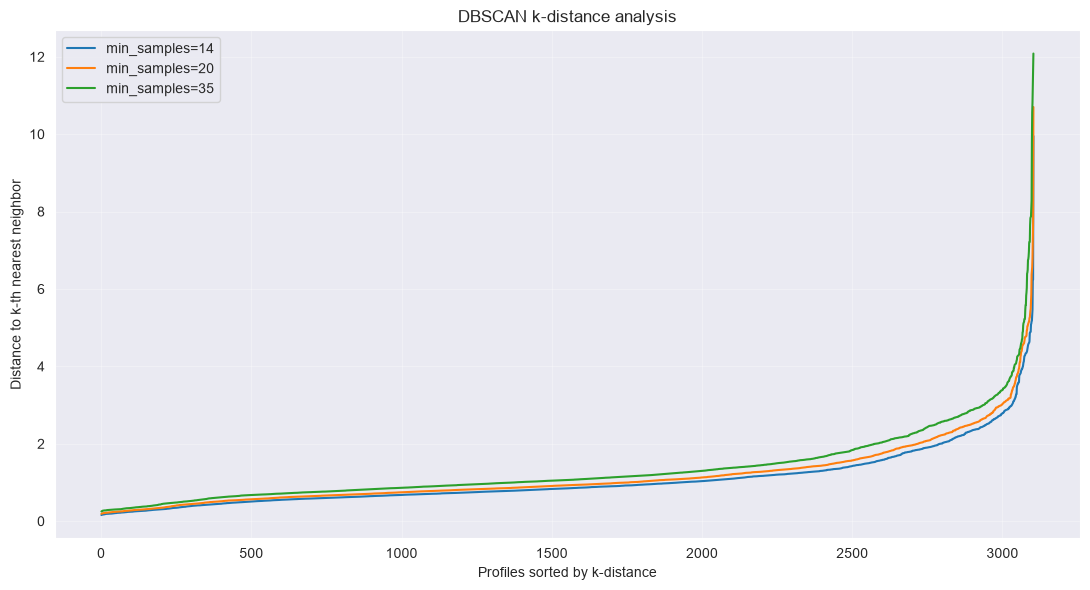

In [141]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

# Evaluate neighborhood distances for DBSCAN
min_samples_values = [14, 20, 35]

max_neighbors = max(min_samples_values) - 1

nn_model = NearestNeighbors(
    n_neighbors=max_neighbors,
    metric="euclidean",
    n_jobs=-1,
)

nn_model.fit(X_active)

# Query training observations while excluding each observation itself
distances, _ = nn_model.kneighbors()

# Calculate distance to the (min_samples - 1)-th other neighbor
k_distance_data = {}

for min_samples in min_samples_values:
    k_distance = distances[:, min_samples - 2]
    k_distance_data[min_samples] = k_distance

# Show distance distribution
distance_summary = []

for min_samples, values in k_distance_data.items():
    distance_summary.append({
        "min_samples": min_samples,
        "min": np.min(values),
        "median": np.median(values),
        "p75": np.quantile(values, 0.75),
        "p90": np.quantile(values, 0.90),
        "p95": np.quantile(values, 0.95),
        "p99": np.quantile(values, 0.99),
        "max": np.max(values),
    })

display(pd.DataFrame(distance_summary).round(4))

# Plot sorted k-distances
plt.figure(figsize=(11, 6))

for min_samples, values in k_distance_data.items():
    sorted_values = np.sort(values)
    plt.plot(
        np.arange(1, len(sorted_values) + 1),
        sorted_values,
        label=f"min_samples={min_samples}",
    )

plt.xlabel("Profiles sorted by k-distance")
plt.ylabel("Distance to k-th nearest neighbor")
plt.title("DBSCAN k-distance analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [142]:
from sklearn.cluster import DBSCAN

# Evaluate DBSCAN using data-driven eps values
percentiles = [0.75, 0.90, 0.95]

dbscan_results = []
dbscan_labels = {}

for min_samples, distances_k in k_distance_data.items():
    for percentile in percentiles:
        eps = np.quantile(distances_k, percentile)

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean",
            n_jobs=-1,
        )

        labels = model.fit_predict(X_active)

        label_series = pd.Series(
            labels,
            index=X_active.index,
            name="cluster",
        )

        # Exclude noise from cluster-size statistics
        cluster_sizes = (
            label_series[label_series != -1]
            .value_counts()
        )

        n_clusters = len(cluster_sizes)
        noise_count = int((labels == -1).sum())
        clustered_count = len(labels) - noise_count

        largest_cluster = (
            int(cluster_sizes.max())
            if n_clusters > 0 else 0
        )

        dbscan_results.append({
            "min_samples": min_samples,
            "eps_percentile": int(percentile * 100),
            "eps": eps,
            "n_clusters": n_clusters,
            "noise_count": noise_count,
            "noise_share_pct": noise_count / len(labels) * 100,
            "clustered_count": clustered_count,
            "largest_cluster": largest_cluster,
            "largest_cluster_share_pct": (
                largest_cluster / len(labels) * 100
            ),
            "median_cluster_size": (
                cluster_sizes.median()
                if n_clusters > 0 else 0
            ),
            "p90_cluster_size": (
                cluster_sizes.quantile(0.90)
                if n_clusters > 0 else 0
            ),
            "core_samples": len(model.core_sample_indices_),
        })

        dbscan_labels[(min_samples, int(percentile * 100))] = (
            label_series
        )

dbscan_summary = pd.DataFrame(dbscan_results)

display(
    dbscan_summary
    .sort_values(["min_samples", "eps"])
    .round(3)
)

,min_samples,eps_percentile,eps,n_clusters,noise_count,noise_share_pct,clustered_count,largest_cluster,largest_cluster_share_pct,median_cluster_size,p90_cluster_size,core_samples
0,14,75,1.245,3,496,15.985,2607,1776,57.235,812.0,1583.2,2327
1,14,90,1.998,1,150,4.834,2953,2953,95.166,2953.0,2953.0,2792
2,14,95,2.505,1,69,2.224,3034,3034,97.776,3034.0,3034.0,2947
3,20,75,1.373,2,494,15.920,2609,1801,58.041,1304.5,1701.7,2327
4,20,90,2.210,1,130,4.189,2973,2973,95.811,2973.0,2973.0,2792
5,20,95,2.709,1,66,2.127,3037,3037,97.873,3037.0,3037.0,2947
6,35,75,1.574,2,469,15.114,2634,1818,58.588,1317.0,1717.8,2327
7,35,90,2.544,1,108,3.481,2995,2995,96.519,2995.0,2995.0,2792
8,35,95,3.057,1,49,1.579,3054,3054,98.421,3054.0,3054.0,2947


In [143]:
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# Compare DBSCAN configurations based on 75th percentile
config_keys = [
    (14, 75),
    (20, 75),
    (35, 75),
]

# 1. Inspect cluster sizes
cluster_rows = []

for key in config_keys:
    labels = dbscan_labels[key]

    counts = labels.value_counts().sort_values(ascending=False)

    for cluster_id, count in counts.items():
        cluster_rows.append({
            "min_samples": key[0],
            "eps_percentile": key[1],
            "cluster": cluster_id,
            "profiles": count,
            "share_pct": count / len(labels) * 100,
            "type": "noise" if cluster_id == -1 else "cluster",
        })

cluster_size_table = pd.DataFrame(cluster_rows)

print("Cluster sizes:")
display(cluster_size_table.round(2))

# 2. Compare noise overlap between configurations
noise_comparison = []

for key_a, key_b in combinations(config_keys, 2):
    labels_a = dbscan_labels[key_a]
    labels_b = dbscan_labels[key_b]

    noise_a = set(labels_a[labels_a == -1].index)
    noise_b = set(labels_b[labels_b == -1].index)

    intersection = len(noise_a & noise_b)
    union = len(noise_a | noise_b)

    noise_comparison.append({
        "config_a": key_a,
        "config_b": key_b,
        "noise_a": len(noise_a),
        "noise_b": len(noise_b),
        "common_noise": intersection,
        "noise_jaccard": intersection / union,
    })

print("\nNoise overlap:")
display(pd.DataFrame(noise_comparison).round(4))

# 3. Compare full cluster assignments using ARI
ari_rows = []

for key_a, key_b in combinations(config_keys, 2):
    labels_a = dbscan_labels[key_a]
    labels_b = dbscan_labels[key_b]

    ari_rows.append({
        "config_a": key_a,
        "config_b": key_b,
        "adjusted_rand_index": adjusted_rand_score(
            labels_a,
            labels_b,
        ),
    })

print("\nCluster assignment similarity:")
display(pd.DataFrame(ari_rows).round(4))

Cluster sizes:


,min_samples,eps_percentile,cluster,profiles,share_pct,type
0,14,75,0,1776,57.23,cluster
1,14,75,1,812,26.17,cluster
2,14,75,-1,496,15.98,noise
3,14,75,2,19,0.61,cluster
4,20,75,0,1801,58.04,cluster
5,20,75,1,808,26.04,cluster
6,20,75,-1,494,15.92,noise
7,35,75,0,1818,58.59,cluster
8,35,75,1,816,26.30,cluster
9,35,75,-1,469,15.11,noise



Noise overlap:


,config_a,config_b,noise_a,noise_b,common_noise,noise_jaccard
0,"(14, 75)","(20, 75)",496,494,463,0.8786
1,"(14, 75)","(35, 75)",496,469,415,0.7545
2,"(20, 75)","(35, 75)",494,469,439,0.8378



Cluster assignment similarity:


,config_a,config_b,adjusted_rand_index
0,"(14, 75)","(20, 75)",0.9599
1,"(14, 75)","(35, 75)",0.9012
2,"(20, 75)","(35, 75)",0.9282


In [144]:
from math import ceil

# Use the representative DBSCAN configuration
dbscan_reference = dbscan_labels[(20, 75)]

dbscan_noise = set(
    dbscan_reference[dbscan_reference == -1].index
)

# Compare all three methods
methods = {
    "Isolation Forest": if_active_scores,
    "LOF": lof_active_scores,
}

comparison_rows = []
common_candidates = {}

for percentage in [1, 2, 5]:
    top_k = ceil(len(X_active) * percentage / 100)

    if_top = set(
        if_active_scores.nlargest(top_k).index
    )
    lof_top = set(
        lof_active_scores.nlargest(top_k).index
    )

    if_lof = if_top & lof_top
    if_dbscan = if_top & dbscan_noise
    lof_dbscan = lof_top & dbscan_noise

    triple = if_top & lof_top & dbscan_noise

    comparison_rows.append({
        "percentage": f"{percentage}%",
        "top_k": top_k,
        "IF_LOF": len(if_lof),
        "IF_DBSCAN": len(if_dbscan),
        "LOF_DBSCAN": len(lof_dbscan),
        "all_three": len(triple),
    })

    common_candidates[percentage] = {
        "IF_LOF": if_lof,
        "IF_DBSCAN": if_dbscan,
        "LOF_DBSCAN": lof_dbscan,
        "all_three": triple,
    }

print("Cross-model agreement:")
display(pd.DataFrame(comparison_rows))

# Inspect profiles detected by all three methods
triple_candidates = common_candidates[5]["all_three"]

if triple_candidates:
    triple_table = pd.DataFrame({
        "if_score": if_active_scores.loc[
            list(triple_candidates)
        ],
        "lof_score": lof_active_scores.loc[
            list(triple_candidates)
        ],
        "dbscan_label": dbscan_reference.loc[
            list(triple_candidates)
        ],
    })

    triple_table = triple_table.join(
        ip_profiles[
            ["flows", "sessions", "as_name", "main_app", "main_app_group"]
        ]
    )

    display(
        triple_table.sort_values(
            "lof_score",
            ascending=False
        ).round(4)
    )
else:
    print("No profiles detected by all three methods in the top 5%.")

Cross-model agreement:


,percentage,top_k,IF_LOF,IF_DBSCAN,LOF_DBSCAN,all_three
0,1%,32,2,32,20,2
1,2%,63,9,58,30,9
2,5%,156,27,127,73,27


,if_score,lof_score,dbscan_label,flows,sessions,as_name,main_app,main_app_group
remote_ip,,,,,,,,
ip-8919,0.5870,3.4597,-1,243,156,"CDNEXT Datacamp Limited, GB",piavpn 54409,VPN
ip-6074,0.5824,2.8546,-1,361,226,"MTW-AS JSC Mediasoft ekspert, RU",bittorrent 49165,P2P
ip-390,0.5624,2.7336,-1,25,19,UNITEDNET EDINAYA SET LIMITED LIABILITY COMPAN...,https 443,Web browsing
ip-1931,0.6513,2.4627,-1,78,9,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing
ip-23150,0.5473,2.3784,-1,1127,317,"Serverius-as Serverius Holding B.V., NL",bittorrent 49165,P2P
ip-2240,0.6235,2.3736,-1,74,10,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing
ip-3642,0.5463,2.3195,-1,571,148,"WILDPARK-AS WildPark Co, UA",bittorrent 49165,P2P
ip-16160,0.5881,2.1288,-1,817,306,"ROSTELECOM-AS PJSC Rostelecom, RU",bittorrent 49165,P2P
ip-208,0.5833,2.1162,-1,1858,279,"AS-SKYNET-SPB SkyNet Ltd., RU",bittorrent 49165,P2P


In [145]:
# Build candidate groups using the top 5% of each ranking
top_k = ceil(len(X_active) * 0.05)

if_top = set(if_active_scores.nlargest(top_k).index)
lof_top = set(lof_active_scores.nlargest(top_k).index)
dbscan_noise = set(
    dbscan_reference[dbscan_reference == -1].index
)

candidate_groups = {
    "consensus_all_three": (
        if_top & lof_top & dbscan_noise
    ),
    "if_specific_noise": (
        (if_top & dbscan_noise) - lof_top
    ),
    "lof_specific_noise": (
        (lof_top & dbscan_noise) - if_top
    ),
    "if_top_clustered": (
        if_top - dbscan_noise
    ),
    "lof_top_clustered": (
        lof_top - dbscan_noise
    ),
}

# Summarize candidate groups
group_summary = pd.DataFrame([
    {
        "group": group_name,
        "profiles": len(ip_set),
        "share_of_active_pct": (
            len(ip_set) / len(X_active) * 100
        ),
    }
    for group_name, ip_set in candidate_groups.items()
])

display(group_summary.round(2))

# Compare application categories across groups
group_rows = []

for group_name, ip_set in candidate_groups.items():
    if not ip_set:
        continue

    categories = (
        ip_profiles.loc[list(ip_set), "main_app_group"]
        .value_counts()
    )

    for category, count in categories.items():
        group_rows.append({
            "group": group_name,
            "app_group": category,
            "profiles": count,
        })

display(
    pd.DataFrame(group_rows)
    .sort_values(["group", "profiles"], ascending=[True, False])
)

# Create a detailed table for all candidates
candidate_ids = set().union(*candidate_groups.values())

candidate_table = pd.DataFrame({
    "if_score": if_active_scores.loc[list(candidate_ids)],
    "lof_score": lof_active_scores.loc[list(candidate_ids)],
    "if_rank": if_active_scores.rank(
        ascending=False
    ).loc[list(candidate_ids)],
    "lof_rank": lof_active_scores.rank(
        ascending=False
    ).loc[list(candidate_ids)],
    "dbscan_label": dbscan_reference.loc[list(candidate_ids)],
})

candidate_table = candidate_table.join(
    ip_profiles[
        ["flows", "sessions", "as_name", "main_app", "main_app_group"]
    ]
)

candidate_table["candidate_group"] = [
    group_name
    for ip in candidate_table.index
    for group_name, ip_set in candidate_groups.items()
    if ip in ip_set
]

display(
    candidate_table.sort_values(
        ["candidate_group", "if_rank"]
    ).round(4)
)

,group,profiles,share_of_active_pct
0,consensus_all_three,27,0.87
1,if_specific_noise,100,3.22
2,lof_specific_noise,46,1.48
3,if_top_clustered,29,0.93
4,lof_top_clustered,83,2.67


,group,app_group,profiles
0,consensus_all_three,P2P,11
1,consensus_all_three,VPN,9
2,consensus_all_three,Web browsing,4
3,consensus_all_three,Network services,1
4,consensus_all_three,E-Mail,1
5,consensus_all_three,"Video, pictures",1
6,if_specific_noise,VPN,41
7,if_specific_noise,Web browsing,18
8,if_specific_noise,P2P,16
9,if_specific_noise,Unknown,13


,if_score,lof_score,if_rank,lof_rank,dbscan_label,flows,sessions,as_name,main_app,main_app_group,candidate_group
remote_ip,,,,,,,,,,,
ip-1559,0.6777,1.6584,3.0,126.0,-1,579,383,"Switch SWITCH, CH",tor 54327,VPN,consensus_all_three
ip-442,0.6768,1.7325,4.0,99.0,-1,157,129,"OVH OVH SAS, FR",tor_cl 54439,VPN,consensus_all_three
ip-3082,0.6743,1.6282,7.0,137.0,-1,556,360,"SUNRISE Sunrise GmbH, CH",tor 54327,VPN,consensus_all_three
ip-12,0.6727,1.6710,8.0,120.0,-1,69,49,"EVANZOAS EVANZO e-commerce GmbH, DE",tor 54327,VPN,consensus_all_three
ip-3289,0.6701,1.6209,10.0,145.0,-1,43,34,"SCHAEFERS Tilman Schaefers, DE",tor 54327,VPN,consensus_all_three
...,...,...,...,...,...,...,...,...,...,...,...
ip-837,0.3987,2.0782,1551.0,35.0,1,45,34,"sg-slashn SlashN Services Pte. Ltd., SG",bittorrent 49165,P2P,lof_top_clustered
ip-2390,0.3976,1.6155,1584.0,146.0,1,52,50,"COMCAST-7922, US",bittorrent 49165,P2P,lof_top_clustered
ip-1838,0.3974,1.9107,1598.0,55.0,1,45,36,"ROGERS-COMMUNICATIONS, CA",bittorrent 49165,P2P,lof_top_clustered


In [146]:
# Inspect the complete three-model consensus group
consensus_ids = sorted(
    candidate_groups["consensus_all_three"]
)

consensus_table = pd.DataFrame({
    "if_score": if_active_scores.loc[consensus_ids],
    "lof_score": lof_active_scores.loc[consensus_ids],
    "if_rank": if_active_scores.rank(
        ascending=False,
        method="min"
    ).loc[consensus_ids],
    "lof_rank": lof_active_scores.rank(
        ascending=False,
        method="min"
    ).loc[consensus_ids],
    "dbscan_label": dbscan_reference.loc[consensus_ids],
})

consensus_table = consensus_table.join(
    ip_profiles[
        [
            "flows",
            "sessions",
            "as_name",
            "main_app",
            "main_app_group",
        ]
    ]
)

display(
    consensus_table.sort_values(
        ["if_rank", "lof_rank"]
    ).round(4)
)

,if_score,lof_score,if_rank,lof_rank,dbscan_label,flows,sessions,as_name,main_app,main_app_group
remote_ip,,,,,,,,,,
ip-1559,0.6777,1.6584,3.0,126.0,-1,579,383,"Switch SWITCH, CH",tor 54327,VPN
ip-442,0.6768,1.7325,4.0,99.0,-1,157,129,"OVH OVH SAS, FR",tor_cl 54439,VPN
ip-3082,0.6743,1.6282,7.0,137.0,-1,556,360,"SUNRISE Sunrise GmbH, CH",tor 54327,VPN
ip-12,0.6727,1.6710,8.0,120.0,-1,69,49,"EVANZOAS EVANZO e-commerce GmbH, DE",tor 54327,VPN
ip-3289,0.6701,1.6209,10.0,145.0,-1,43,34,"SCHAEFERS Tilman Schaefers, DE",tor 54327,VPN
ip-952,0.6555,1.8711,16.0,63.0,-1,25,15,"HETZNER-AS Hetzner Online GmbH, DE",tor 54327,VPN
ip-1931,0.6513,2.4627,17.0,10.0,-1,78,9,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing
ip-2240,0.6235,2.3736,21.0,17.0,-1,74,10,"TWELVE99 Arelion Sweden AB, SE",https 443,Web browsing
ip-17347,0.5939,1.7371,32.0,96.0,-1,742,70,"ERTH-NNOV-AS JSC ""ER-Telecom Holding"", RU",bittorrent 49165,P2P


In [147]:
# Compare consensus candidates with the active IP population

active_features = feature_matrix_core.loc[
    X_active.index
].copy()

# Calculate percentile ranks within the active population
active_percentiles = (
    active_features.rank(
        pct=True,
        method="average"
    ) * 100
)

consensus_percentiles = active_percentiles.loc[
    sorted(consensus_ids)
]

consensus_values = active_features.loc[
    sorted(consensus_ids)
]

feature_comparison = []

for column in active_features.columns:
    percentiles = consensus_percentiles[column]
    values = consensus_values[column]

    feature_comparison.append({
        "feature": column,
        "consensus_median": values.median(),
        "population_median": active_features[column].median(),
        "median_percentile": percentiles.median(),
        "q25_percentile": percentiles.quantile(0.25),
        "q75_percentile": percentiles.quantile(0.75),
        "low_tail_pct": (percentiles <= 10).mean() * 100,
        "high_tail_pct": (percentiles >= 90).mean() * 100,
    })

feature_comparison = pd.DataFrame(feature_comparison)

feature_comparison["extreme_share_pct"] = (
    feature_comparison["low_tail_pct"]
    + feature_comparison["high_tail_pct"]
)

display(
    feature_comparison
    .sort_values("extreme_share_pct", ascending=False)
    .round(3)
)

,feature,consensus_median,population_median,median_percentile,q25_percentile,q75_percentile,low_tail_pct,high_tail_pct,extreme_share_pct
7,upload_ratio,0.618,0.348,90.590,32.839,95.037,22.222,51.852,74.074
5,log_median_duration_ms,9.994,7.962,90.010,83.024,97.792,7.407,51.852,59.259
0,log_flows,5.231,4.007,80.680,46.922,93.530,11.111,37.037,48.148
6,log_n_rports,0.693,0.693,43.667,43.667,95.939,3.704,44.444,48.148
4,log_pkt_size,5.582,5.896,34.612,22.422,80.664,22.222,22.222,44.444
11,retrans_rate,0.019,0.011,61.553,36.884,99.565,0.000,37.037,37.037
12,median_flow_retrans_ratio,0.000,0.000,48.872,48.872,99.742,0.000,37.037,37.037
1,log_flows_per_session,1.125,0.947,67.354,41.307,94.521,3.704,33.333,37.037
3,log_packets_per_flow,2.818,2.374,73.703,33.145,96.858,0.000,33.333,33.333
8,share_anon,0.000,0.000,36.819,36.819,98.308,0.000,33.333,33.333
